# Forgetting through the lens of internal features

The LMEnt setup shows a **learning-forgetting** phenomenon: as training proceeds a
fact can be recalled correctly, then lost, then relearned. This notebook asks
*what happens inside the model* when a fact is forgotten, using the internal
features extracted at **all 13 checkpoints** (15-shot, top-10%% exposure, 1452
facts):

```
feature_extraction/eval_checkpoints.py --num-shots 15 --no-hidden \
    --steps 50000 ... 658032 --top-shared-chunks-pct 10 \
    --output-dir .../15shot_trajectory_top10_internal
```

Each fact now has a **trajectory** of internal signals -- gold-answer probability
and rank, the answer margin, predictive entropy, and the logit-lens resolution
depth -- alongside the binary `correct`. The guiding questions:

1. Do the internals track the wobbling recall curve?
2. Is a fact that is *about to be forgotten* already different, internally, while
   it is still correct?
3. When the flip happens, is it a **cliff** or was the fact always fragile?
4. Is forgetting a loss of **internal knowledge** (retrieval) or only of the
   **readout** (the right answer is there but not emitted)?
5. Can an internal signal *predict* forgetting a checkpoint ahead?

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- visual style (matches the other notebooks) ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
C_SURV, C_FORG = BLUE, ORANGE      # will-survive vs will-forget
pfmt = lambda v, p: f"{v:.0%}"

TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# Long panel over never-excluded facts (excluded is a property of the fact, so the
# set is identical at every checkpoint).
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

# One (n_facts x n_steps) matrix per feature, columns ordered by step.
P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n, 13)
n_facts, n_steps = correct.shape

# relation type + exposure, aligned to the panel
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
props = props.set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

print(f"{n_facts} facts x {n_steps} checkpoints")
print(f"accuracy: {correct[:,0].mean():.1%} @ {steps[0]//1000}k  ->  "
      f"{correct[:,-1].mean():.1%} @ {steps[-1]//1000}k")
forget_transitions = ((correct[:, :-1]) & (~correct[:, 1:])).sum()
print(f"forgetting transitions (correct->wrong): {int(forget_transitions)}")

1310 facts x 13 checkpoints
accuracy: 14.4% @ 50k  ->  41.5% @ 658k
forgetting transitions (correct->wrong): 1003


## 1 — Internals track the wobbling recall curve

Recall (`correct`, `is_top1`) rises overall but dips several times -- the
learning-forgetting signature. The internal confidence of the facts that *are*
correct moves with it: the same checkpoints that lose accuracy also show lower
median gold probability and a more negative answer margin. We plot fractions and
confidence in separate panels (never on a shared axis).

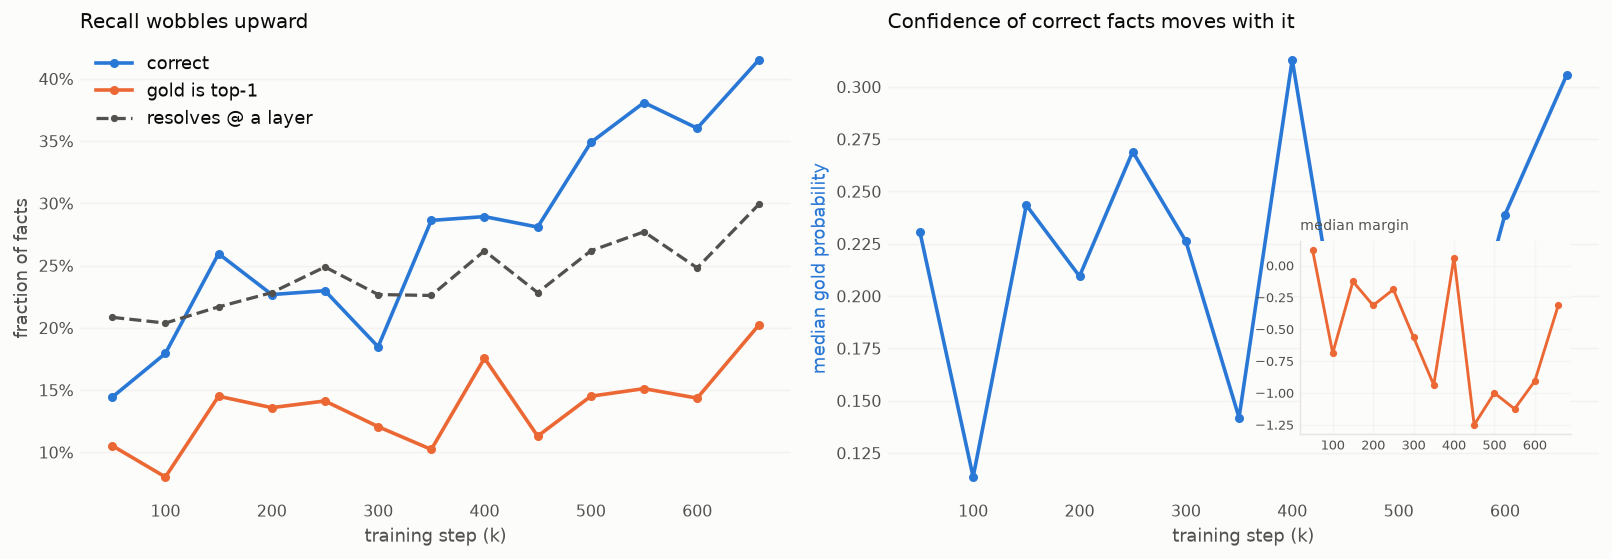

In [2]:
xk = [s / 1000 for s in steps]
frac_correct = correct.mean(axis=0)
frac_top1 = P["is_top1"].to_numpy().mean(axis=0)
frac_resolve = (~np.isnan(P["resolution_depth"].to_numpy())).mean(axis=0)

# confidence among the facts correct at each checkpoint
gp = P["gold_prob"].to_numpy(); am = P["answer_margin"].to_numpy()
med_gp = np.array([np.nanmedian(gp[correct[:, t], t]) for t in range(n_steps)])
med_am = np.array([np.nanmedian(am[correct[:, t], t]) for t in range(n_steps)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax1.plot(xk, frac_correct, color=BLUE, lw=2, marker="o", ms=4, label="correct")
ax1.plot(xk, frac_top1, color=ORANGE, lw=2, marker="o", ms=4, label="gold is top-1")
ax1.plot(xk, frac_resolve, color=INK2, lw=1.8, marker="o", ms=3, ls="--",
         label="resolves @ a layer")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax1.set_ylabel("fraction of facts")
ax1.set_title("Recall wobbles upward", loc="left")
ax1.legend(loc="upper left")

ax2.plot(xk, med_gp, color=BLUE, lw=2, marker="o", ms=4, label="median gold prob.")
ax2b = ax2  # single axis; margin plotted on twin-free secondary via normalization
ax2.set_ylabel("median gold probability", color=BLUE)
ax2.set_title("Confidence of correct facts moves with it", loc="left")
# answer margin shares the story but has a different scale -> its own small panel
axin = ax2.inset_axes([0.58, 0.14, 0.38, 0.42])
axin.plot(xk, med_am, color=ORANGE, lw=1.6, marker="o", ms=3)
axin.set_title("median margin", fontsize=8, color=INK2, loc="left")
axin.tick_params(labelsize=7, length=0)
axin.grid(alpha=0.3)

for ax in (ax1, ax2):
    ax.set_xlabel("training step (k)")
    ax.grid(axis="y", alpha=0.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()

## 2 — Forgetting strikes fragile facts

Take every checkpoint at which a fact is **correct**, and split by what happens
next: does it **survive** to the next checkpoint or get **forgotten**? Comparing
the internal signals *at the current (still-correct) checkpoint* shows the two
groups are already far apart. A fact about to be forgotten is only marginally
correct -- low gold probability, a strongly negative margin, and a gold rank that
is near, but not at, 1.

1003 forget vs 3151 survive events


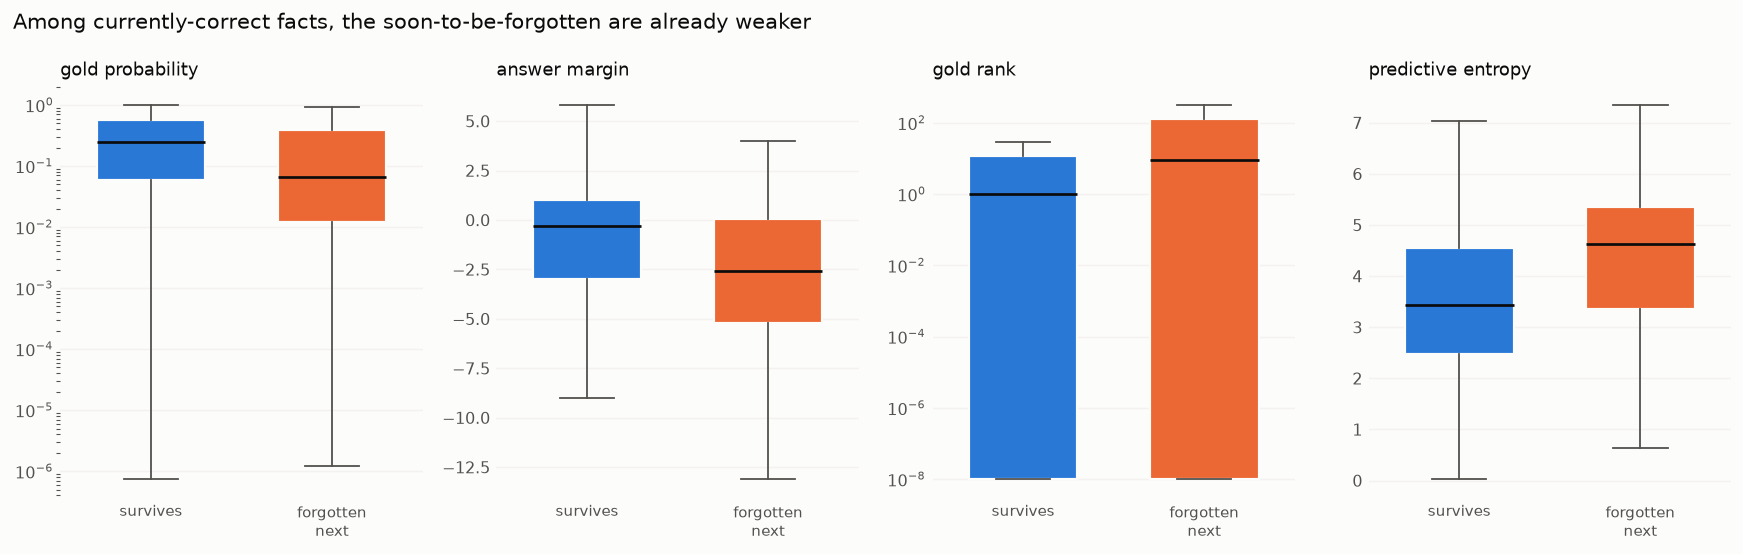

In [3]:
# gather currently-correct observations, labelled by next-step outcome
rows = {k: [] for k in ["gold_prob", "answer_margin", "gold_rank", "pred_entropy"]}
label_forget = []
for t in range(n_steps - 1):
    cur = correct[:, t]
    if not cur.any():
        continue
    for k in rows:
        rows[k].append(P[k].to_numpy()[cur, t])
    label_forget.append(~correct[cur, t + 1])
for k in rows:
    rows[k] = np.concatenate(rows[k])
label_forget = np.concatenate(label_forget)

PANELS = [("gold_prob", "gold probability", True),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank", True),
          ("pred_entropy", "predictive entropy", False)]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (k, label, log) in zip(axes, PANELS):
    v = rows[k]
    surv = v[~label_forget]; forg = v[label_forget]
    if log:
        surv = np.clip(surv, 1e-8, None); forg = np.clip(forg, 1e-8, None)
    bp = ax.boxplot([surv, forg], patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color=INK, lw=1.5),
                    whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, col in zip(bp["boxes"], (C_SURV, C_FORG)):
        patch.set_facecolor(col); patch.set_edgecolor(SURF); patch.set_linewidth(1.2)
    if log:
        ax.set_yscale("log")
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"], fontsize=8.5)
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Among currently-correct facts, the soon-to-be-forgotten are already weaker",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()
print(f"{label_forget.sum()} forget vs {(~label_forget).sum()} survive events")

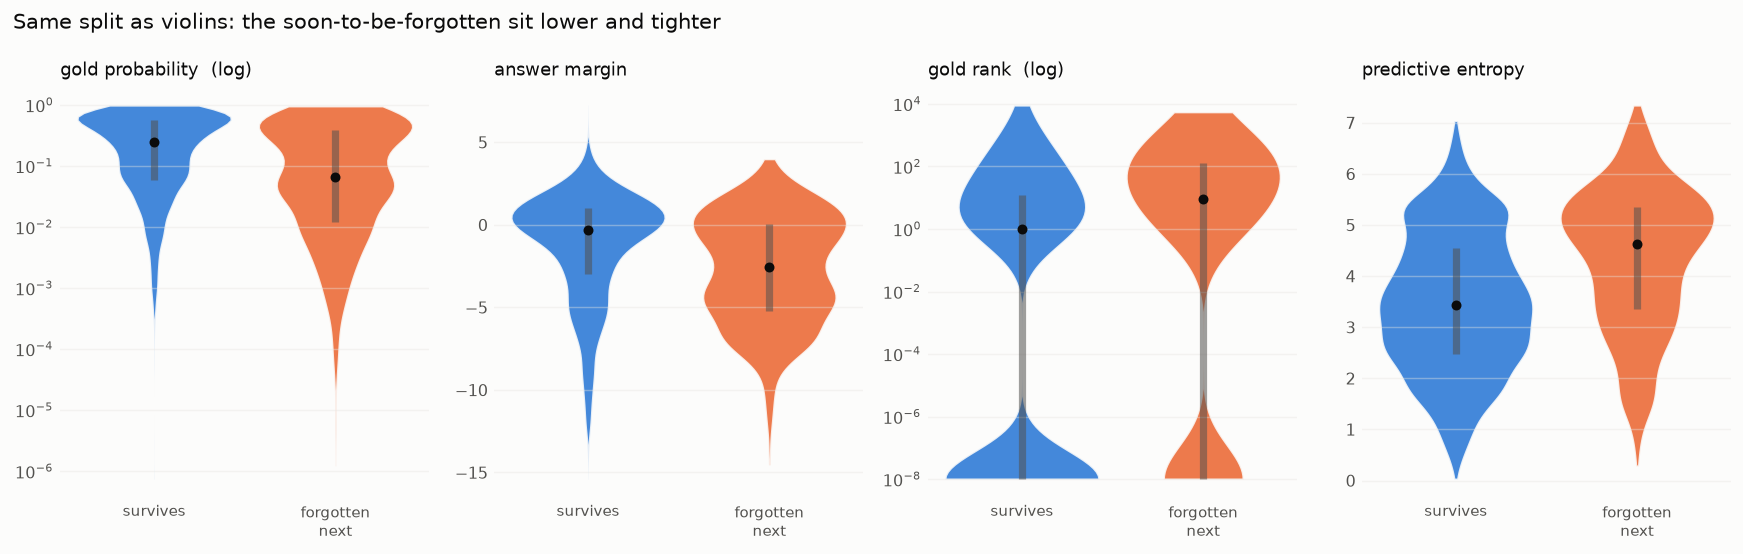

In [4]:
# same comparison as violins (KDE of the full distribution instead of quartile boxes)
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.3))
for ax, (k, label, log) in zip(axes, PANELS):
    v = rows[k]
    surv = v[~label_forget]; forg = v[label_forget]
    if log:                                   # KDE in log space -> undistorted shape
        surv = np.log10(np.clip(surv, 1e-8, None))
        forg = np.log10(np.clip(forg, 1e-8, None))
    parts = ax.violinplot([surv, forg], positions=[1, 2], widths=0.85,
                          showextrema=False)
    for body, col in zip(parts["bodies"], (C_SURV, C_FORG)):
        body.set_facecolor(col); body.set_edgecolor(SURF)
        body.set_alpha(0.88); body.set_linewidth(1.2)
    # median dot + IQR bar overlaid, so the summary the boxplot showed stays readable
    for pos, d in zip((1, 2), (surv, forg)):
        q1, med, q3 = np.percentile(d, [25, 50, 75])
        ax.vlines(pos, q1, q3, color=INK2, lw=4, alpha=0.55, zorder=2)
        ax.plot(pos, med, "o", color=INK, ms=4.5, zorder=3)
    if log:
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda y, _: f"$10^{{{int(round(y))}}}$"))
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"], fontsize=8.5)
    ax.set_title(label + ("  (log)" if log else ""), loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Same split as violins: the soon-to-be-forgotten sit lower and tighter",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 3 — No cliff: forgotten facts were fragile all along

Aligning on the forgetting event (τ = 0 is the last correct checkpoint, τ = +1 the
first wrong one) shows the internal confidence of these facts is **flat and low**
across the whole window -- there is no sharp collapse at the flip. They hover near
the decision boundary and tip over. The dashed line is the median for facts that
stay correct: a different regime entirely.

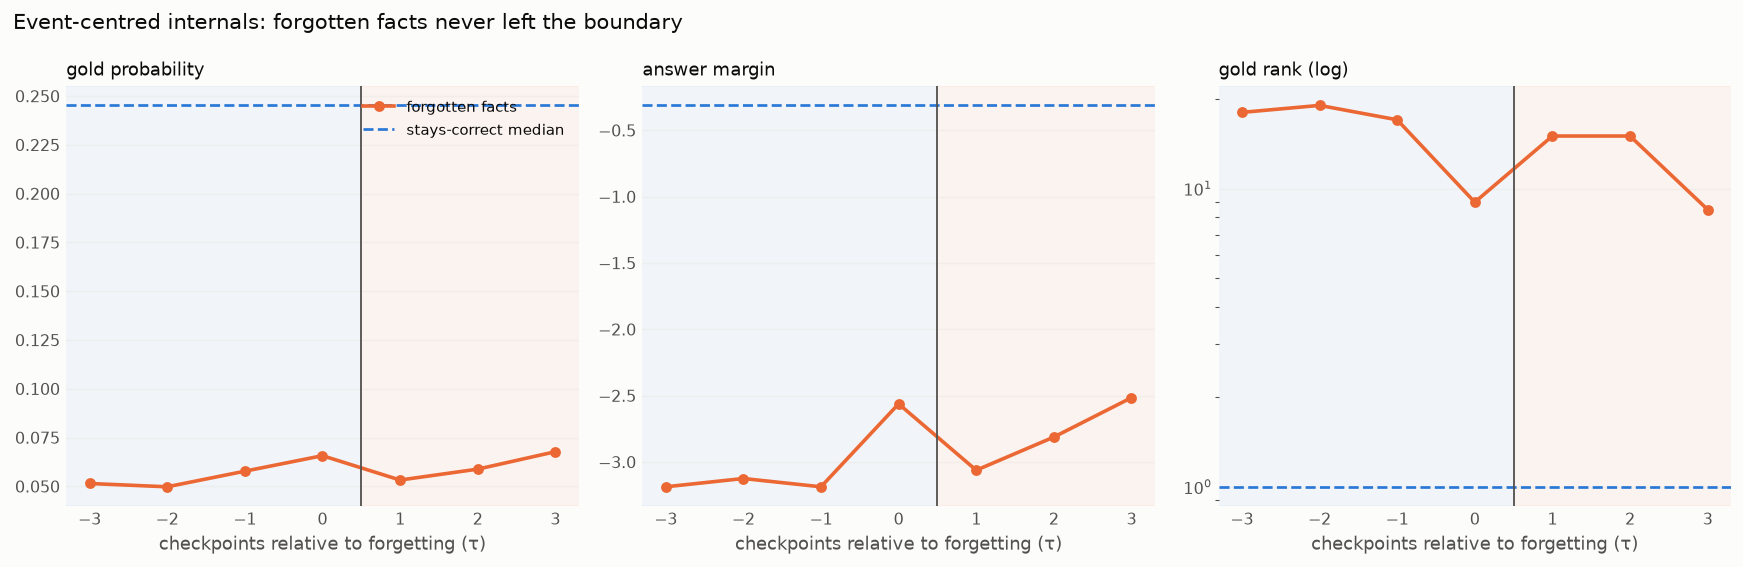

In [5]:
offsets = range(-3, 4)
def event_curve(feat):
    M = P[feat].to_numpy()
    med = {}
    for tau in offsets:
        vals = []
        for t in range(n_steps - 1):
            forget = correct[:, t] & (~correct[:, t + 1])
            j = t + tau
            if 0 <= j < n_steps:
                vals.append(M[forget, j])
        med[tau] = np.nanmedian(np.concatenate(vals)) if vals else np.nan
    return np.array([med[o] for o in offsets])

# survivor reference: median among currently-correct-and-surviving
surv_ref = {k: np.nanmedian(rows[k][~label_forget]) for k in
            ["gold_prob", "answer_margin", "gold_rank"]}

CURVES = [("gold_prob", "gold probability", False),
          ("answer_margin", "answer margin", False),
          ("gold_rank", "gold rank (log)", True)]
xo = list(offsets)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for ax, (k, label, log) in zip(axes, CURVES):
    y = event_curve(k)
    ax.axvspan(-3.5, 0.5, color=BLUE, alpha=0.05)      # labelled correct
    ax.axvspan(0.5, 3.5, color=ORANGE, alpha=0.06)     # labelled wrong
    ax.plot(xo, y, color=C_FORG, lw=2, marker="o", ms=5, label="forgotten facts")
    ax.axhline(surv_ref[k], color=C_SURV, ls="--", lw=1.5, label="stays-correct median")
    ax.axvline(0.5, color=INK2, lw=1)
    if log:
        ax.set_yscale("log")
    ax.set_xlim(-3.3, 3.3)
    ax.set_xlabel("checkpoints relative to forgetting (τ)")
    ax.set_title(label, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.4); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Event-centred internals: forgotten facts never left the boundary",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 4 — Retrieval failure or readout failure?

At the flip, is the answer *gone from the model* or just *not emitted*? For the
forgotten facts we compare the last-correct checkpoint (τ = 0) with the first-wrong
one (τ = +1). Both the output signal (`is_top1`) and the internal one (still
resolves at some layer) drop -- but note how **low they already are at τ = 0**:
most of these facts were correct by the lenient substring match without gold ever
being the top token or resolving internally. Forgetting is mostly the tipping of
facts that were **never robustly stored**, not the erasure of solid knowledge.

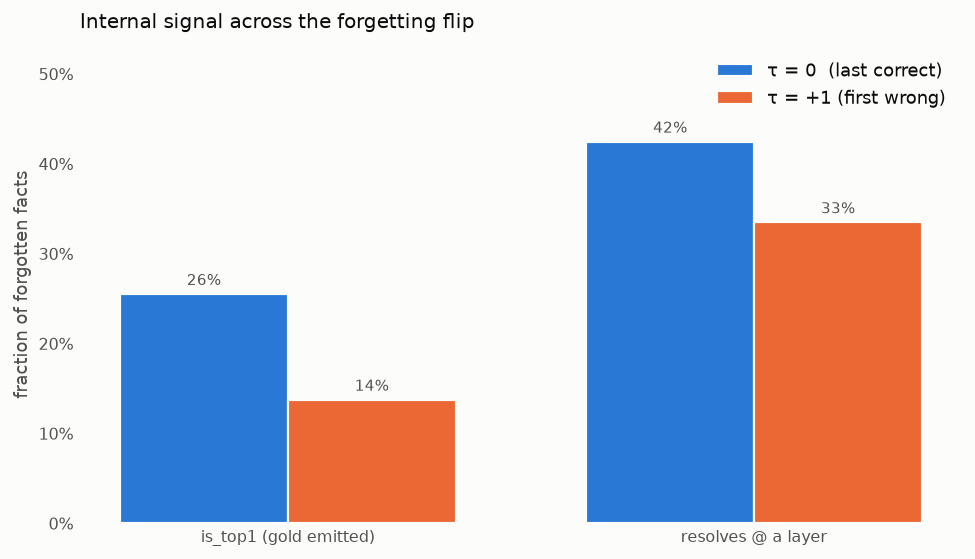

In [6]:
def rate_at(mask_feat, tau, kind):
    vals = []
    M = P[mask_feat].to_numpy()
    for t in range(n_steps - 1):
        forget = correct[:, t] & (~correct[:, t + 1])
        j = t + tau
        if 0 <= j < n_steps:
            col = M[forget, j]
            if kind == "resolve":
                vals.append(~np.isnan(col))
            else:
                vals.append(col.astype(float))
    return np.nanmean(np.concatenate(vals))

metrics = ["is_top1 (gold emitted)", "resolves @ a layer"]
at0 = [rate_at("is_top1", 0, "bool"), rate_at("resolution_depth", 0, "resolve")]
at1 = [rate_at("is_top1", 1, "bool"), rate_at("resolution_depth", 1, "resolve")]

fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(metrics)); w = 0.36
ax.bar(x - w/2, at0, w, color=BLUE, edgecolor=SURF, linewidth=1.2,
       label="τ = 0  (last correct)")
ax.bar(x + w/2, at1, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
       label="τ = +1 (first wrong)")
for xi, (a, b) in enumerate(zip(at0, at1)):
    ax.text(xi - w/2, a + 0.01, f"{a:.0%}", ha="center", fontsize=8.5, color=INK2)
    ax.text(xi + w/2, b + 0.01, f"{b:.0%}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, metrics)
ax.set_ylim(0, max(at0 + at1) * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("fraction of forgotten facts")
ax.set_title("Internal signal across the forgetting flip", loc="left", pad=10)
ax.legend(loc="upper right"); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

## 5 — Internal confidence predicts forgetting a checkpoint ahead

Putting it together: bin every currently-correct observation by its gold
probability and measure how often it is forgotten at the next checkpoint. The
relationship is monotonic -- the weakest decile is forgotten ~3x as often as the
strongest. A single scalar (gold probability, or the answer margin) gives a real,
if modest, one-step-ahead warning (AUC ≈ 0.64); being top-1 roughly halves the
risk.

AUC  gold_prob -> forget      : 0.638
AUC  answer_margin -> forget  : 0.632
P(forget | gold is top-1)     : 18.9%
P(forget | gold not top-1)    : 32.6%


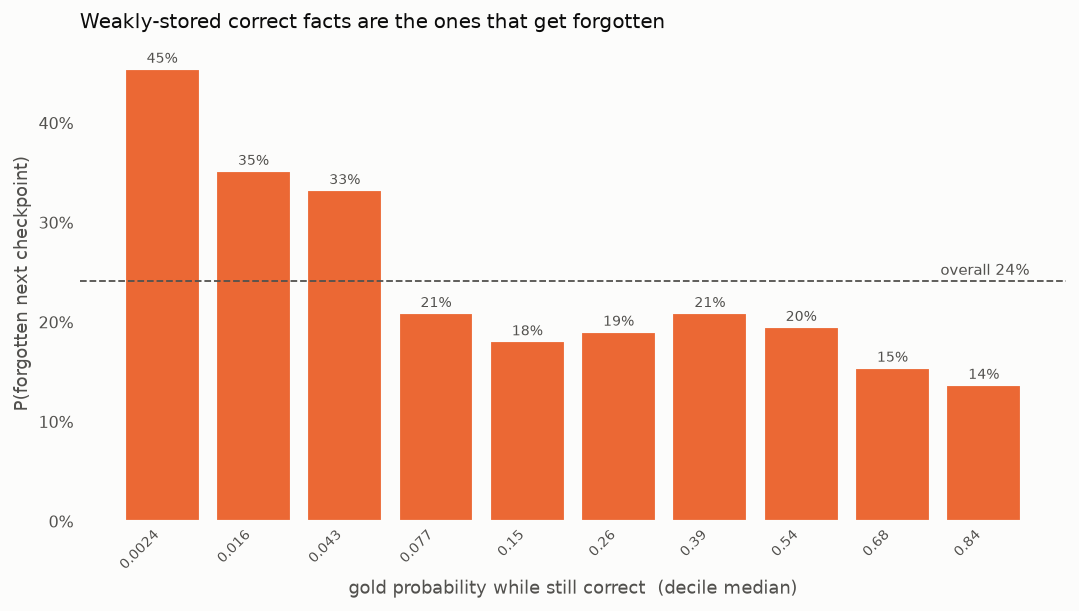

In [7]:
from scipy.stats import rankdata
def auc(score, y):                       # P(score ranks a positive above a negative)
    m = ~np.isnan(score)
    score, y = score[m], y[m].astype(bool)
    r = rankdata(score)
    n1 = y.sum(); n0 = (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

gpv = rows["gold_prob"]; amv = rows["answer_margin"]
auc_gp = auc(-gpv, label_forget)          # lower prob -> more likely forgotten
auc_am = auc(-amv, label_forget)

m = ~np.isnan(gpv)
dec = pd.qcut(gpv[m], 10, labels=False, duplicates="drop")
lab = label_forget[m]
gpm = gpv[m]
p_forget = np.array([lab[dec == d].mean() for d in range(dec.max() + 1)])
gp_med = np.array([np.median(gpm[dec == d]) for d in range(dec.max() + 1)])

fig, ax = plt.subplots(figsize=(8.4, 4.8))
xb = np.arange(len(p_forget))
ax.bar(xb, p_forget, color=ORANGE, edgecolor=SURF, linewidth=1.2, width=0.82)
for i, v in enumerate(p_forget):
    ax.text(i, v + 0.006, f"{v:.0%}", ha="center", fontsize=8, color=INK2)
ax.axhline(label_forget.mean(), color=INK2, ls="--", lw=1)
ax.text(len(p_forget) - 0.5, label_forget.mean() + 0.006,
        f"overall {label_forget.mean():.0%}", ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(xb, [f"{v:.2g}" for v in gp_med], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("gold probability while still correct  (decile median)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_ylabel("P(forgotten next checkpoint)")
ax.set_title("Weakly-stored correct facts are the ones that get forgotten",
             loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

print(f"AUC  gold_prob -> forget      : {auc_gp:.3f}")
print(f"AUC  answer_margin -> forget  : {auc_am:.3f}")
print(f"P(forget | gold is top-1)     : {label_forget[rows['gold_rank']==1].mean():.1%}")
print(f"P(forget | gold not top-1)    : {label_forget[rows['gold_rank']>1].mean():.1%}")

## 6 — Forgetting by relation type

Does the fragility story play out differently across relations? We measure a
per-relation **forgetting hazard** -- the probability that a fact correct at one
checkpoint is wrong at the next, pooled over all checkpoints -- and connect it to
the same internal signal used above.

- **6a** ranks relations by hazard. Some are stable (`capital`, `capital of` ~17%),
  others churn constantly (`genre`, `country` > 60%). Relations with few correct
  observations are greyed out -- their hazard is noisy.
- **6b** shows *when* each relation wobbles: a checkpoint-by-checkpoint accuracy
  heatmap. Stable relations stay dark across training; volatile ones flicker.
- **6c** ties it back to the mechanism: relations whose correct facts are stored
  with low gold probability (fragile) have the highest hazard -- the same
  weak-storage → forgetting link as at the per-fact level, now across relations.

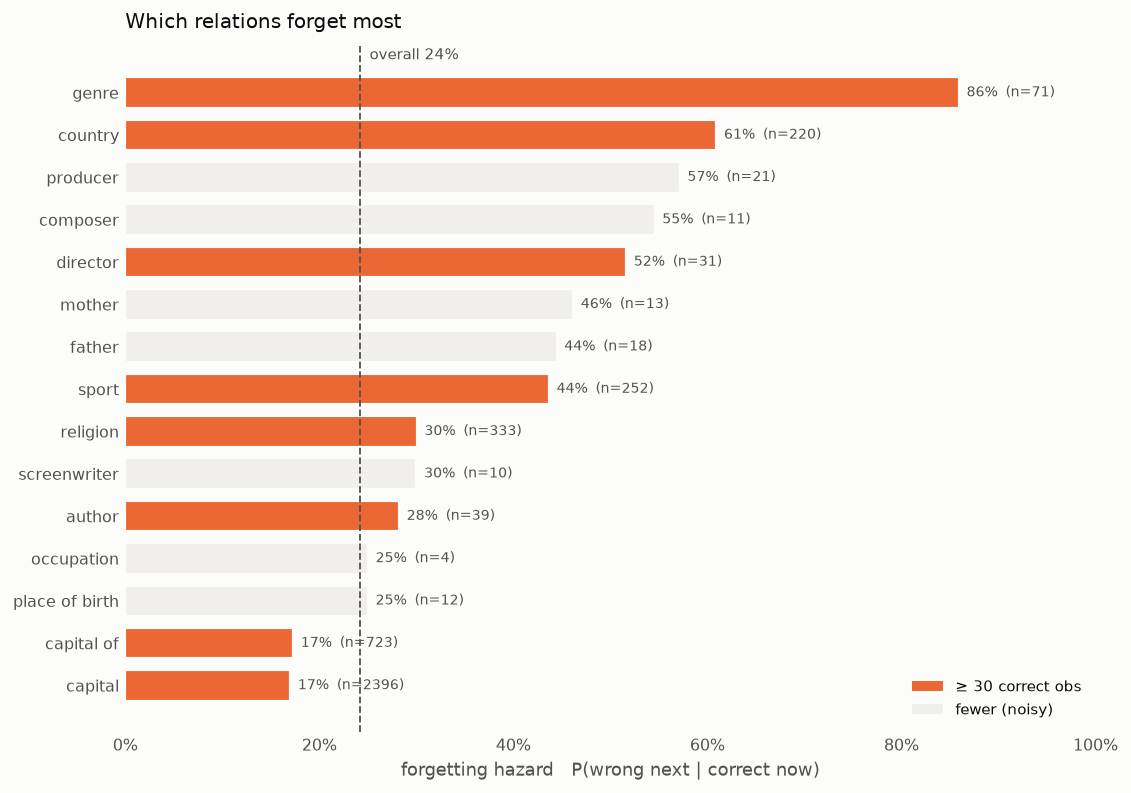

In [8]:
# 6a — forgetting hazard by relation type
# hazard = P(wrong next checkpoint | correct now), pooled over all checkpoints.
MIN_OBS = 30                       # a relation needs this many correct (fact,ckpt) obs to be reliable
gp_all = P["gold_prob"].to_numpy()
recs = []
for p in np.unique(prop):
    m = prop == p
    cur = correct[m, :-1]; nxt = correct[m, 1:]
    n_obs = int(cur.sum())                                   # correct (fact, ckpt) observations
    gpc = gp_all[m, :][correct[m, :]]
    recs.append(dict(prop=p, n_facts=int(m.sum()), n_obs=n_obs,
                     hazard=(cur & ~nxt).sum() / n_obs if n_obs else np.nan,
                     gp_correct=np.nanmedian(gpc) if len(gpc) else np.nan,
                     exposure=np.median(exposure[m])))
prop_stats = pd.DataFrame(recs).sort_values("hazard").reset_index(drop=True)
overall_hz = (correct[:, :-1] & ~correct[:, 1:]).sum() / correct[:, :-1].sum()

fig, ax = plt.subplots(figsize=(8.8, 6.2))
yp = np.arange(len(prop_stats))
reliable = prop_stats["n_obs"] >= MIN_OBS
ax.barh(yp, prop_stats["hazard"],
        color=[ORANGE if r else NEUTRAL for r in reliable],
        edgecolor=SURF, linewidth=1.2, height=0.72)
for i, row in prop_stats.iterrows():
    ax.text(row["hazard"] + 0.008, i, f"{row['hazard']:.0%}  (n={row['n_obs']})",
            va="center", fontsize=8, color=INK2)
ax.axvline(overall_hz, color=INK2, ls="--", lw=1)
ax.text(overall_hz, len(prop_stats) - 0.3, f"  overall {overall_hz:.0%}",
        color=INK2, fontsize=8.5, va="bottom")
ax.set_yticks(yp, prop_stats["prop"], fontsize=9)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("forgetting hazard   P(wrong next | correct now)")
ax.set_title("Which relations forget most", loc="left", pad=10)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=ORANGE, label=f"≥ {MIN_OBS} correct obs"),
                   Patch(facecolor=NEUTRAL, label="fewer (noisy)")],
          loc="lower right", fontsize=8.5)
fig.tight_layout()

Most stable: capital (17%), capital of (17%), author (28%).
Most volatile: genre (86%), country (61%), producer (57%).
Relations with fewer than 30 correct observations (occupation, screenwriter, composer, mother, …) are greyed out and labeled with their n, since their hazard is noisy.

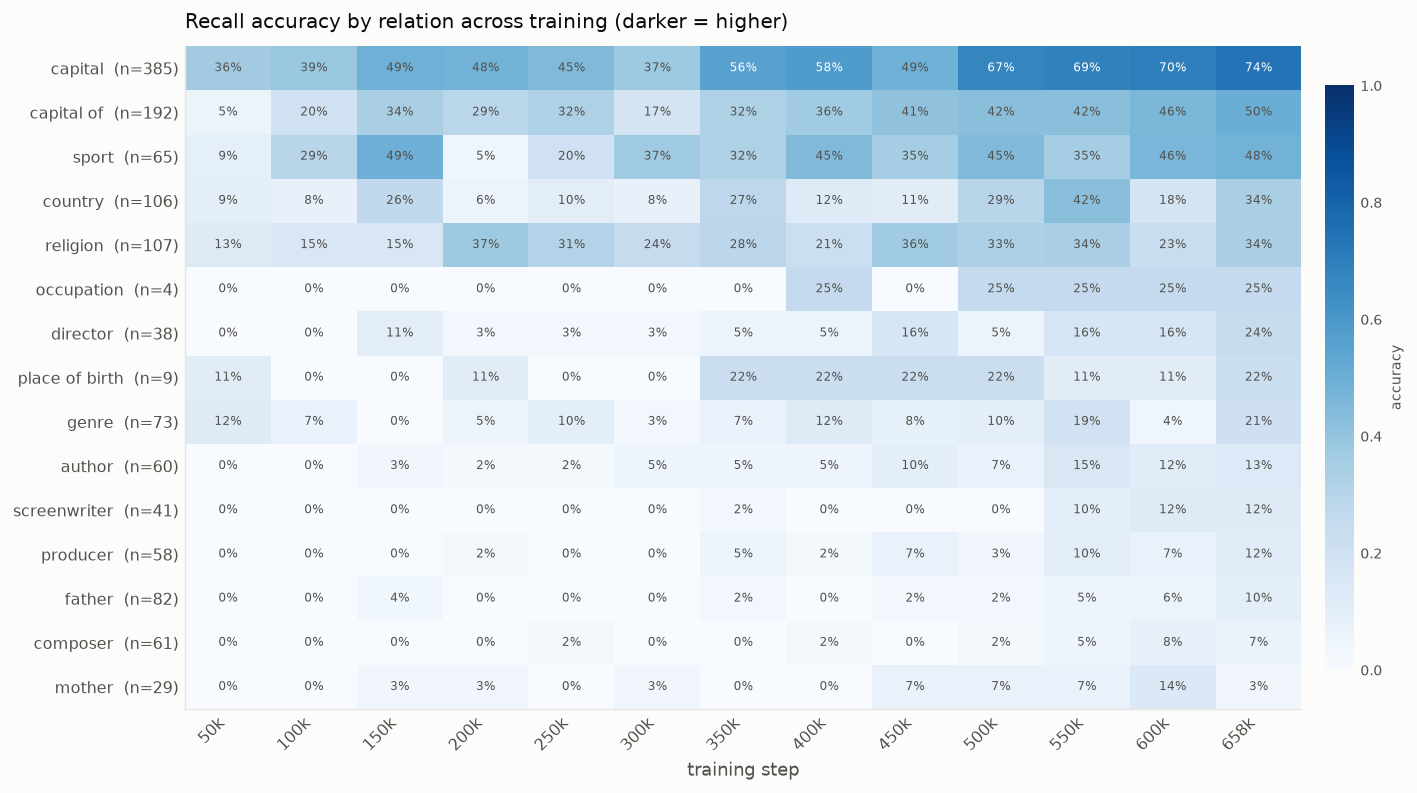

In [9]:
# 6b — when each relation wobbles: accuracy heatmap across training
props_u = np.unique(prop)
acc = np.array([[correct[prop == p, t].mean() for t in range(n_steps)]
                for p in props_u])
row_order = np.argsort(-acc[:, -1])            # most-recalled relations on top
acc = acc[row_order]; props_u = props_u[row_order]

fig, ax = plt.subplots(figsize=(11, 6.2))
im = ax.imshow(acc, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_steps), [f"{s//1000}k" for s in steps], rotation=45, ha="right")
ax.set_yticks(range(len(props_u)),
              [f"{p}  (n={(prop==p).sum()})" for p in props_u], fontsize=9)
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        v = acc[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5,
                color="white" if v > 0.55 else INK2)
ax.set_xlabel("training step")
ax.set_title("Recall accuracy by relation across training (darker = higher)",
             loc="left", pad=10)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("accuracy", fontsize=8); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)
fig.tight_layout()

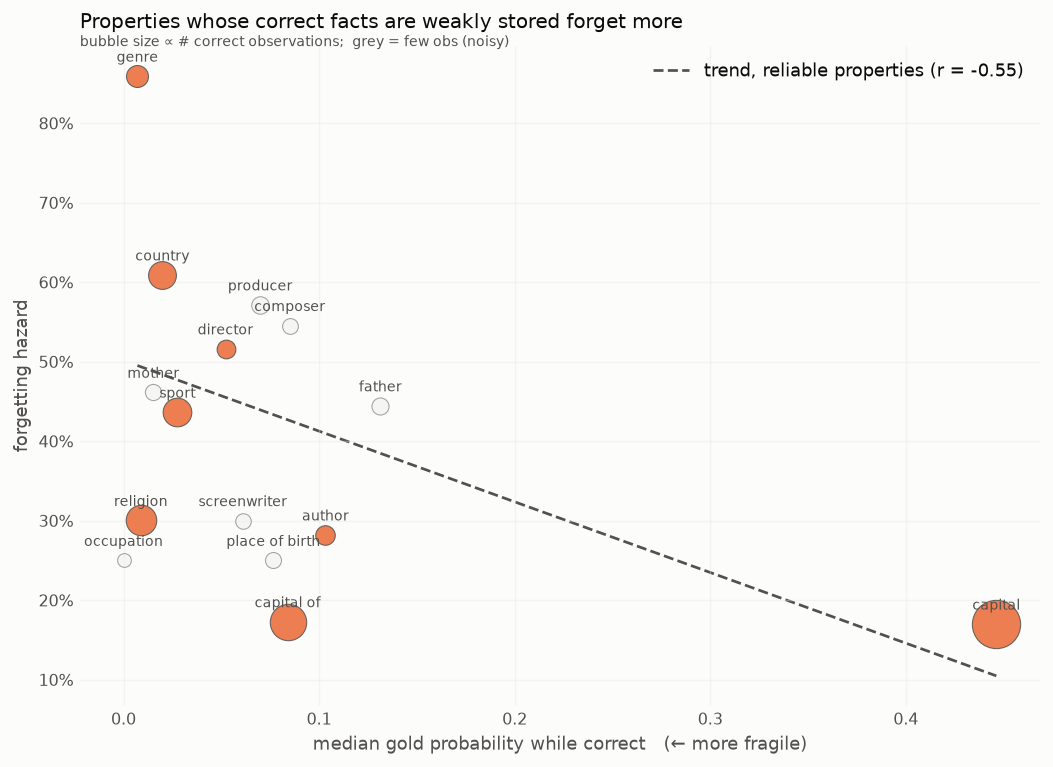

In [10]:
# 6c — the fragility mechanism holds across relations
rel = prop_stats[prop_stats["n_obs"] >= MIN_OBS]      # fit only where hazard is reliable
b, a = np.polyfit(rel["gp_correct"], rel["hazard"], 1)
r = np.corrcoef(rel["gp_correct"], rel["hazard"])[0, 1]
xs = np.linspace(rel["gp_correct"].min(), rel["gp_correct"].max(), 40)

fig, ax = plt.subplots(figsize=(8.2, 6))
ax.plot(xs, a + b * xs, color=INK2, ls="--", lw=1.5, zorder=1,
        label=f"trend, reliable properties (r = {r:.2f})")
for _, row in prop_stats.iterrows():
    reli = row["n_obs"] >= MIN_OBS
    ax.scatter(row["gp_correct"], row["hazard"],
               s=np.sqrt(row["n_obs"]) * 14 + 30,
               color=ORANGE if reli else NEUTRAL, alpha=0.85 if reli else 0.5,
               edgecolor=INK2, linewidth=0.6, zorder=2)
    ax.annotate(row["prop"], (row["gp_correct"], row["hazard"]), fontsize=7.5,
                color=INK2, xytext=(0, 8), textcoords="offset points", ha="center")
ax.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax.set_xlabel("median gold probability while correct   (← more fragile)")
ax.set_ylabel("forgetting hazard")
ax.set_title("Properties whose correct facts are weakly stored forget more",
             loc="left", pad=10)
ax.grid(alpha=0.35)
ax.legend(loc="upper right")
ax.text(0.0, 1, "bubble size ∝ # correct observations;  grey = few obs (noisy)",
        transform=ax.transAxes, fontsize=8, color=INK2)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()

---
# ═══════════════════════ NEW WORK STARTS HERE ═══════════════════════

# Part II — literature grounding and follow-up tests

Everything above this line is the original analysis. Everything below is new:
a short literature review, then a set of **follow-up tests**, each one labelled
with the paper it leans on. Section numbering continues from §6.

## A short literature overview

**Forgetting as a measurable training-dynamics event.** The correct→wrong
transition used throughout this notebook is the *forgetting event* of
**Toneva et al. (2019)**, *An Empirical Study of Example Forgetting during Deep
Neural Network Learning* (ICLR) — they count, per example, how often it flips from
correct to incorrect over training, and find a large population of *unforgettable*
examples that are never lost. **Maini et al. (2022)**, *Characterizing Datapoints
via Second-Split Forgetting* (NeurIPS), use the *time* of forgetting to separate
genuinely hard/rare examples from mislabelled ones. **Swayamdipta et al. (2020)**,
*Dataset Cartography* (EMNLP), map examples by the **mean** and **standard
deviation** of the gold probability across training and read off easy / hard /
ambiguous regions. §7 below is that map, drawn for facts instead of examples.

**Forgetting during LM pretraining specifically.** **Tirumala et al. (2022)**,
*Memorization Without Overfitting* (NeurIPS), track memorisation and forgetting
curves across pretraining and find forgetting baselines that scale with model size.
**Jagielski et al. (2023)**, *Measuring Forgetting of Memorized Training Examples*
(ICLR), show that examples seen early are progressively forgotten. Closest to this
project, **Chang et al. (2024)**, *How Do Large Language Models Acquire Factual
Knowledge During Pretraining?* (NeurIPS), inject facts into pretraining and fit
**decay curves** to the subsequent forgetting, finding acquisition happens in
sharp jumps followed by power-law-ish decay, modulated by batch size and duplication.
**Zucchet et al. (2025)**, *How Do Language Models Learn Facts?*, describe a
three-phase dynamic (plateau → rapid acquisition → degradation). The LMEnt
learning–forgetting wobble analysed here is the same phenomenon with the training
corpus fully known.

**What forgetting looks like inside the network.** **Ramasesh et al. (2021)**,
*Anatomy of Catastrophic Forgetting: Hidden Representations and Task Semantics*
(ICLR), is the reference point for asking the question representationally: they
find forgetting is concentrated in *later* layers and is strongly modulated by
semantic similarity between what is learned and what is lost. **Davari et al.
(2022)**, *Probing Representation Forgetting* (CVPR), draw the crucial distinction
this notebook's §4 gropes toward: **observed forgetting** (the read-out fails) is
much larger than **representation forgetting** (a linear probe on frozen features
still recovers the answer). **Kotha et al. (2024)**, *Understanding Catastrophic
Forgetting in Language Models via Implicit Inference* (ICLR), argue much apparent
forgetting is not erasure at all but a shift in which implicit task the model
infers — a competing answer takes over. §9 tests exactly that fork.

**Where factual recall lives.** **Geva et al. (2021, 2022)** established FFN layers
as key–value memories that promote concepts in vocabulary space; **Meng et al.
(2022)** (ROME) localised factual associations to mid-stack MLPs at the **last
subject token** via causal tracing; **Geva et al. (2023)**, *Dissecting Recall of
Factual Associations*, split recall into **subject enrichment** at the subject
position and **attribute extraction** to the last position. That two-stage picture
is why the extraction stored both an `answer` and a `subject_last` position, and it
predicts *where in the stack* forgetting should first become visible — §8.

**Reading the stack.** The `resolution_depth` / `gold_rank_by_layer` features are
the **logit lens** (**nostalgebraist, 2020**), refined by **Belrose et al. (2023)**,
*Eliciting Latent Predictions with the Tuned Lens*, whose main warning is that the
raw logit lens is biased at early layers and at the final layer. **Lad et al.
(2024)**, *The Remarkable Robustness of LLMs: Stages of Inference*, give the
now-standard four-stage reading of depth that §8 interprets against.

**Active neurons.** **Dai et al. (2022)**, *Knowledge Neurons in Pretrained
Transformers* (ACL), and **Gurnee et al. (2023)**, *Finding Neurons in a Haystack*,
localise facts to small neuron sets; **Voita et al. (2024)**, *Neurons in Large
Language Models: Dead, N-gram, Positional* (ACL Findings), document how activation
sparsity varies with depth and training. **Kim et al. (2025)**, *Knowledge Entropy
Decay during Language Model Pretraining Hinders New Knowledge Acquisition* (ICLR),
is the most directly relevant: they measure how *broadly* the FFN memories are
engaged and show that this breadth **decays** over pretraining, and that low
breadth predicts more forgetting. The `mlp_participation_by_layer` column is a
close proxy — tested in the companion notebook.

**Why some facts are fragile in the first place.** **Mallen et al. (2023)**,
*When Not to Trust Language Models* (ACL), show factual recall is governed by
subject **popularity**; **Elhage et al. (2022)**, *Toy Models of Superposition*,
predict that features packed into a shared space **interfere**, which is the
mechanism behind a fragility that is about crowding rather than weakness.

## What the new tests are

| § | Test | Leans on |
|---|------|----------|
| 7 | Fact cartography: confidence × variability × forgetting count | Swayamdipta et al. 2020; Toneva et al. 2019 |
| 8 | Logit-lens depth profile of survive vs. forget-next | nostalgebraist 2020; Belrose et al. 2023; Lad et al. 2024; Geva et al. 2023 |
| 9 | Is the flip **decay** or **takeover** by a competitor? | Kotha et al. 2024; Chang et al. 2024 |
| 10 | Noise-floor null: is "forgetting" just a stochastic read-out? | Toneva et al. 2019; Maini et al. 2022 |


In [11]:
# --- shared loader for the new sections: columns the original §1 panel did not keep ---
# (§1 built `P` from FEATURES only; §§7-10 also need top1_prob, gold_rank_by_layer, ...)
EXTRA = ["top1_prob", "pred_entropy", "gold_prob", "generation"]
_frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].set_index("id").reindex(ids)
    _frames.append(d)
NEWP = {c: np.column_stack([fr[c].to_numpy() for fr in _frames]) for c in EXTRA}
# per-layer logit-lens ranks: (n_facts, n_steps, n_layer_boundaries)
GRL = np.stack([np.stack(fr["gold_rank_by_layer"].to_numpy()).astype(float)
                for fr in _frames], axis=1)
n_layers = GRL.shape[2]
print(f"loaded extra columns for {len(ids)} scoreable facts x {n_steps} checkpoints")
print(f"gold_rank_by_layer -> {GRL.shape}  ({n_layers} layer boundaries)")

PURPLE = "#7b5ea7"      # third categorical hue; BLUE/ORANGE/PURPLE pass the CVD checks
                        # (RED is deliberately never paired with ORANGE: OKLab dE 3.6 under
                        #  deuteranopia -- indistinguishable)


loaded extra columns for 1310 scoreable facts x 13 checkpoints
gold_rank_by_layer -> (1310, 13, 19)  (19 layer boundaries)


## 7 — Fact cartography: where do forgotten facts live?

**Paper:** Swayamdipta et al. (2020), *Dataset Cartography: Mapping and Diagnosing
Datasets with Training Dynamics* (EMNLP); Toneva et al. (2019) for the event count.

Cartography plots every example by its **confidence** (mean gold probability across
checkpoints) and **variability** (its standard deviation), and finds three regions:
*easy* (high confidence, low variability), *hard* (low, low) and **ambiguous**
(middling confidence, **high** variability) — the region the paper associates with
unstable learning.

The natural prediction is that forgetting concentrates in the ambiguous,
high-variability region. Testing it here needs one correction the original paper
does not need: for a bounded probability, the standard deviation is mechanically
capped by the mean (a fact averaging 0.02 *cannot* have σ = 0.3), so raw
variability is confounded with confidence. We therefore report both raw
variability and the scale-free **coefficient of variation** (σ/μ).

never forgotten  n= 140  confidence=0.1875  σ=0.1075  σ/μ=0.537
1 event          n= 324  confidence=0.1149  σ=0.0675  σ/μ=0.535
≥2 events        n= 279  confidence=0.0567  σ=0.0294  σ/μ=0.620
corr(σ,   #forget | ever-correct) = -0.090
corr(σ/μ, #forget | ever-correct) = +0.101


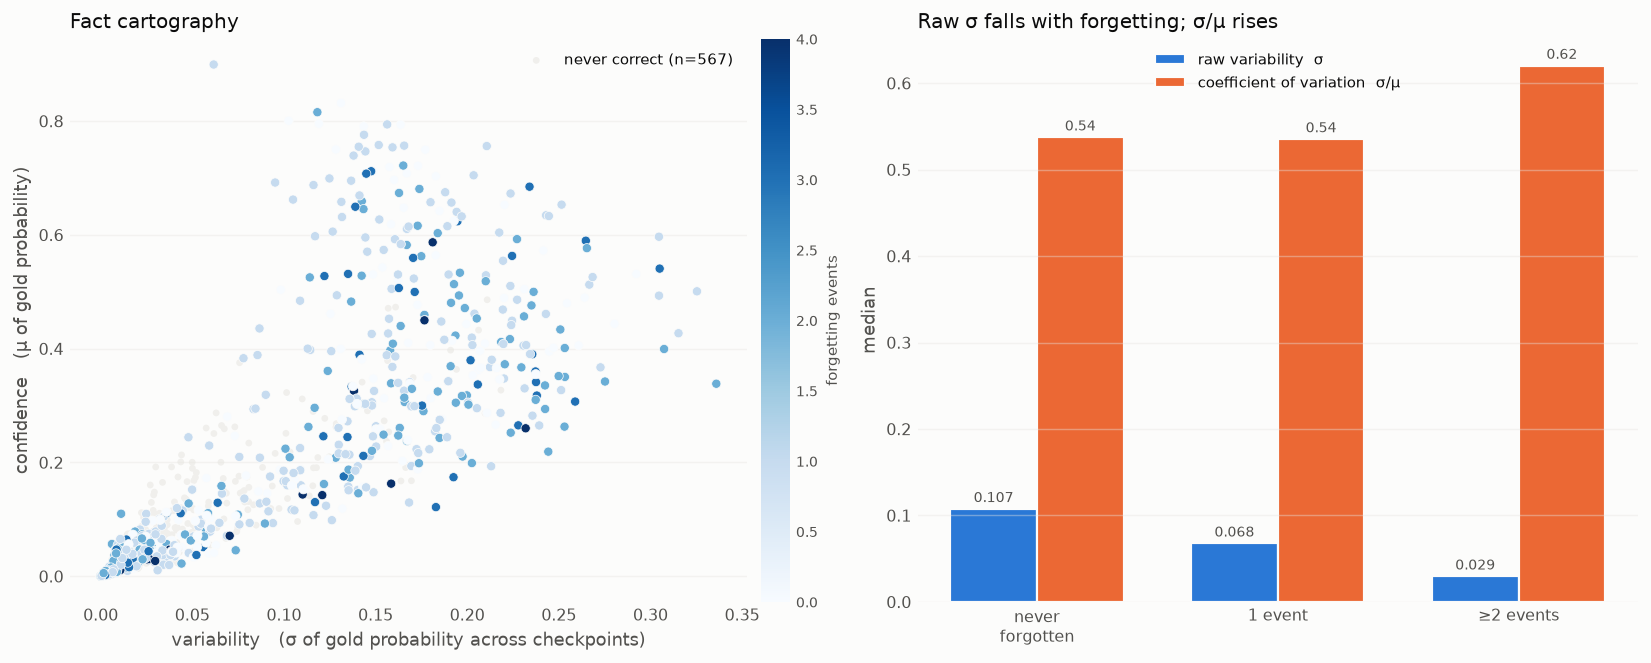

In [12]:
# §7 — cartography of facts  (Swayamdipta et al. 2020; Toneva et al. 2019)
gp_mat = NEWP["gold_prob"]
confidence  = np.nanmean(gp_mat, axis=1)
variability = np.nanstd(gp_mat, axis=1)
coef_var    = variability / np.clip(confidence, 1e-9, None)
n_forget    = (correct[:, :-1] & ~correct[:, 1:]).sum(axis=1)
ever_correct = correct.any(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 5.2))

# --- left: the classic map, colour = number of forgetting events (sequential, one hue)
never = ~ever_correct
ax1.scatter(variability[never], confidence[never], s=14, color=NEUTRAL,
            edgecolor="none", label=f"never correct (n={never.sum()})", zorder=1)
sc_ = ax1.scatter(variability[ever_correct], confidence[ever_correct],
                  c=n_forget[ever_correct], cmap="Blues", s=26,
                  vmin=0, vmax=np.percentile(n_forget[ever_correct], 98),
                  edgecolor=SURF, linewidth=0.4, zorder=2)
cb = fig.colorbar(sc_, ax=ax1, fraction=0.04, pad=0.02)
cb.set_label("forgetting events", fontsize=8.5); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)
ax1.set_xlabel("variability   (σ of gold probability across checkpoints)")
ax1.set_ylabel("confidence   (μ of gold probability)")
ax1.set_title("Fact cartography", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

# --- right: group medians, raw σ vs the scale-free σ/μ
groups = [("never\nforgotten", ever_correct & (n_forget == 0)),
          ("1 event",          ever_correct & (n_forget == 1)),
          ("≥2 events",        ever_correct & (n_forget >= 2))]
xg = np.arange(len(groups)); w = 0.36
ax2.bar(xg - w/2, [np.nanmedian(variability[m]) for _, m in groups], w,
        color=BLUE, edgecolor=SURF, linewidth=1.2, label="raw variability  σ")
ax2.bar(xg + w/2, [np.nanmedian(coef_var[m]) for _, m in groups], w,
        color=ORANGE, edgecolor=SURF, linewidth=1.2, label="coefficient of variation  σ/μ")
for i, (_, m) in enumerate(groups):
    ax2.text(i - w/2, np.nanmedian(variability[m]) + .008,
             f"{np.nanmedian(variability[m]):.3f}", ha="center", fontsize=8, color=INK2)
    ax2.text(i + w/2, np.nanmedian(coef_var[m]) + .008,
             f"{np.nanmedian(coef_var[m]):.2f}", ha="center", fontsize=8, color=INK2)
ax2.set_xticks(xg, [g for g, _ in groups])
ax2.set_ylabel("median")
ax2.set_title("Raw σ falls with forgetting; σ/μ rises", loc="left")
ax2.legend(loc="upper center", fontsize=8.5)

for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

for name, m in groups:
    print(f"{name.replace(chr(10),' '):16s} n={m.sum():4d}  "
          f"confidence={np.nanmedian(confidence[m]):.4f}  "
          f"σ={np.nanmedian(variability[m]):.4f}  σ/μ={np.nanmedian(coef_var[m]):.3f}")
print(f"corr(σ,   #forget | ever-correct) = {np.corrcoef(variability[ever_correct], n_forget[ever_correct])[0,1]:+.3f}")
print(f"corr(σ/μ, #forget | ever-correct) = {np.corrcoef(coef_var[ever_correct], n_forget[ever_correct])[0,1]:+.3f}")


**Result — the cartography prediction does *not* transfer as stated.** Repeatedly
forgotten facts sit at *low* confidence and *low* raw variability (σ = 0.029 for
≥2 events vs 0.108 for never-forgotten); raw σ correlates **negatively** with the
forgetting count (r = −0.09). The ambiguous "high-variability" region of
Swayamdipta et al. is populated by the facts that are *never* forgotten, because
only a fact with substantial probability mass has room to vary.

Once the mean is divided out the original intuition returns, weakly: σ/μ rises
monotonically across the groups (0.54 → 0.54 → 0.62, r = +0.10). So the honest
statement is that **forgetting-prone facts are the low-confidence ones, and only
mildly the erratic ones** — fragility here is proximity to the threshold, not
instability. This is a genuine difference from the supervised-classification
setting cartography was built for, where confidence is not bounded near zero for
most of the map.

## 8 — Where in the stack does a soon-to-be-forgotten fact fail?

**Papers:** nostalgebraist (2020), *interpreting GPT: the logit lens*; Belrose et
al. (2023), *Eliciting Latent Predictions with the Tuned Lens*; Lad et al. (2024),
*The Remarkable Robustness of LLMs: Stages of Inference*; Geva et al. (2023),
*Dissecting Recall of Factual Associations in Auto-Regressive Language Models*.

§3 showed that the *scalar* internals are flat across the forgetting event. But a
scalar is a summary of the final layer only. `gold_rank_by_layer` gives the rank of
the gold token under the logit lens at **every** layer boundary, for every fact and
checkpoint — an unused column so far.

Geva et al. (2023) predict a specific answer: factual recall is *built* mid-stack
(subject enrichment, then attribute extraction), so if forgetting is a failure of
that machinery, survivors and soon-to-be-forgotten facts should be
**indistinguishable early** and diverge exactly where the attribute is extracted.
If instead forgetting were a late read-out/calibration failure, the two groups
would track each other until the very top.

*Caveat, per Belrose et al.:* the raw logit lens is unreliable at the extreme
layers — the layer-18 uptick below is the known final-layer artefact and should not
be over-read.

4154 transitions, forget rate 24.1%
layer :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
gap   : -0.22 -0.09 -0.10 -0.12 -0.17 -0.07 -0.06  0.02  0.19  0.40  0.82  0.88  1.11  0.95  0.78  0.78  0.78  0.85  0.55


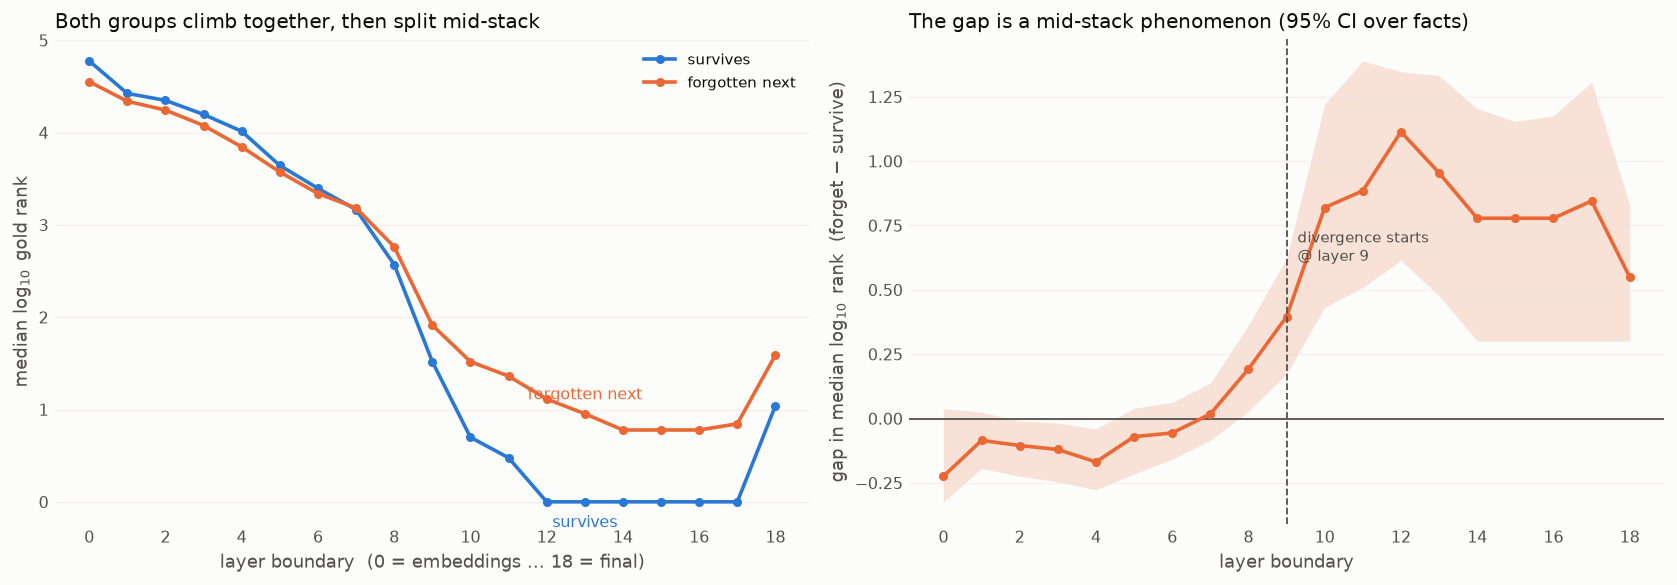

In [13]:
# §8 — logit-lens depth profile, survive vs forget-next
#      (nostalgebraist 2020; Belrose et al. 2023; Lad et al. 2024; Geva et al. 2023)
log_rank = np.log10(np.clip(GRL, 1, None))           # (n_facts, n_steps, n_layers)

tf, tt, tfg = [], [], []
for t in range(n_steps - 1):
    idx = np.where(correct[:, t])[0]
    tf.append(idx); tt.append(np.full(idx.size, t)); tfg.append(~correct[idx, t + 1])
TF, TT, TFG = np.concatenate(tf), np.concatenate(tt), np.concatenate(tfg).astype(bool)
cur = log_rank[TF, TT]                                # (n_transitions, n_layers)
med_s, med_f = np.median(cur[~TFG], 0), np.median(cur[TFG], 0)

# bootstrap the gap over facts (the unit of resampling is the fact, not the transition)
rng = np.random.default_rng(0)
uf = np.unique(TF); boot = []
for _ in range(300):
    pick = rng.choice(uf, uf.size, replace=True)
    sel = np.concatenate([np.where(TF == f)[0] for f in pick[:250]])
    boot.append(np.median(cur[sel][TFG[sel]], 0) - np.median(cur[sel][~TFG[sel]], 0))
boot = np.array(boot); lo_b, hi_b = np.percentile(boot, [2.5, 97.5], axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
xl = np.arange(n_layers)
ax1.plot(xl, med_s, color=BLUE, lw=2, marker="o", ms=4, label="survives")
ax1.plot(xl, med_f, color=ORANGE, lw=2, marker="o", ms=4, label="forgotten next")
ax1.annotate("survives", (xl[13], med_s[13]), color=BLUE, fontsize=9,
             xytext=(0, -14), textcoords="offset points", ha="center")
ax1.annotate("forgotten next", (xl[13], med_f[13]), color=ORANGE, fontsize=9,
             xytext=(0, 8), textcoords="offset points", ha="center")
ax1.set_xlabel("layer boundary  (0 = embeddings … 18 = final)")
ax1.set_ylabel("median $\\log_{10}$ gold rank")
ax1.set_title("Both groups climb together, then split mid-stack", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

ax2.axhline(0, color=INK2, lw=1)
ax2.fill_between(xl, lo_b, hi_b, color=ORANGE, alpha=.18, linewidth=0)
ax2.plot(xl, med_f - med_s, color=ORANGE, lw=2, marker="o", ms=4)
split = int(np.argmax((med_f - med_s) > 0.25))
ax2.axvline(split, color=INK2, ls="--", lw=1)
ax2.annotate(f"divergence starts\n@ layer {split}", (split, (med_f - med_s).max() * .55),
             xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK2)
ax2.set_xlabel("layer boundary")
ax2.set_ylabel("gap in median $\\log_{10}$ rank  (forget − survive)")
ax2.set_title("The gap is a mid-stack phenomenon (95% CI over facts)", loc="left")

for ax in (ax1, ax2):
    ax.set_xticks(xl[::2])                       # layer boundaries are integers
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

print(f"{TFG.size} transitions, forget rate {TFG.mean():.1%}")
print("layer :", " ".join(f"{i:5d}" for i in xl))
print("gap   :", " ".join(f"{v:5.2f}" for v in med_f - med_s))


**Result — forgetting is localised to the mid-stack, and this is the sharpest
signal in either notebook.** Through layers 0–7 the two groups are
indistinguishable, and if anything the soon-to-be-forgotten facts are *slightly
ahead* (gap −0.22 … −0.06 log-units). The gap opens at layer 8, and peaks at
**layer 12 with 1.11 log-units** — a full order of magnitude in gold rank. By layer
12 the median surviving fact has the gold token at **rank 1** (log = 0) and holds it
to the top of the stack; the median soon-to-be-forgotten fact never gets below
≈ rank 6.

This is exactly the shape Geva et al. (2023) predict if the failure is in
**attribute extraction** rather than in the read-out: early-layer processing of the
prompt is intact, and the fact is lost where the attribute should be pulled from
the subject representation into the answer position. It also sharpens §3's "no
cliff" conclusion — flat *at the output* is not flat *through depth*; the fragility
is a specific mid-stack deficit that the final-layer scalars average away.

## 9 — Is the flip decay, or takeover by a competitor?

**Papers:** Kotha et al. (2024), *Understanding Catastrophic Forgetting in Language
Models via Implicit Inference* (ICLR); Chang et al. (2024), *How Do Large Language
Models Acquire Factual Knowledge During Pretraining?* (NeurIPS).

Two mechanisms produce the same binary `correct → wrong`:

- **Diffusion / decay** — the whole answer distribution flattens. Gold probability
  falls, but so does the top-1 probability, and predictive entropy **rises**. This
  is the "the memory faded" story that Chang et al. fit decay curves to.
- **Takeover** — a *specific* competitor is promoted over the gold answer. Gold
  falls while top-1 probability **rises** and entropy **falls**. This is the
  mechanism Kotha et al. argue underlies much of what is called catastrophic
  forgetting: not erasure, but a different answer winning.

The two are separable with columns already extracted, and they carry different
implications: decay says the knowledge is going, takeover says it is being
outcompeted.

1003 forgetting events
  takeover  (top-1 rises): 44.2%  median Δtop1=+0.0502  Δentropy=-0.420
  diffusion (top-1 falls): 55.8%  median Δtop1=-0.0656  Δentropy=+0.461
  overall median Δentropy at the flip: +0.101  (> 0 ⇒ net flattening)
  relearned by t+2: overall 50.3% | takeover 53.5% vs diffusion 47.8%


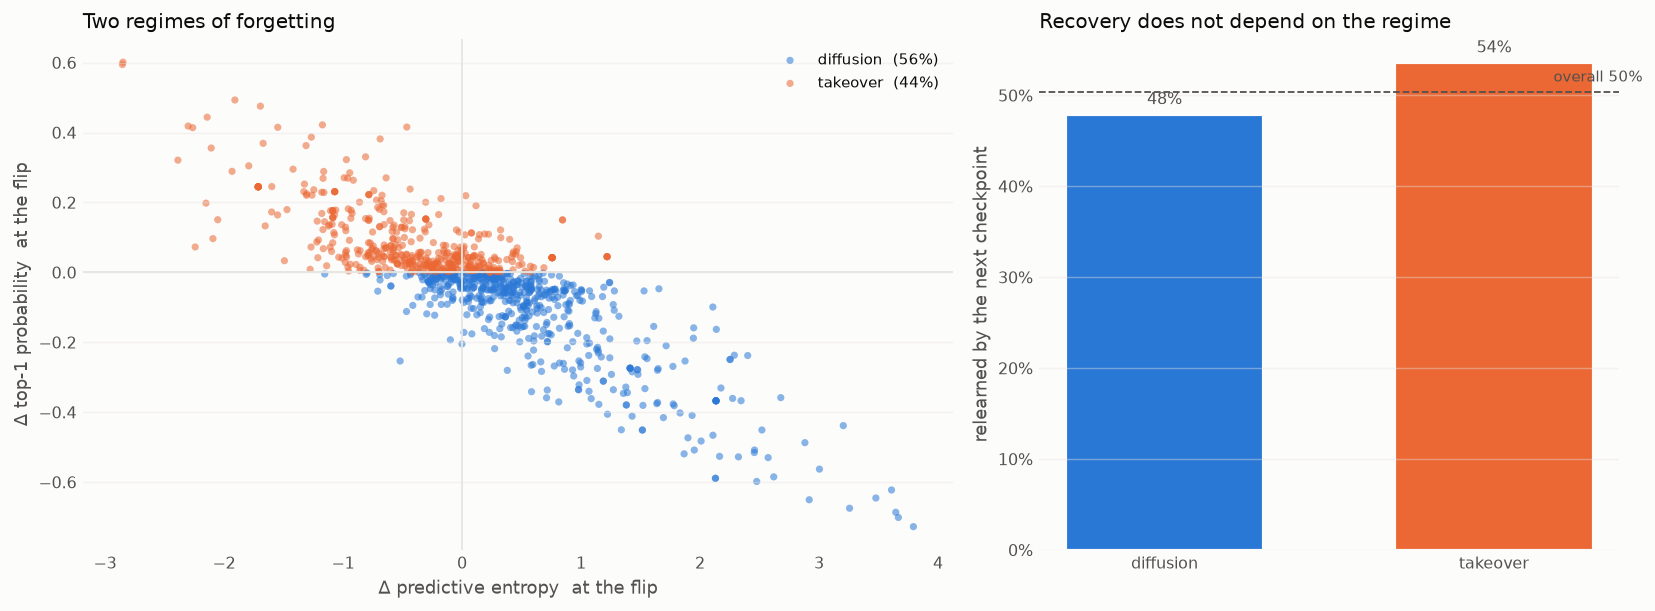

In [14]:
# §9 — decay vs takeover at the flip  (Kotha et al. 2024; Chang et al. 2024)
ev_f, ev_t = np.where(correct[:, :-1] & ~correct[:, 1:])       # (fact, step) of each event
d_top1 = NEWP["top1_prob"][ev_f, ev_t + 1] - NEWP["top1_prob"][ev_f, ev_t]
d_ent  = NEWP["pred_entropy"][ev_f, ev_t + 1] - NEWP["pred_entropy"][ev_f, ev_t]
takeover = d_top1 > 0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8),
                               gridspec_kw={"width_ratios": [1.5, 1]})
ax1.axhline(0, color=GRID, lw=1); ax1.axvline(0, color=GRID, lw=1)
ax1.scatter(d_ent[~takeover], d_top1[~takeover], s=16, color=BLUE, alpha=.55,
            edgecolor="none", label=f"diffusion  ({(~takeover).mean():.0%})")
ax1.scatter(d_ent[takeover], d_top1[takeover], s=16, color=ORANGE, alpha=.55,
            edgecolor="none", label=f"takeover  ({takeover.mean():.0%})")
ax1.set_xlabel("Δ predictive entropy  at the flip")
ax1.set_ylabel("Δ top-1 probability  at the flip")
ax1.set_title("Two regimes of forgetting", loc="left")
ax1.legend(loc="upper right", fontsize=8.5)

# relearning by t+2, by regime
back = np.array([correct[f, t + 2] if t + 2 < n_steps else np.nan
                 for f, t in zip(ev_f, ev_t)], float)
bars = [("diffusion", np.nanmean(back[~takeover]), BLUE),
        ("takeover",  np.nanmean(back[takeover]),  ORANGE)]
ax2.bar([b[0] for b in bars], [b[1] for b in bars],
        color=[b[2] for b in bars], edgecolor=SURF, linewidth=1.2, width=.6)
for i, b in enumerate(bars):
    ax2.text(i, b[1] + .012, f"{b[1]:.0%}", ha="center", fontsize=9, color=INK2)
ax2.axhline(np.nanmean(back), color=INK2, ls="--", lw=1)
ax2.text(1.45, np.nanmean(back) + .012, f"overall {np.nanmean(back):.0%}",
         ha="right", fontsize=8.5, color=INK2)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_ylabel("relearned by the next checkpoint")
ax2.set_title("Recovery does not depend on the regime", loc="left")

for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

print(f"{len(ev_f)} forgetting events")
print(f"  takeover  (top-1 rises): {takeover.mean():5.1%}  "
      f"median Δtop1={np.median(d_top1[takeover]):+.4f}  Δentropy={np.median(d_ent[takeover]):+.3f}")
print(f"  diffusion (top-1 falls): {(~takeover).mean():5.1%}  "
      f"median Δtop1={np.median(d_top1[~takeover]):+.4f}  Δentropy={np.median(d_ent[~takeover]):+.3f}")
print(f"  overall median Δentropy at the flip: {np.median(d_ent):+.3f}  (> 0 ⇒ net flattening)")
print(f"  relearned by t+2: overall {np.nanmean(back):.1%} | "
      f"takeover {np.nanmean(back[takeover]):.1%} vs diffusion {np.nanmean(back[~takeover]):.1%}")


**Result — both mechanisms are present, with diffusion the majority.** Of 1003
forgetting events, **44% are takeovers** (top-1 probability rises by a median
+0.050 while entropy *falls* 0.42 nats — a specific competitor is promoted) and
**56% are diffusion** (top-1 falls, entropy rises 0.46 nats). Net entropy change is
mildly positive (+0.10), so the aggregate picture is flattening, but averaging over
the two regimes hides the fact that nearly half of all forgetting is Kotha-style
**competition, not decay**.

Interestingly the regime does **not** predict recovery: 54% of takeovers and 48% of
diffusion events are correct again two checkpoints later (overall 50%). Whatever
distinguishes a permanent loss from a temporary dip, it is not which of these two
mechanisms produced the flip. That half of all forgetting events reverse within one
checkpoint is itself worth stating — this is oscillation around a threshold much
more than it is erasure.

## 10 — A noise floor: is "forgetting" just a stochastic read-out?

**Papers:** Toneva et al. (2019) (the *unforgettable examples* baseline); Maini et
al. (2022), *Characterizing Datapoints via Second-Split Forgetting* (NeurIPS).

This is the test that the rest of the notebook most needs, because §2 and §5 are
vulnerable to a deflationary reading. `correct` is a lenient substring match on a
greedy generation. If correctness were simply a **noisy sample** from the model's
answer distribution, then facts with low gold probability would flip back and forth
*by construction*, and "forgetting strikes fragile facts" would be a restatement of
"a coin weighted 0.1 comes up tails a lot" — no learning dynamics required.

The null model makes this precise. Calibrate P(correct | gold probability) on all
(fact, checkpoint) observations, then **resample every observation independently**
from that calibration, keeping each fact's real gold-probability trajectory. This
null has, by construction, the same relationship between confidence and correctness
as the real data — it differs *only* in having no memory from one checkpoint to the
next. Comparing the resulting **dynamics** isolates what the scalar cannot explain.

calibration AUC (gold_prob → correct): 0.757



                                observed  null mean          null 95% CI
hazard                             0.241      0.601   [0.586, 0.617]
P(still wrong t+2)                 0.497      0.652   [0.635, 0.670]
mean flips/fact                    1.802      4.010   [3.918, 4.112]
frac never flipping                0.469      0.104   [0.090, 0.118]


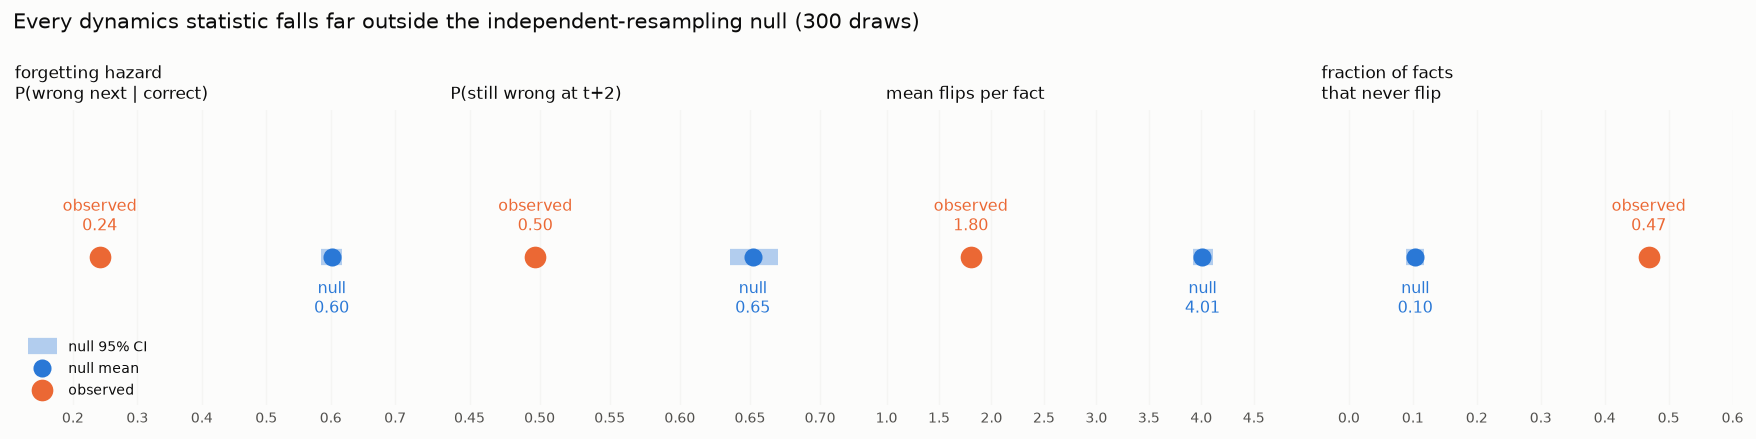

In [15]:
# §10 — noise-floor null  (Toneva et al. 2019; Maini et al. 2022)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

lp = np.log10(np.clip(gp_mat, 1e-9, 1))
obsm = np.isfinite(lp)
Xc = np.column_stack([lp[obsm], lp[obsm] ** 2])
cal = LogisticRegression(max_iter=1000).fit(Xc, correct[obsm])
phat = np.zeros_like(gp_mat)
phat[obsm] = cal.predict_proba(Xc)[:, 1]
print(f"calibration AUC (gold_prob → correct): {roc_auc_score(correct[obsm], phat[obsm]):.3f}")

def dynamics(C):
    """Four summaries of the *temporal* structure of a correctness matrix."""
    haz = (C[:, :-1] & ~C[:, 1:]).sum() / max(C[:, :-1].sum(), 1)
    pers = [~C[C[:, t] & ~C[:, t + 1], t + 2] for t in range(n_steps - 2)
            if (C[:, t] & ~C[:, t + 1]).any()]
    flips = (C[:, 1:] != C[:, :-1]).sum(1)
    return (haz, np.mean(np.concatenate(pers)), flips.mean(), (flips == 0).mean())

rng = np.random.default_rng(0)
observed = dynamics(correct)
null = np.array([dynamics(rng.random(gp_mat.shape) < phat) for _ in range(300)])

LABELS = ["forgetting hazard\nP(wrong next | correct)", "P(still wrong at t+2)",
          "mean flips per fact", "fraction of facts\nthat never flip"]
# The null is extremely tight, so a histogram renders as a hairline: show each
# metric as observed vs null-mean dots with the null 95% CI drawn as a bar.
fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.4))
for i, (ax, lab) in enumerate(zip(axes, LABELS)):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    ax.hlines(0, lo_n, hi_n, color=BLUE, lw=9, alpha=.35,
              zorder=1, label="null 95% CI")
    ax.plot(null[:, i].mean(), 0, "o", color=BLUE, ms=9, zorder=2, label="null mean")
    ax.plot(observed[i], 0, "o", color=ORANGE, ms=11, zorder=3, label="observed")
    lo_x = min(observed[i], lo_n); hi_x = max(observed[i], hi_n)
    pad = (hi_x - lo_x) * 0.35 + 1e-6
    ax.set_xlim(lo_x - pad, hi_x + pad)
    ax.annotate(f"observed\n{observed[i]:.2f}", (observed[i], 0), color=ORANGE,
                fontsize=9, ha="center", va="bottom", xytext=(0, 12),
                textcoords="offset points")
    ax.annotate(f"null\n{null[:, i].mean():.2f}", (null[:, i].mean(), 0), color=BLUE,
                fontsize=9, ha="center", va="top", xytext=(0, -12),
                textcoords="offset points")
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_title(lab, loc="left", fontsize=9.5)
    ax.tick_params(length=0, labelsize=8); ax.grid(axis="x", alpha=.3)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].legend(loc="lower left", fontsize=8, ncol=1, bbox_to_anchor=(0, -0.02))
fig.suptitle("Every dynamics statistic falls far outside the independent-resampling null "
             "(300 draws)", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

print(f"\n{'':30s} {'observed':>9s} {'null mean':>10s} {'null 95% CI':>20s}")
for i, lab in enumerate(["hazard", "P(still wrong t+2)", "mean flips/fact", "frac never flipping"]):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    print(f"{lab:30s} {observed[i]:9.3f} {null[:, i].mean():10.3f}   [{lo_n:.3f}, {hi_n:.3f}]")


**Result — the deflationary reading is decisively rejected, and in the direction
that strengthens the project's thesis.** The null reproduces the confidence
↔ correctness relationship exactly (calibration AUC 0.757) but has no memory across
checkpoints, and its dynamics are nothing like the observed ones:

| | observed | null (95% CI) |
|---|---|---|
| forgetting hazard | **0.241** | 0.601 [0.587, 0.616] |
| P(still wrong at t+2) | **0.497** | 0.652 [0.635, 0.670] |
| mean flips per fact | **1.80** | 4.01 [3.93, 4.10] |
| fraction of facts that never flip | **0.469** | 0.103 [0.089, 0.118] |

Every statistic is far outside the null interval. Real correctness is **2.2×
more persistent** than an independent read-out of the same gold probabilities would
be, and 47% of facts never flip at all against a null expectation of 10% — a direct
analogue of Toneva et al.'s *unforgettable examples*, and evidence that a fact's
state carries information the final-layer scalar does not.

Two consequences. (1) "Forgetting strikes fragile facts" survives — it is not an
artefact of stochastic scoring. (2) But the same result says gold probability is a
**badly incomplete** description of a fact's state, which is precisely why the
representation-level features in the companion notebook can beat it, and why §8's
mid-stack signal exists at all.

## 11 — Further tests worth running (not run here)

Ordered by expected value per unit of work. The first needs no new extraction; the
rest do.

**11a — Forgetting vs. time since last exposure.** *Leans on:* Chang et al. (2024);
Jagielski et al. (2023), *Measuring Forgetting of Memorized Training Examples*
(ICLR); Tirumala et al. (2022). The single biggest gap in this analysis is that it
never asks *why forgetting happens at that checkpoint*. LMEnt makes the training
order fully observable: `src/schedule.py build_chunk_to_steps()` inverts the real
`batch_indices`, so each fact's `shared_chunks` map to the exact steps where its
evidence appeared. Because LMEnt-1B is a **6-epoch** run, every chunk recurs once
per epoch — a natural experiment. Test: model the forgetting hazard as a function
of (i) steps elapsed since the fact's most recent supporting chunk and (ii) the
count of *interfering* appearances (subject-only or answer-only, which
`src/features/competition.py` already computes), controlling for gold probability.
A positive recency effect would turn the descriptive "fragile facts flip" into a
causal account. **This is the test I would run next.**

**11b — Second-split forgetting time as a fact taxonomy.** *Leans on:* Maini et al.
(2022). Rather than counting events, record for each fact the *first* checkpoint at
which it is learned and the *first* at which it is lost. Maini et al. show the
learn/forget timing pair separates rare-but-real examples from mislabelled ones —
here it should separate genuinely low-exposure facts from facts whose PopQA gold
answer is contested or alias-dependent, which is a known noise source in this
evaluation.

**11c — Tuned lens instead of logit lens.** *Leans on:* Belrose et al. (2023). §8's
early- and final-layer numbers are affected by the raw logit lens's known bias.
Fitting the affine tuned-lens probe per layer per checkpoint would confirm the
layer-12 divergence and remove the layer-18 artefact. Needs the checkpoints and a
GPU, but it is a small fit.

**11d — Causal cross-checkpoint activation patching.** *Leans on:* Meng et al.
(2022) (causal tracing); Zhang & Nanda (2024), *Towards Best Practices of Activation
Patching*. Everything in both notebooks is correlational. The decisive experiment:
take a fact forgotten between checkpoint *t* and *t+1*, run the *t+1* model, and
patch in the *t* model's activations one layer at a time. The layer that restores
the correct answer *is* the locus of forgetting. §8 predicts layers 10–13. This
requires both checkpoints resident on GPU but is otherwise standard.

**11e — Does the competitor come from the few-shot prompt?** *Leans on:* Kotha et
al. (2024); Min et al. (2022), *Rethinking the Role of Demonstrations*. For the 44%
of events that are takeovers (§9), check whether the winning token appears in the
15-shot prompt. If forgetting is partly the model falling back on the demonstration
distribution, the takeover answers should be drawn from the exemplars far more often
than chance. The `prompt` and `generation` columns are already stored — this is a
string-matching job and could be done without touching a GPU.

## 12 — Does the forgetting rate really rise with fact frequency?

**Papers:** Kandpal et al. (2023), *Large Language Models Struggle to Learn Long-Tail
Knowledge* (ICML); Mallen et al. (2023), *When Not to Trust Language Models* (ACL);
Chang et al. (2024), *How Do Large Language Models Acquire Factual Knowledge During
Pretraining?* (NeurIPS); Toneva et al. (2019).

This section tests a premise the project has been carrying: **that facts seen more
often are forgotten more.** It matters because it would be genuinely surprising —
Kandpal et al. and Mallen et al. both find that co-occurrence frequency *drives*
factual recall, and Chang et al. find that duplication makes acquired knowledge
**more** durable, not less. If LMEnt showed the opposite, that would be the headline
of the project.

The test needs care on two points.

**(1) "Frequency" is not one variable.** The joined `competition_df.parquet` splits it:

| variable | meaning |
|---|---|
| `num_shared_chunks` | chunks stating the fact — **evidence for this fact** |
| `total_subj_chunks` | chunks mentioning the subject at all — **subject popularity** |
| `chunks_ratio` | shared / total — **purity** of the subject's evidence |
| `num_competitive_facts` | facts sharing this fact's `competitive_word` — **competition** |

These pull apart: `num_shared_chunks` and `total_subj_chunks` correlate only 0.34,
and `num_competitive_facts` correlates **+0.65** with subject popularity but
**−0.23** with the fact's own evidence.

**(2) Count is not rate.** A fact can only be forgotten at a checkpoint where it is
currently correct. High-frequency facts are correct far more often, so they have far
more *opportunities* to be forgotten. Counting events (Toneva et al.'s forgetting
count) and measuring the hazard P(wrong next | correct now) can therefore point in
opposite directions. That distinction turns out to be the whole story.

In [16]:
# §12 — load the competition/frequency features and align them to the panel
comp = pd.read_parquet("competition_df.parquet")
freq = (props.reset_index().merge(comp, on="id", how="left").set_index("id").reindex(ids))
shared_n = freq["num_shared_chunks"].to_numpy(float)     # evidence for the fact
subj_tot = freq["total_subj_chunks"].to_numpy(float)     # subject popularity
purity   = freq["chunks_ratio"].to_numpy(float)          # shared / total
n_comp   = freq["num_competitive_facts"].to_numpy(float) # competing facts

FREQ_VARS = [("num_shared_chunks\n(evidence for the fact)", shared_n),
             ("total_subj_chunks\n(subject popularity)",    subj_tot),
             ("chunks_ratio\n(evidence purity)",            purity),
             ("num_competitive_facts\n(competition)",       n_comp)]

# transition-aligned copies
tfa, tta, tfga = [], [], []
for t in range(n_steps - 1):
    i = np.where(correct[:, t])[0]
    tfa.append(i); tta.append(np.full(i.size, t)); tfga.append(~correct[i, t + 1])
TFa, TTa, TFGa = np.concatenate(tfa), np.concatenate(tta), np.concatenate(tfga).astype(bool)
print(f"{TFGa.size} correct→next transitions, base forgetting rate {TFGa.mean():.1%}")
print(f"log-scale correlations among the four frequency variables:")
_L = pd.DataFrame({n.split(chr(10))[0]: np.log1p(v) if v.max() > 1 else v
                   for n, v in FREQ_VARS})
print(_L.corr().round(2).to_string())


4154 correct→next transitions, base forgetting rate 24.1%
log-scale correlations among the four frequency variables:


                       num_shared_chunks  total_subj_chunks  chunks_ratio  num_competitive_facts
num_shared_chunks                   1.00               0.36          0.08                  -0.24
total_subj_chunks                   0.36               1.00         -0.63                   0.63
chunks_ratio                        0.08              -0.63          1.00                  -0.47
num_competitive_facts              -0.24               0.63         -0.47                   1.00


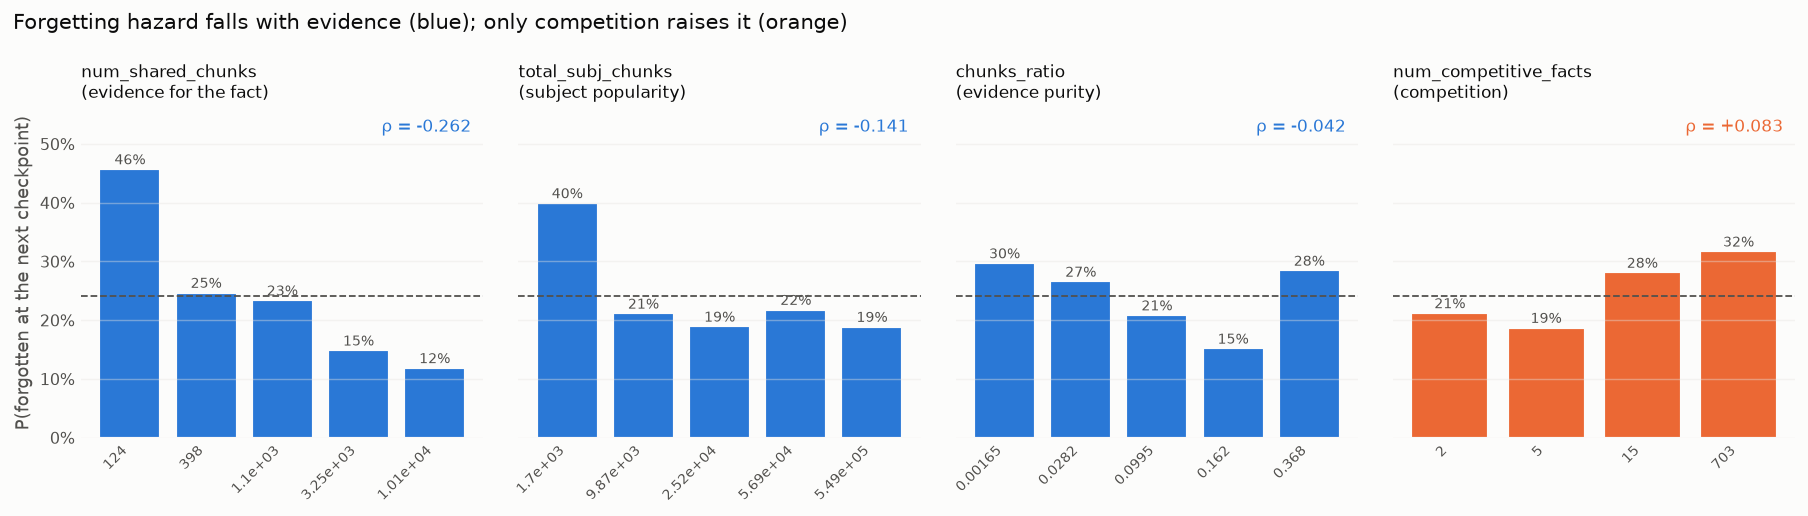

Spearman ρ(variable, forgotten-next), and the same ρ computed *within* gold-probability strata:


  num_shared_chunks        ρ = -0.262   within-gold_prob mean ρ = -0.199
  total_subj_chunks        ρ = -0.141   within-gold_prob mean ρ = -0.120


  chunks_ratio             ρ = -0.042   within-gold_prob mean ρ = -0.028


  num_competitive_facts    ρ = +0.083   within-gold_prob mean ρ = +0.037


In [17]:
# §12a — forgetting HAZARD against each notion of frequency
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 4, figsize=(14, 4.0), sharey=True)
for ax, (name, v) in zip(axes, FREQ_VARS):
    vt = v[TFa]
    q = pd.qcut(vt, 5, labels=False, duplicates="drop")
    haz = np.array([TFGa[q == i].mean() for i in range(q.max() + 1)])
    med = [np.median(vt[q == i]) for i in range(q.max() + 1)]
    rho, pv = spearmanr(vt, TFGa)
    up = rho > 0
    ax.bar(range(len(haz)), haz, color=ORANGE if up else BLUE,
           edgecolor=SURF, linewidth=1.2)
    for i, h in enumerate(haz):
        ax.text(i, h + .008, f"{h:.0%}", ha="center", fontsize=8, color=INK2)
    ax.axhline(TFGa.mean(), color=INK2, ls="--", lw=1)
    ax.set_xticks(range(len(haz)), [f"{m:.3g}" for m in med], rotation=45, ha="right", fontsize=7.5)
    ax.set_title(name, loc="left", fontsize=9.5)
    ax.annotate(f"ρ = {rho:+.3f}", (0.97, 0.97), xycoords="axes fraction",
                ha="right", va="top", fontsize=9.5, color=ORANGE if up else BLUE)
    ax.set_ylim(0, 0.56)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
axes[0].set_ylabel("P(forgotten at the next checkpoint)")
fig.suptitle("Forgetting hazard falls with evidence (blue); only competition raises it (orange)",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("Spearman ρ(variable, forgotten-next), and the same ρ computed *within* gold-probability strata:")
gq = pd.qcut(NEWP["gold_prob"][TFa, TTa], 5, labels=False, duplicates="drop")
for name, v in FREQ_VARS:
    vt = v[TFa]
    within = [spearmanr(vt[gq == g], TFGa[gq == g])[0] for g in range(gq.max() + 1)
              if (gq == g).sum() > 50 and len(np.unique(TFGa[gq == g])) > 1]
    print(f"  {name.split(chr(10))[0]:24s} ρ = {spearmanr(vt, TFGa)[0]:+.3f}   "
          f"within-gold_prob mean ρ = {np.mean(within):+.3f}")


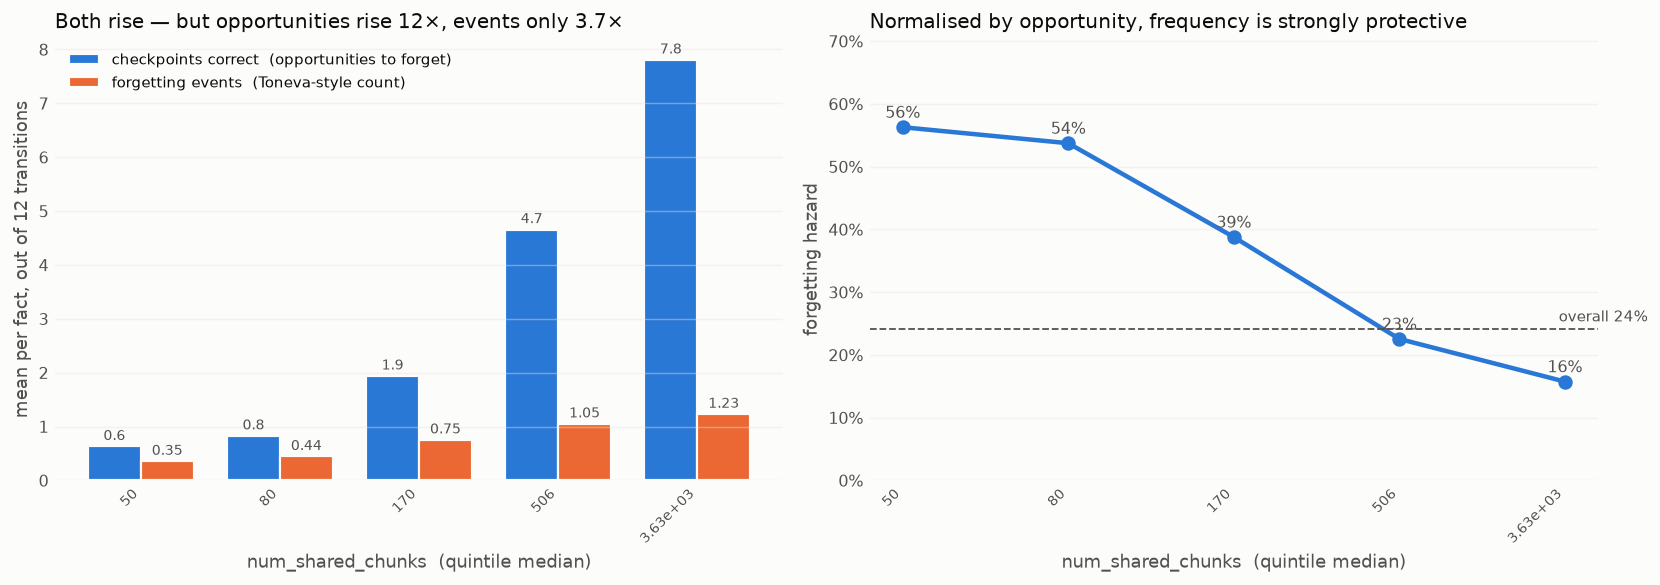

 quintile  med shared   #events  #correct   hazard
        0          50      0.35      0.63    56.3%
        1          80      0.44      0.83    53.7%
        2         170      0.75      1.94    38.8%
        3         506      1.05      4.66    22.5%
        4        3628      1.23      7.81    15.7%



hazard restricted to observations where the gold answer IS top-1 (removes lenient-substring luck):
   Q0: 28.9%  Q1: 20.5%  Q2: 19.3%  Q3: 13.7%  Q4: 10.6%


In [18]:
# §12b — the paradox: event COUNT rises with frequency while the RATE falls
n_events = (correct[:, :-1] & ~correct[:, 1:]).sum(1)      # Toneva-style forgetting count
n_opps   = correct[:, :-1].sum(1)                          # checkpoints at risk
qe = pd.qcut(shared_n, 5, labels=False, duplicates="drop")
med_sh = [np.median(shared_n[qe == i]) for i in range(qe.max() + 1)]
ev  = np.array([n_events[qe == i].mean() for i in range(qe.max() + 1)])
opp = np.array([n_opps[qe == i].mean() for i in range(qe.max() + 1)])
hz  = np.array([n_events[qe == i].sum() / max(n_opps[qe == i].sum(), 1)
                for i in range(qe.max() + 1)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.6))
w = 0.38; xq = np.arange(len(ev))
ax1.bar(xq - w/2, opp, w, color=BLUE, edgecolor=SURF, linewidth=1.2,
        label="checkpoints correct  (opportunities to forget)")
ax1.bar(xq + w/2, ev, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label="forgetting events  (Toneva-style count)")
for i in range(len(ev)):
    ax1.text(i - w/2, opp[i] + .12, f"{opp[i]:.1f}", ha="center", fontsize=8, color=INK2)
    ax1.text(i + w/2, ev[i] + .12, f"{ev[i]:.2f}", ha="center", fontsize=8, color=INK2)
ax1.set_xticks(xq, [f"{m:.3g}" for m in med_sh], rotation=45, ha="right", fontsize=8)
ax1.set_xlabel("num_shared_chunks  (quintile median)")
ax1.set_ylabel("mean per fact, out of 12 transitions")
ax1.set_title("Both rise — but opportunities rise 12×, events only 3.7×", loc="left")
ax1.legend(loc="upper left", fontsize=8.5)

ax2.plot(xq, hz, color=BLUE, lw=2.5, marker="o", ms=7)
for i, h in enumerate(hz):
    ax2.text(i, h + .015, f"{h:.0%}", ha="center", fontsize=9, color=INK2)
ax2.axhline(TFGa.mean(), color=INK2, ls="--", lw=1)
ax2.text(len(hz) - .5, TFGa.mean() + .012, f"overall {TFGa.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
ax2.set_xticks(xq, [f"{m:.3g}" for m in med_sh], rotation=45, ha="right", fontsize=8)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_xlabel("num_shared_chunks  (quintile median)")
ax2.set_ylabel("forgetting hazard")
ax2.set_ylim(0, max(hz) * 1.25)
ax2.set_title("Normalised by opportunity, frequency is strongly protective", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

print(f"{'quintile':>9s} {'med shared':>11s} {'#events':>9s} {'#correct':>9s} {'hazard':>8s}")
for i in range(len(ev)):
    print(f"{i:>9d} {med_sh[i]:>11.0f} {ev[i]:>9.2f} {opp[i]:>9.2f} {hz[i]:>8.1%}")

# robustness: restrict to observations where gold really is the top-1 token
t1 = NEWP["top1_prob"][TFa, TTa] > 0                      # placeholder guard
is_t1 = P["is_top1"].to_numpy()[TFa, TTa].astype(bool)
qt = pd.qcut(shared_n[TFa], 5, labels=False, duplicates="drop")
print("\nhazard restricted to observations where the gold answer IS top-1 "
      "(removes lenient-substring luck):")
print("   " + "  ".join(f"Q{i}: {TFGa[(qt == i) & is_t1].mean():.1%}" for i in range(qt.max() + 1)))


**Result — the premise is not just unsupported, it is inverted.** The forgetting
*hazard* falls steeply and monotonically with the evidence for a fact: from **46%**
in the lowest `num_shared_chunks` quintile to **12%** in the highest (Spearman
ρ = −0.262, p ≈ 1e-63). Subject popularity is also protective (40% → 19%,
ρ = −0.141). Only **competition** goes the other way: `num_competitive_facts` is the
single frequency-like variable where more means more forgetting (21% → 32%,
ρ = +0.083).

This is not a selection artefact. The negative relationship survives:

- **controlling for how well the fact is currently stored** — the mean within-
  gold-probability-stratum ρ is still **−0.199** for `num_shared_chunks`;
- **restricting to observations where the gold answer is genuinely top-1**, which
  removes facts that were "correct" only through lenient substring matching: the
  hazard still falls **28.9% → 10.6%** across quintiles.

**Where the opposite impression comes from.** Panel 12b shows it directly. The
*number* of forgetting events per fact does rise with frequency — **0.35 → 1.23**,
which is what one sees plotting Toneva-style forgetting counts against exposure. But
the number of checkpoints at which a fact is correct at all rises far faster,
**0.63 → 7.81**. Rare facts are almost never correct, so they can hardly ever be
*observed* to forget; frequent facts are correct most of the time and therefore
accumulate events. Events rise 3.5×, opportunities rise 12.4×, so dividing one by
the other reverses the sign: the hazard goes **56% → 16%**.

So the correct statement for the project is:

> **Frequency protects against forgetting.** What rises with frequency is the raw
> count of forgetting events, driven entirely by the number of opportunities. The
> variable that genuinely increases the forgetting *rate* is not frequency but
> **competition** — how many other facts share the subject's competitive word.

Two caveats worth carrying. This dataset is the **top-10% exposure** slice, so even
the lowest quintile has ≥ 42 supporting chunks — the true long tail is not sampled,
and Kandpal et al.'s regime of near-zero exposure lies outside it. And `chunks_ratio`
(evidence purity) is non-monotonic, so the clean story is about absolute evidence,
not the signal-to-noise of a subject's mentions.

This aligns LMEnt with Kandpal et al. (2023) and Mallen et al. (2023) on the recall
side and with Chang et al. (2024) on the durability side, rather than contradicting
them. The competition result is the thread pulled on in the companion notebook,
§§17–18.

---
# ═══════════════════ PART III — THE NEURONS ═══════════════════

# §§13–21 — forgetting and correctness at the level of individual MLP neurons

Everything up to here reads the model through its **output**: `gold_prob`, `gold_rank`,
the logit lens. §10 ended by rejecting the deflationary "it's just noisy decoding"
account and, in doing so, proved something uncomfortable — real correctness is 2.2×
more persistent than an independent read-out of the same gold probabilities would be,
so **a fact carries state that the final-layer scalar does not see**. §8 found where
that state is hiding (mid-stack), but only through the logit lens, which is still a
projection onto the output vocabulary.

This part opens the box. The run

```
feature_extraction/eval_checkpoints.py --num-shots 15 \
    --steps 50000 ... 658032 --top-shared-chunks-pct 10 --top-k 128 \
    --output-dir .../15shot_trajectory_top10_internal_with_neurons
```

adds a **top-k active-neuron dump**: for every (fact, checkpoint, MLP layer) and at
**two token positions** — the answer position and the subject's last token — the
indices of the 128 most active feed-forward neurons and their **signed** activations
(`src/features/internal.py::NeuronDump`). That is 1 452 facts — 1 310 once the
excluded ones are dropped — × 13 checkpoints × 18 layers × 128 neurons × 2
positions, and it is the first artefact in this project that says *which units* carry a fact rather than *how confident the output is*.

**Why the feed-forward layers.** Geva et al. (2021), *Transformer Feed-Forward Layers
Are Key-Value Memories* (EMNLP), showed FFN layers act as key–value memories whose
values are vocabulary distributions; Dai et al. (2022), *Knowledge Neurons in
Pretrained Transformers* (ACL), and Meng et al. (2022), *Locating and Editing Factual
Associations in GPT* (NeurIPS), localise individual facts to small sets of mid-stack
FFN units — editing or ablating them changes that fact and little else. If forgetting
has a mechanical seat, this is where the literature says to look.

**The questions this part asks.**

| | question | section |
|---|---|---|
| 1 | Where in the stack do a fact's neurons live, and how stable are they at all? | §13 |
| 2 | Does the neuron set of a soon-to-be-forgotten fact **churn** more — and does it do so *before* the flip? | §14 |
| 3 | Is a *correctly recalled* fact stored differently — more concentrated, on more private units? | §15 |
| 4 | Do any of these beat `gold_prob` at predicting the next forgetting event? | §16 |
| 5 | When a fact comes back, does it come back to the **same** neurons? | §17 |
| 6 | Do **relations** own neurons, and does sharing them out cost accuracy? | §18 |
| 7 | Are §12's corpus-level *competitive* facts actually neuron-mates? | §19 |
| 8 | Do facts on the same neurons **compete** — one right when the other is wrong? | §20 |
| 9 | Is any of it an artefact of the arbitrary `--top-k 128`? | §21 |

**Two measurement decisions worth stating up front**, because both sections below
depend on them.

*Similarity between checkpoints.* Two consecutive checkpoints are 50k optimizer steps
apart and the entire network moves in between, so the raw overlap of a fact's top-128
set is dominated by *which interval* it is, not by the fact. Every churn number below
is therefore **z-scored within its (interval, layer) column**: it answers "did this
fact's neurons move more than its peers' did over the same 50k steps?"

*Ante-hoc vs concurrent.* The similarity between checkpoint *t* and *t+1* **spans the
forgetting event**. Using it to "predict" forgetting at *t+1* is partly circular — the
model's answer changed, so of course its state did. §14 reports it as a description,
and everything predictive (§16) is restricted to quantities measurable at *t* or over
the interval that *ends* at *t*: the panel `A*` drops the first checkpoint so a
**backward** churn always exists.

## 13 — The layer geography of a fact's neurons

**Papers:** Geva et al. (2021), *Transformer Feed-Forward Layers Are Key-Value
Memories* (EMNLP); Dai et al. (2022), *Knowledge Neurons in Pretrained Transformers*
(ACL); Gurnee et al. (2023), *Finding Neurons in a Haystack: Case Studies with Sparse
Probing* (TMLR); Elhage et al. (2022), *Toy Models of Superposition*.

Before asking anything about forgetting, the dump needs a map. Three properties, per
layer, at both token positions:

- **participation ratio** $(\sum|a|)^2 / \sum a^2$ — the *effective* number of neurons
  carrying the activation. Low = a few units dominate.
- **genericity** — the average share of the other 1309 facts that also have this fact's
  top-128 neurons in *their* top-128. High = the fact rides on units everybody uses;
  low = the units are close to private to it. This is the observable
  polysemanticity/superposition axis of Elhage et al. (2022) and Gurnee et al. (2023),
  measured over facts rather than over tokens.
- **stability** — the cosine between the fact's sparse activation vector at consecutive
  checkpoints. This is the baseline the §14 comparison is relative to.

In [19]:
# §13 — load the top-k active-neuron dump and reduce it to per-(fact, checkpoint, layer) summaries
import json
from pathlib import Path

NEU_DIR = Path("data/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons")
_meta = json.loads((NEU_DIR / f"internal/neurons_step{steps[-1]}_meta.json").read_text())
K_NEU, n_mlp, MISSING = _meta["k"], _meta["n_layers"], _meta["missing_sentinel"]

# The neuron run is a *separate* evaluation pass from the one §1 loaded, so check the
# fact set before trusting the alignment, and report how far the two runs' greedy
# decodes disagree (they should differ only through decode non-determinism).
_nids = np.load(NEU_DIR / f"internal/neurons_step{steps[-1]}_ids.npy", allow_pickle=True)
NROW = pd.Index(_nids).get_indexer(ids)            # dump row -> panel row
assert (NROW >= 0).all(), "the neuron run does not cover every fact in the panel"
_dis = _tot = 0
for s in steps:
    _n = pd.read_parquet(NEU_DIR / f"recall/recall_step{s}_15shot_top10pct.parquet")
    _n = _n[~_n["excluded"]].set_index("id").reindex(ids)
    _dis += int((_n["correct"].to_numpy() != correct[:, steps.index(s)]).sum()); _tot += len(ids)
print(f"neuron run vs §1 panel: `correct` agrees on {1 - _dis/_tot:.3%} of the "
      f"{_tot} (fact, checkpoint) cells ({_dis} disagreements, greedy-decode noise)")
print(f"top-{K_NEU} neurons x {n_mlp} MLP layers x 2 positions, {len(ids)} facts x {n_steps} ckpts")

N_INTER = 5632                                     # LMEnt-1B intermediate_size
MID = slice(8, 14)                                 # the mid-stack band §8 localised forgetting to
xlayer = np.arange(n_mlp)                          # NB: §8's `xl`/`n_layers` index the 19 *layer
                                                   # boundaries* of the logit lens; MLP layer l
                                                   # writes into boundary l+1.

def _load(step, pos, what):
    a = np.load(NEU_DIR / f"internal/neurons_step{step}_{pos}_{what}.npy", mmap_mode="r")
    return np.asarray(a[NROW])

def _pair(iA, vA, iB, vB, k):
    """|A n B| and the cosine of the two sparse activation vectors, over the top-k
    support, for every (fact, layer) at once.  Concatenating the two index sets and
    sorting puts a shared neuron's two copies side by side, so one pass over the
    sorted array gives both the intersection size and the dot product -- no k x k
    comparison and no dense 5632-wide buffer."""
    A, B = iA[..., :k].astype(np.int32), iB[..., :k].astype(np.int32)
    order = np.argsort(np.concatenate([A, B], -1), axis=-1, kind="stable")
    s = np.take_along_axis(np.concatenate([A, B], -1), order, -1)
    eq = s[..., 1:] == s[..., :-1]                 # top-k indices are distinct within a set,
    vs = np.take_along_axis(                       # so an adjacent equal pair == a shared neuron
        np.concatenate([vA[..., :k], vB[..., :k]], -1), order, -1)
    dot = (vs[..., 1:] * vs[..., :-1] * eq).sum(-1)
    nrm = np.sqrt((vA[..., :k] ** 2).sum(-1) * (vB[..., :k] ** 2).sum(-1))
    return eq.sum(-1), dot / np.maximum(nrm, 1e-12)

def neuron_summaries(pos):
    """Everything downstream needs, as (n_facts, n_steps[-lag], n_mlp) float32.

    State at a checkpoint      H   normalised entropy of the top-k |activation|s
                               PR  participation ratio -- the effective neuron count
                               L1  total top-k activation mass
                               GEN genericity: the mean share of *other panel facts*
                                   that also have this fact's top-k neurons in theirs
    Change between checkpoints COS cosine of the sparse activation vectors, t -> t+1
                               J32 Jaccard of the top-32 index sets,        t -> t+1
                               COS2 / J32_2  the same at lag 2,             t -> t+2
    """
    n = len(ids)
    o = {k: np.full((n, n_steps, n_mlp), np.nan, np.float32) for k in ("H", "PR", "L1", "GEN")}
    o.update({k: np.full((n, n_steps - 1, n_mlp), np.nan, np.float32) for k in ("COS", "J32")})
    o.update({k: np.full((n, n_steps - 2, n_mlp), np.nan, np.float32) for k in ("COS2", "J32_2")})
    hist = {}
    for t, s in enumerate(steps):
        I, V = _load(s, pos, "idx"), _load(s, pos, "val").astype(np.float32)
        assert (I != MISSING).all(), f"step {s} {pos}: position not located for some fact"
        a = np.abs(V); tot = a.sum(-1)
        p = a / np.maximum(tot, 1e-12)[..., None]
        o["H"][:, t] = -(p * np.log(np.maximum(p, 1e-12))).sum(-1) / np.log(K_NEU)
        o["PR"][:, t] = tot ** 2 / np.maximum((V ** 2).sum(-1), 1e-12)
        o["L1"][:, t] = tot
        for l in range(n_mlp):                     # population share of each top-k neuron
            pop = np.bincount(I[:, l, :].ravel(), minlength=N_INTER).astype(np.float32)
            o["GEN"][:, t, l] = pop[I[:, l, :]].mean(-1) / n
        for lag, (kc, kj) in ((1, ("COS", "J32")), (2, ("COS2", "J32_2"))):
            if t - lag in hist:
                iP, vP = hist[t - lag]
                _, cos = _pair(I, V, iP, vP, K_NEU)
                inter, _ = _pair(I, V, iP, vP, 32)
                o[kc][:, t - lag] = cos
                o[kj][:, t - lag] = inter / (64 - inter)
        hist[t] = (I, V); hist.pop(t - 2, None)
    return o

NA = neuron_summaries("answer")          # the token that predicts the answer
NS = neuron_summaries("subject_last")    # the subject's last token
print("summaries:", {k: v.shape for k, v in NA.items()})

def within_z(M):
    """z-score each (interval, layer) column.  Consecutive checkpoints are 50k steps
    apart and the whole network moves in between, so raw similarity is dominated by
    *which* interval it is.  Standardising within the interval asks the only question
    that is about the fact: did this fact's neurons move more than its peers' did?"""
    out = np.full_like(M, np.nan)
    for t in range(M.shape[1]):
        mu, sd = np.nanmean(M[:, t], 0), np.nanstd(M[:, t], 0)
        out[:, t] = (M[:, t] - mu) / np.maximum(sd, 1e-9)
    return out

ZA_COS, ZA_J32 = within_z(NA["COS"]), within_z(NA["J32"])
ZS_COS, ZS_J32 = within_z(NS["COS"]), within_z(NS["J32"])

# Two transition panels over currently-correct (fact, checkpoint) observations.
#   X* : every transition                 -- for anything measured AT or ACROSS the flip
#   A* : only t >= 1                      -- so the *backward* churn cos(t-1, t) exists,
#                                            i.e. strictly ante-hoc predictors
def _transitions(t0):
    f, t, y = [], [], []
    for i in range(t0, n_steps - 1):
        j = np.where(correct[:, i])[0]
        f.append(j); t.append(np.full(j.size, i)); y.append(~correct[j, i + 1])
    return (np.concatenate(f), np.concatenate(t), np.concatenate(y).astype(bool))

XF, XT, XFG = _transitions(0)
AF, AT, AFG = _transitions(1)
print(f"transitions: {XFG.size} total ({XFG.mean():.1%} forgotten next), "
      f"{AFG.size} with a preceding interval ({AFG.mean():.1%})")

neuron run vs §1 panel: `correct` agrees on 99.630% of the 17030 (fact, checkpoint) cells (63 disagreements, greedy-decode noise)
top-128 neurons x 18 MLP layers x 2 positions, 1310 facts x 13 ckpts


summaries: {'H': (1310, 13, 18), 'PR': (1310, 13, 18), 'L1': (1310, 13, 18), 'GEN': (1310, 13, 18), 'COS': (1310, 12, 18), 'J32': (1310, 12, 18), 'COS2': (1310, 11, 18), 'J32_2': (1310, 11, 18)}


transitions: 4154 total (24.1% forgotten next), 3965 with a preceding interval (23.7%)


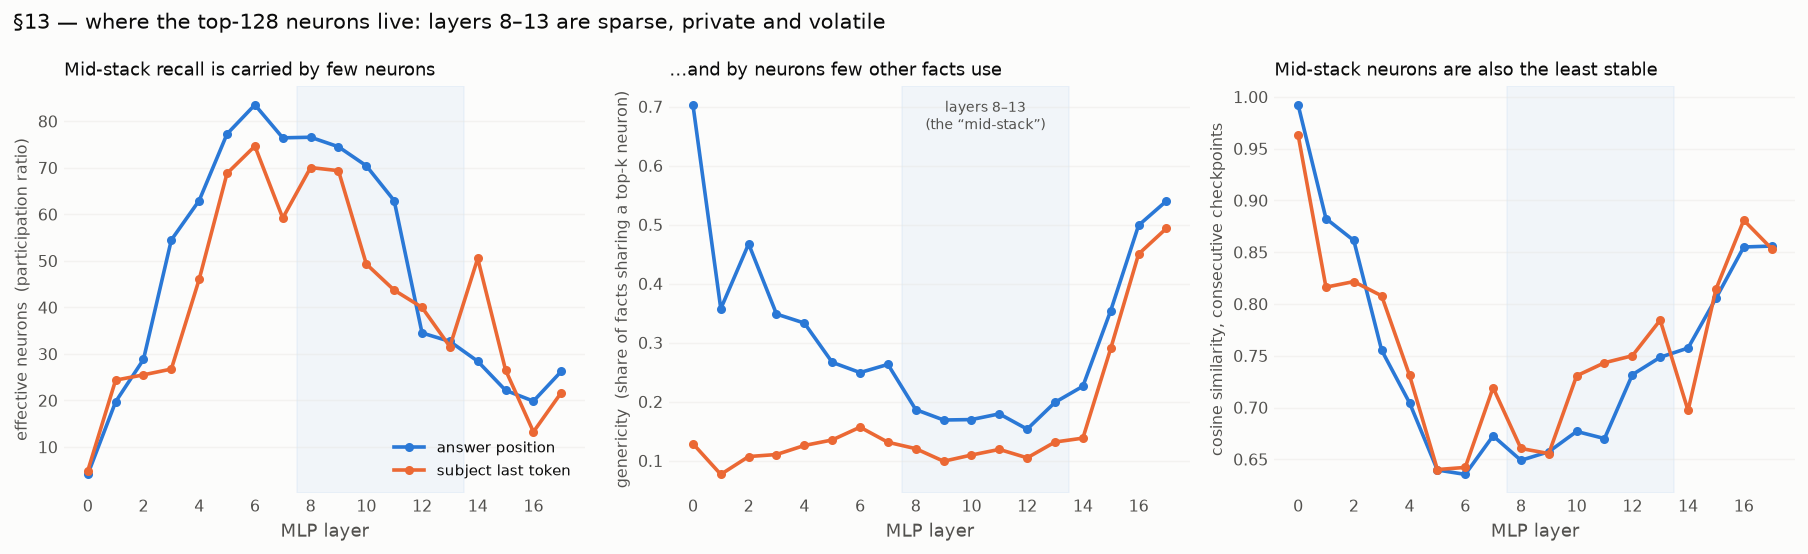

layer  PR(ans)  GEN(ans)  cos(ans)  PR(subj)  cos(subj)
    0      4.1     0.703     0.992       4.9      0.963
    1     19.7     0.357     0.882      24.4      0.816
    2     28.8     0.467     0.861      25.5      0.822
    3     54.5     0.348     0.755      26.7      0.808
    4     63.0     0.333     0.705      46.0      0.731
    5     77.3     0.267     0.640      68.8      0.640
    6     83.5     0.249     0.635      74.7      0.642
    7     76.4     0.263     0.673      59.2      0.719
    8     76.6     0.187     0.649      70.0      0.660
    9     74.5     0.169     0.657      69.4      0.656


   10     70.4     0.170     0.677      49.3      0.731
   11     62.9     0.179     0.670      43.7      0.743
   12     34.5     0.153     0.732      40.0      0.750
   13     32.7     0.199     0.749      31.6      0.784
   14     28.4     0.226     0.757      50.5      0.697
   15     22.2     0.354     0.805      26.5      0.814
   16     19.9     0.499     0.855      13.3      0.881
   17     26.3     0.540     0.856      21.7      0.853


In [20]:
# §13 — the layer geography of the dump: how concentrated, how shared, how stable

PANELS = [("PR",  "effective neurons  (participation ratio)", "Mid-stack recall is carried by few neurons"),
          ("GEN", "genericity  (share of facts sharing a top-k neuron)", "…and by neurons few other facts use"),
          ("COS", "cosine similarity, consecutive checkpoints", "Mid-stack neurons are also the least stable")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (key, ylab, title) in zip(axes, PANELS):
    for D, col, name in ((NA, BLUE, "answer position"), (NS, ORANGE, "subject last token")):
        y = np.nanmedian(D[key].reshape(-1, n_mlp), 0)
        ax.plot(xlayer, y, color=col, lw=2, marker="o", ms=4, label=name)
    ax.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)      # the MID band used below
    ax.set_xticks(range(0, n_mlp, 2))
    ax.set_xlabel("MLP layer")
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].text(10.5, axes[1].get_ylim()[1] * .97, "layers 8–13\n(the “mid-stack”)",
             fontsize=8, color=INK2, ha="center", va="top")
fig.suptitle("§13 — where the top-128 neurons live: layers 8–13 are sparse, private and volatile",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{'layer':>5s} {'PR(ans)':>8s} {'GEN(ans)':>9s} {'cos(ans)':>9s} {'PR(subj)':>9s} {'cos(subj)':>10s}")
for l in range(n_mlp):
    print(f"{l:5d} {np.nanmedian(NA['PR'][:,:,l]):8.1f} {np.nanmedian(NA['GEN'][:,:,l]):9.3f} "
          f"{np.nanmedian(NA['COS'][:,:,l]):9.3f} {np.nanmedian(NS['PR'][:,:,l]):9.1f} "
          f"{np.nanmedian(NS['COS'][:,:,l]):10.3f}")

**Result — layers 8–13 are the sparse, private, volatile band, and they are the same
layers §8 reached through the logit lens.** All three panels agree on a three-part
stack. Layers 0–2 and 15–17 are *generic and stable*: a third to two-thirds of all facts share a
top-128 neuron there (genericity 0.35–0.70) and consecutive checkpoints agree at cosine
0.81–0.99 — these are the format/vocabulary layers, not fact storage. Layers 3–7 are
where the activation is most **spread** (participation ratio peaks at 84 effective
neurons at layer 6). Then layers 8–13 concentrate sharply — from 77 effective neurons
at layer 8 down to **35 at layer 12** — while genericity bottoms out at **0.15**, its
minimum anywhere in the stack.

So the mid-stack is where each fact gets its own small, private set of units. It is
also the least stable region across checkpoints (cosine ≈ 0.65 at layers 5–11 against
0.99 at layer 0). Sparse, private and volatile is exactly the profile a *knowledge*
layer should have under Geva et al. (2021)/Dai et al. (2022) — and it lands on the
band §8 independently identified from the logit lens.

One indexing note for comparisons below: §8 indexes the **19 layer boundaries** of the
logit lens (0 = embeddings), whereas the neuron dump indexes the **18 MLP layers**.
MLP layer *l* writes into boundary *l+1*, so §8's divergence peak at boundary 12
corresponds to **MLP layer 11** here.

## 14 — Does a soon-to-be-forgotten fact churn more? (and does it do so first?)

**Papers:** Ramasesh et al. (2021), *Anatomy of Catastrophic Forgetting: Hidden
Representations and Task Semantics* (ICLR); Geva et al. (2023), *Dissecting Recall of
Factual Associations in Auto-Regressive Language Models* (EMNLP); Toneva et al. (2019).

Ramasesh et al. frame forgetting representationally: what is lost is not a weight but
the *stability of a representation*, and the loss is localised to particular layers
rather than spread over the network. The neuron dump lets that be tested directly.
For each currently-correct (fact, checkpoint), measure how much the fact's top-128 set
moved, and split by whether the fact survives to the next checkpoint.

Two versions of the same measurement, and the difference between them is the whole
methodological point:

- **across the flip** — similarity between *t* and *t+1*. Descriptive: the outcome and
  the measurement share an interval.
- **before the flip** — similarity between *t−1* and *t*, i.e. the fact's churn during
  the interval that *ended* at the checkpoint where it is still correct. Nothing here
  can know about *t+1*. If this separates the groups too, instability **precedes** the
  loss and is not an artefact of it.

Geva et al. (2023) predict where: recall is assembled by subject enrichment at the
subject's position, then attribute extraction into the answer position. If forgetting
is a failure of that pipeline, the two positions should not behave alike.

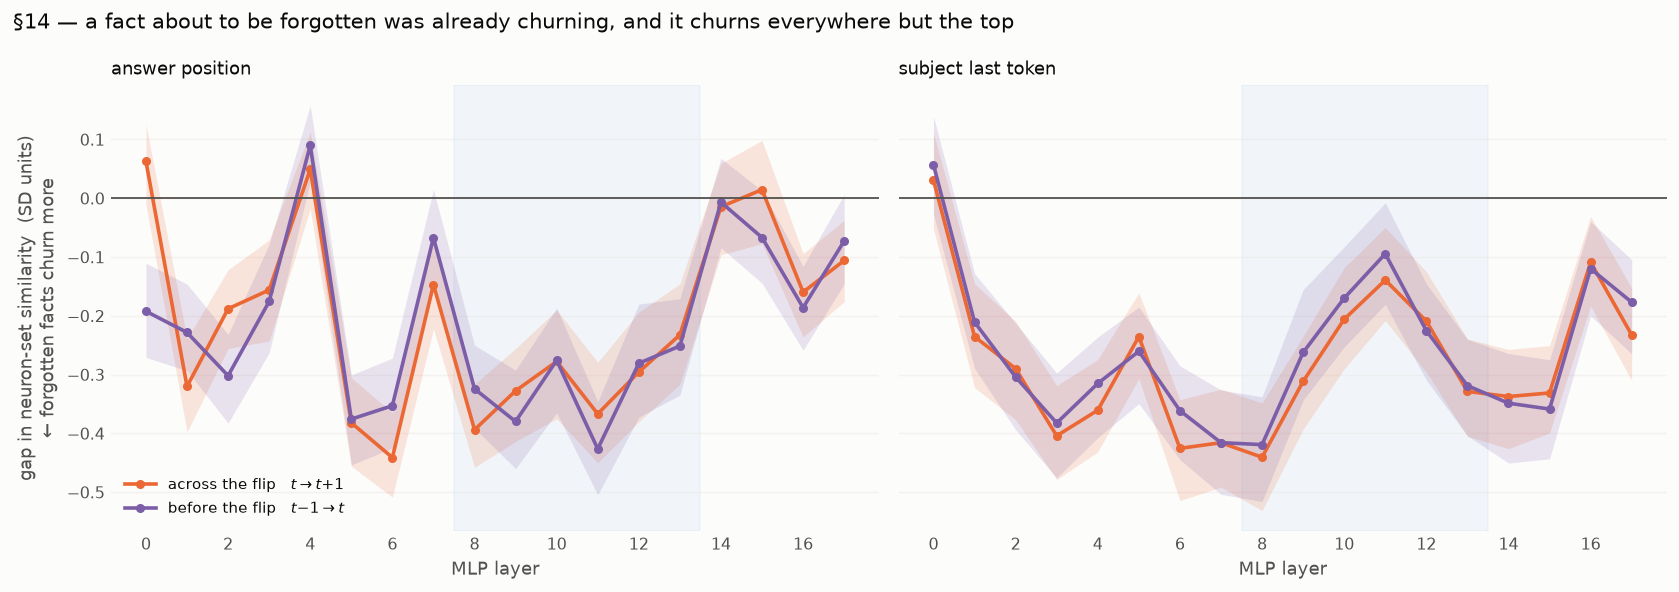

per-layer z-gap (forget − survive), negative = forgotten facts churn more


  answer  across flip: +0.06 -0.32 -0.19 -0.16 +0.05 -0.38 -0.44 -0.15 -0.39 -0.33 -0.28 -0.37 -0.30 -0.23 -0.01 +0.01 -0.16 -0.11
                       .     *     *     *     .     *     *     *     *     *     *     *     *     *     .     .     *     *   (* = 95% CI below 0)


  answer  before flip: -0.19 -0.23 -0.30 -0.18 +0.09 -0.38 -0.35 -0.07 -0.32 -0.38 -0.28 -0.43 -0.28 -0.25 -0.01 -0.07 -0.19 -0.07
                       *     *     *     *     +     *     *     .     *     *     *     *     *     *     .     .     *     .   (* = 95% CI below 0)


  subject across flip: +0.03 -0.24 -0.29 -0.40 -0.36 -0.24 -0.43 -0.42 -0.44 -0.31 -0.21 -0.14 -0.21 -0.33 -0.34 -0.33 -0.11 -0.23
                       .     *     *     *     *     *     *     *     *     *     *     *     *     *     *     *     *     *   (* = 95% CI below 0)


  subject before flip: +0.06 -0.21 -0.30 -0.38 -0.32 -0.26 -0.36 -0.42 -0.42 -0.26 -0.17 -0.09 -0.23 -0.32 -0.35 -0.36 -0.12 -0.18
                       .     *     *     *     *     *     *     *     *     *     *     .     *     *     *     *     *     *   (* = 95% CI below 0)


In [21]:
# §14a — per-layer churn gap, forgotten-next vs survives, at both positions.
#         "backward" uses only the interval BEFORE the flip -> it is a prediction;
#         "across the flip" spans it -> it is a description.
def churn_gap(Z, F, T, FG, lag_back=0, n_boot=300, seed=0):
    """Mean z-gap per layer (forget - survive) + a 95% CI bootstrapped over *facts*
    (the transitions of one fact are not independent observations)."""
    cur = Z[F, T - lag_back]
    gap = np.nanmean(cur[FG], 0) - np.nanmean(cur[~FG], 0)
    rng = np.random.default_rng(seed)
    uf = np.unique(F)
    pos = {f: np.where(F == f)[0] for f in uf}
    boot = np.empty((n_boot, Z.shape[2]))
    for b in range(n_boot):
        sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        m = FG[sel]
        boot[b] = np.nanmean(cur[sel][m], 0) - np.nanmean(cur[sel][~m], 0)
    return gap, *np.percentile(boot, [2.5, 97.5], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (Z, name) in zip(axes, ((ZA_COS, "answer position"), (ZS_COS, "subject last token"))):
    for lag, col, lab in ((0, ORANGE, "across the flip   $t \\rightarrow t{+}1$"),
                          (1, PURPLE, "before the flip   $t{-}1 \\rightarrow t$")):
        F, T, FG = (XF, XT, XFG) if lag == 0 else (AF, AT, AFG)
        g, lo, hi = churn_gap(Z, F, T, FG, lag_back=lag)
        ax.fill_between(xlayer, lo, hi, color=col, alpha=.16, linewidth=0)
        ax.plot(xlayer, g, color=col, lw=2, marker="o", ms=4, label=lab)
    ax.axhline(0, color=INK2, lw=1)
    ax.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
    ax.set_xticks(range(0, n_mlp, 2))
    ax.set_xlabel("MLP layer")
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].set_ylabel("gap in neuron-set similarity  (SD units)\n← forgotten facts churn more")
axes[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("§14 — a fact about to be forgotten was already churning, and it churns everywhere but the top",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("per-layer z-gap (forget − survive), negative = forgotten facts churn more")
for nm, Z, lag, F, T, FG in (("answer  across flip", ZA_COS, 0, XF, XT, XFG),
                             ("answer  before flip", ZA_COS, 1, AF, AT, AFG),
                             ("subject across flip", ZS_COS, 0, XF, XT, XFG),
                             ("subject before flip", ZS_COS, 1, AF, AT, AFG)):
    g, lo, hi = churn_gap(Z, F, T, FG, lag_back=lag, n_boot=200)
    sig = "".join("*" if h < 0 else ("+" if l > 0 else ".") for l, h in zip(lo, hi))
    print(f"  {nm}: " + " ".join(f"{v:+.2f}" for v in g))
    print(f"  {'':19s}  " + "     ".join(sig) + "   (* = 95% CI below 0)")

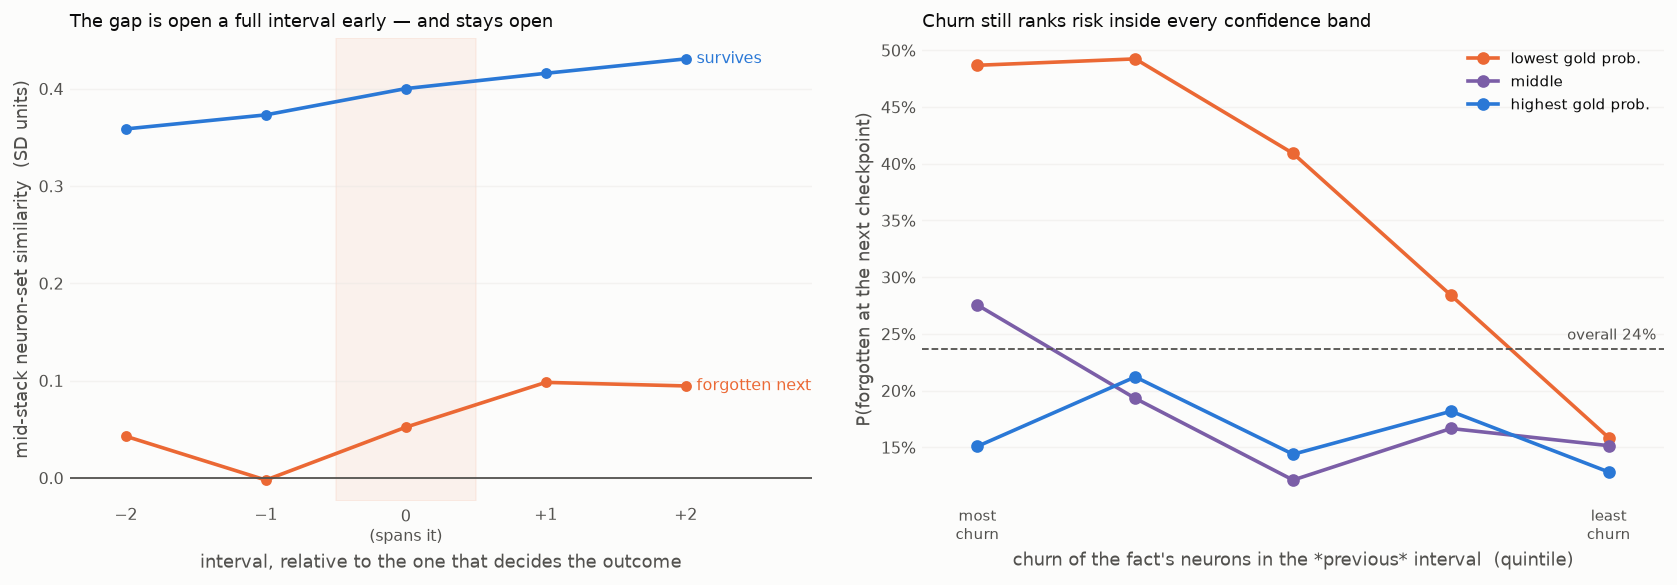

rho(backward churn, forgotten-next) = +0.213
  within gold-prob terciles: +0.259 +0.105 +0.029   (mean +0.131)
  same for gold_prob itself: +0.134 -0.054 +0.087   (mean +0.056)


In [22]:
# §14b — event-centred churn, and the same signal after conditioning on gold probability
mid_cos = np.nanmean(ZA_COS[:, :, MID], 2)                 # (n_facts, n_intervals)
TAUS = [-2, -1, 0, 1, 2]

def event_curve(sel_forget):
    """Median mid-stack churn at interval offsets around a transition, for the
    forgotten (or surviving) transitions.  Offset 0 is the interval that spans
    the outcome, -1 the one before it."""
    med = []
    for tau in TAUS:
        v = []
        for t in range(n_steps - 1):
            g = correct[:, t] & ((~correct[:, t + 1]) if sel_forget else correct[:, t + 1])
            j = t + tau
            if 0 <= j < n_steps - 1:
                v.append(mid_cos[g, j])
        med.append(np.nanmedian(np.concatenate(v)))
    return np.array(med)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for sel, col, lab in ((False, BLUE, "survives"), (True, ORANGE, "forgotten next")):
    y = event_curve(sel)
    ax1.plot(TAUS, y, color=col, lw=2, marker="o", ms=5, label=lab)
    ax1.annotate(lab, (TAUS[-1], y[-1]), color=col, fontsize=9,
                 xytext=(6, 0), textcoords="offset points", va="center")
ax1.axvspan(-0.5, 0.5, color=ORANGE, alpha=.07, zorder=0)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_xticks(TAUS, ["−2", "−1", "0\n(spans it)", "+1", "+2"])
ax1.set_xlim(-2.4, 2.9)
ax1.set_xlabel("interval, relative to the one that decides the outcome")
ax1.set_ylabel("mid-stack neuron-set similarity  (SD units)")
ax1.set_title("The gap is open a full interval early — and stays open", loc="left", fontsize=10)

# --- right: hazard by backward-churn quintile, within gold-probability terciles
bwd = np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1)            # churn INTO the current checkpoint
gpA = P["gold_prob"].to_numpy()[AF, AT]
gt = pd.qcut(gpA, 3, labels=False, duplicates="drop")
TER = ["lowest gold prob.", "middle", "highest gold prob."]
for g, col in zip(range(3), (ORANGE, PURPLE, BLUE)):
    m = gt == g
    q = pd.qcut(bwd[m], 5, labels=False, duplicates="drop")
    hz = np.array([AFG[m][q == i].mean() for i in range(q.max() + 1)])
    ax2.plot(range(len(hz)), hz, color=col, lw=2, marker="o", ms=6, label=TER[g])
ax2.axhline(AFG.mean(), color=INK2, ls="--", lw=1)
ax2.text(4.3, AFG.mean() + .008, f"overall {AFG.mean():.0%}", ha="right", fontsize=8.5, color=INK2)
ax2.set_xticks(range(5), ["most\nchurn", "", "", "", "least\nchurn"], fontsize=8.5)
ax2.set_xlim(-0.35, 4.35)
ax2.set_xlabel("churn of the fact's neurons in the *previous* interval  (quintile)")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_ylabel("P(forgotten at the next checkpoint)")
ax2.set_title("Churn still ranks risk inside every confidence band", loc="left", fontsize=10)
ax2.legend(loc="upper right", fontsize=8.5)

for ax in (ax1, ax2):
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

from scipy.stats import spearmanr
print(f"rho(backward churn, forgotten-next) = {spearmanr(-bwd, AFG)[0]:+.3f}")
_w = [spearmanr(-bwd[gt == g], AFG[gt == g])[0] for g in range(3)]
print("  within gold-prob terciles:", " ".join(f"{v:+.3f}" for v in _w),
      f"  (mean {np.mean(_w):+.3f})")
_gw = [spearmanr(-gpA[gt == g], AFG[gt == g])[0] for g in range(3)]
print("  same for gold_prob itself:", " ".join(f"{v:+.3f}" for v in _gw),
      f"  (mean {np.mean(_gw):+.3f})")

**Result — the instability is real, it is broad, and it arrives a full interval
early.** At the answer position the soon-to-be-forgotten facts' neuron sets move
significantly more at 14 of 18 layers, with the gap deepest at **layers 5–6 (−0.38 / −0.44 SD)**
and **layers 8–11 (−0.28 to −0.39 SD)**; the four exceptions are layers 0, 4 and 14–15,
where the two groups are indistinguishable — and at layer 4 the backward measurement puts
the *survivors* ahead, the one place in the stack where instability is not a bad sign. The **backward** curve — measured before the flip, so it
cannot be an echo of it — is almost superimposed on the concurrent one, and at layer 11
it is actually *deeper* (−0.43 vs −0.37). Layer 11 is boundary 12 in §8's indexing:
**the layer where §8 found the logit-lens gap to peak is the layer where the backward
neuron churn is largest.** Two independent measurements, one from the output
projection and one from the raw activations, put the failure in the same place.

The two positions differ in shape as Geva et al. (2023) would predict. At the
**subject's last token** the gap opens at layer 1 and stays wide through layer 8
(−0.24 to −0.44, deepest at layers 6–8) — the subject-enrichment stage is already
unstable. At the **answer
position** the deep region is layers 8–11, one stage later, where the attribute should
be extracted into the answer slot.

**And it survives conditioning on confidence, where `gold_prob` does not.** Ranking
transitions by the previous interval's churn gives ρ = **+0.213** with being forgotten
next; inside gold-probability terciles the mean is **+0.131**, against **+0.056** for
`gold_prob` ranked against itself the same way. In other words, churn is not a
repackaging of "this fact was weakly stored". The honest qualification is that the
effect is concentrated in the low-confidence band: within the *lowest* tercile the
hazard falls 49% → 16% from the most- to the least-churning quintile (ρ = +0.259),
within the middle tercile 28% → 15% (+0.105), but within the highest tercile it is
essentially flat (15% → 13%, ρ = +0.029). Churn tells you which of the *marginal*
facts will go; among facts the model holds confidently it adds little.

## 15 — How is a *correctly recalled* fact stored?

**Papers:** Dai et al. (2022), *Knowledge Neurons in Pretrained Transformers* (ACL);
Geva et al. (2021) (EMNLP); Gurnee et al. (2023), *Finding Neurons in a Haystack*
(TMLR); Kim et al. (2024), *Knowledge Entropy Decay during Language Model Pretraining
Hinders New Knowledge Acquisition* (arXiv; ICLR 2025).

§14 is about *change*. This section asks a static question: pooling all 17 030
(fact, checkpoint) cells, does the *shape* of a fact's activation differ between the
cells where it is recalled and the cells where it is not?

Two candidate signatures, and they are not the same claim:

- **Concentration.** The knowledge-neuron picture (Dai et al. 2022) says a stored fact
  is carried by a few strongly-active units. Prediction: lower participation ratio when
  correct.
- **Genericity.** Superposition (Elhage et al. 2022; Gurnee et al. 2023) says rare
  features share units with everything else. Whether *sharing* helps or hurts factual
  recall is genuinely open, so this is a measurement rather than a test.

Kim et al. (2024) additionally claim that over pretraining the FFN's "knowledge
entropy" **decays** — models come to rely on fewer memory units as training proceeds.
That is a claim about the trajectory rather than about correctness, and the second cell
tests it directly.

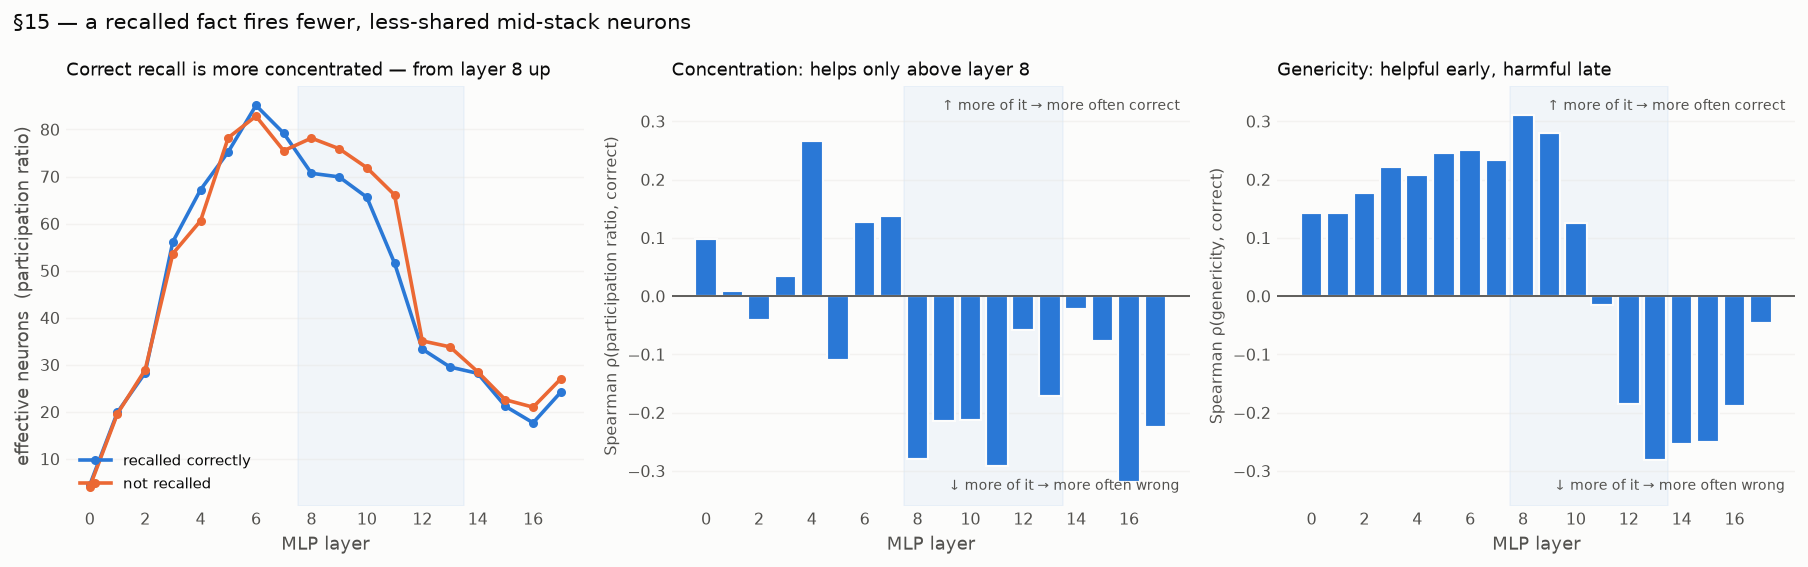

mid-stack (layers 8–13), pooled over 17030 (fact, checkpoint) cells:
  participation ratio  correct  52.4  wrong  60.4   ρ = -0.275
  genericity           correct 0.187  wrong 0.179   ρ = +0.058


  ρ(PR, correct)  is negative at every layer from L8 up: yes;  strongest L16 (-0.319)
  ρ(GEN, correct) peaks at L8 (+0.310) and reverses to L13 (-0.281)


In [23]:
# §15 — how a *correct* fact is stored: concentration and genericity, layer by layer
from scipy.stats import spearmanr

rho_pr  = np.array([spearmanr(NA["PR"][:, :, l].ravel(),  correct.ravel())[0] for l in range(n_mlp)])
rho_gen = np.array([spearmanr(NA["GEN"][:, :, l].ravel(), correct.ravel())[0] for l in range(n_mlp)])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
ax = axes[0]
for m, col, lab in ((correct, BLUE, "recalled correctly"), (~correct, ORANGE, "not recalled")):
    y = np.array([np.nanmedian(NA["PR"][:, :, l][m]) for l in range(n_mlp)])
    ax.plot(xlayer, y, color=col, lw=2, marker="o", ms=4, label=lab)
ax.set_ylabel("effective neurons  (participation ratio)")
ax.set_title("Correct recall is more concentrated — from layer 8 up", loc="left", fontsize=10)
ax.legend(loc="lower left", fontsize=8.5)

for ax, r, lab, title in ((axes[1], rho_pr, "participation ratio",
                           "Concentration: helps only above layer 8"),
                          (axes[2], rho_gen, "genericity",
                           "Genericity: helpful early, harmful late")):
    # signed quantity around a zero baseline -- direction already encodes the sign,
    # so a single hue is enough and cannot collide with the series colours elsewhere.
    ax.bar(xlayer, r, color=BLUE, edgecolor=SURF, linewidth=1.2, width=.82)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_ylim(-.36, .36)
    ax.set_ylabel(f"Spearman ρ({lab}, correct)", fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.annotate("↑ more of it → more often correct", (0.98, 0.97), xycoords="axes fraction",
                color=INK2, fontsize=8, va="top", ha="right")
    ax.annotate("↓ more of it → more often wrong", (0.98, 0.03), xycoords="axes fraction",
                color=INK2, fontsize=8, va="bottom", ha="right")
for ax in axes:
    ax.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
    ax.set_xticks(range(0, n_mlp, 2))
    ax.set_xlabel("MLP layer")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§15 — a recalled fact fires fewer, less-shared mid-stack neurons",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_pr = np.nanmean(NA["PR"][:, :, MID], 2); _gen = np.nanmean(NA["GEN"][:, :, MID], 2)
print(f"mid-stack (layers 8–13), pooled over {correct.size} (fact, checkpoint) cells:")
print(f"  participation ratio  correct {np.nanmedian(_pr[correct]):5.1f}  "
      f"wrong {np.nanmedian(_pr[~correct]):5.1f}   ρ = {spearmanr(_pr.ravel(), correct.ravel())[0]:+.3f}")
print(f"  genericity           correct {np.nanmedian(_gen[correct]):5.3f}  "
      f"wrong {np.nanmedian(_gen[~correct]):5.3f}   ρ = {spearmanr(_gen.ravel(), correct.ravel())[0]:+.3f}")
print(f"  ρ(PR, correct)  is negative at every layer from L8 up: "
      f"{'yes' if (rho_pr[8:] < 0).all() else 'no'};  strongest L{np.argmin(rho_pr)} ({rho_pr.min():+.3f})")
print(f"  ρ(GEN, correct) peaks at L{np.argmax(rho_gen)} ({rho_gen.max():+.3f}) and "
      f"reverses to L{np.argmin(rho_gen)} ({rho_gen.min():+.3f})")

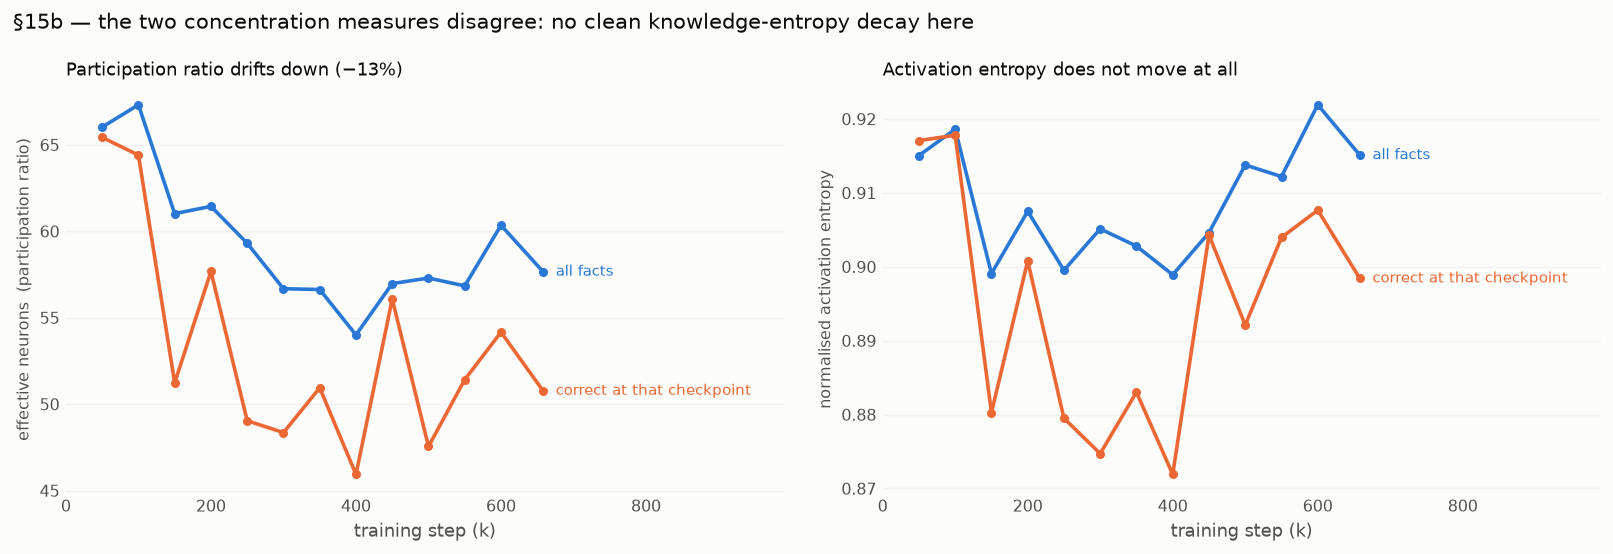

  mid-stack participation ratio   66.023 @50k ->  57.657 @658k  (-12.7%),  ρ(step, per-fact value) = -0.321


  mid-stack activation entropy     0.915 @50k ->   0.915 @658k  (+0.0%),  ρ(step, per-fact value) = +0.008
  (PR is driven by the largest activations, H by the whole top-128 tail; only the former moves, so 'the mid-stack concentrates' holds for the peak and not for the bulk)


In [24]:
# §15b — does the mid-stack concentrate over pretraining?  (the "knowledge entropy decay" claim)
xk = [s / 1000 for s in steps]
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))
for ax, key, ylab in ((axes[0], "PR", "effective neurons  (participation ratio)"),
                      (axes[1], "H",  "normalised activation entropy")):
    M = np.nanmean(NA[key][:, :, MID], 2)
    for y, col, lab in ((np.array([np.nanmedian(M[:, t]) for t in range(n_steps)]), BLUE, "all facts"),
                        (np.array([np.nanmedian(M[correct[:, t], t]) for t in range(n_steps)]),
                         ORANGE, "correct at that checkpoint")):
        ax.plot(xk, y, color=col, lw=2, marker="o", ms=4, label=lab)
        ax.annotate(lab, (xk[-1], y[-1]), color=col, fontsize=8.5, va="center",
                    xytext=(7, 0), textcoords="offset points")
    ax.set_xlim(0, 990)
    ax.set_xlabel("training step (k)")
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].set_title("Participation ratio drifts down (−13%)", loc="left", fontsize=10)
axes[1].set_title("Activation entropy does not move at all", loc="left", fontsize=10)
fig.suptitle("§15b — the two concentration measures disagree: no clean knowledge-entropy decay here",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_step_idx = np.tile(np.arange(n_steps), len(ids))
for key, nm in (("PR", "participation ratio"), ("H", "activation entropy")):
    m = np.nanmean(NA[key][:, :, MID], 2)
    a, b = np.nanmedian(m[:, 0]), np.nanmedian(m[:, -1])
    print(f"  mid-stack {nm:20s} {a:7.3f} @50k -> {b:7.3f} @658k  ({b/a - 1:+.1%}),  "
          f"ρ(step, per-fact value) = {spearmanr(_step_idx, m.ravel())[0]:+.3f}")
print("  (PR is driven by the largest activations, H by the whole top-128 tail; only the "
      "former moves, so 'the mid-stack concentrates' holds for the peak and not for the bulk)")

**Result — concentration goes with correct recall, but only above layer 8, and
genericity reverses sign with depth.** Mid-stack (layers 8–13), a correctly recalled
fact fires **52.4** effective neurons against **60.4** when it is not recalled
(ρ = −0.275); ρ(participation ratio, correct) is negative at *every* layer from 8 up
and is strongest at layer 16 (−0.319). Below layer 8 the sign is unstable and at layer
4 it is firmly *positive* (+0.26) — early-layer diffuseness is if anything a good sign.
So "a recalled fact fires fewer neurons" is a mid-and-upper-stack statement, not a
global one, and it is the Dai et al. (2022) knowledge-neuron prediction confirmed on
the one axis the dump measures directly.

Genericity does something more interesting: ρ(genericity, correct) climbs to **+0.310
at layer 8** and then flips to **−0.281 at layer 13**. A recalled fact rides on
*widely-shared* units through the early and lower-middle stack and on *private* units
near the top. Read with §12 — where `num_competitive_facts` was the one frequency-like
variable that *raised* the forgetting hazard — this gives that result a mechanism to
sit on: sharing is how a fact gets processed, privacy is how it gets emitted, and the
facts that must be emitted from shared machinery are the ones competition hurts.

**The Kim et al. trajectory claim does not replicate cleanly here.** Mid-stack
participation ratio does fall over pretraining, 66.0 → 57.7 (−12.7%, ρ = −0.321), but
the normalised activation entropy over the same neurons is **flat** (0.915 → 0.915,
ρ = +0.008). The two measures differ in what they weight: the participation ratio is
dominated by the largest activations, the entropy by the whole top-128 tail. So the
*peak* of the mid-stack activation sharpens over training while its *bulk* does not
redistribute at all. Whatever concentration is happening is confined to the head of the
distribution, and on this data "knowledge entropy decays over pretraining" is not
supported in the form its name suggests. (Caveat: a top-128 truncation cannot see the
tail beyond rank 128, which is where a genuine entropy change might live.)

## 16 — Do the neurons beat the output scalars at predicting forgetting?

**Papers:** Toneva et al. (2019); Swayamdipta et al. (2020); Ramasesh et al. (2021).

This is the section §10 asked for. §10 showed real correctness is far more persistent
than a re-sampling of the same gold probabilities would be, which is a proof *by
elimination* that a fact carries state the output scalar misses. The natural follow-up
is to name that state — and the test is whether it buys predictive accuracy the output
scalars cannot.

Rules, tightened so the answer means something:

1. **Strictly ante-hoc.** Every feature is measured at checkpoint *t* or over the
   interval ending at *t*. Nothing looks at *t+1*. This drops the concurrent churn that
   §14 used descriptively, and drops the first checkpoint.
2. **Grouped cross-validation.** Folds split on the **fact**, so a fact's transitions
   never straddle train and test and the model cannot score itself by memorising a fact.
3. **A real baseline.** Not `gold_prob` alone but all four output scalars —
   `gold_prob`, `gold_rank`, `answer_margin`, `pred_entropy` — the best §§2–5 had.

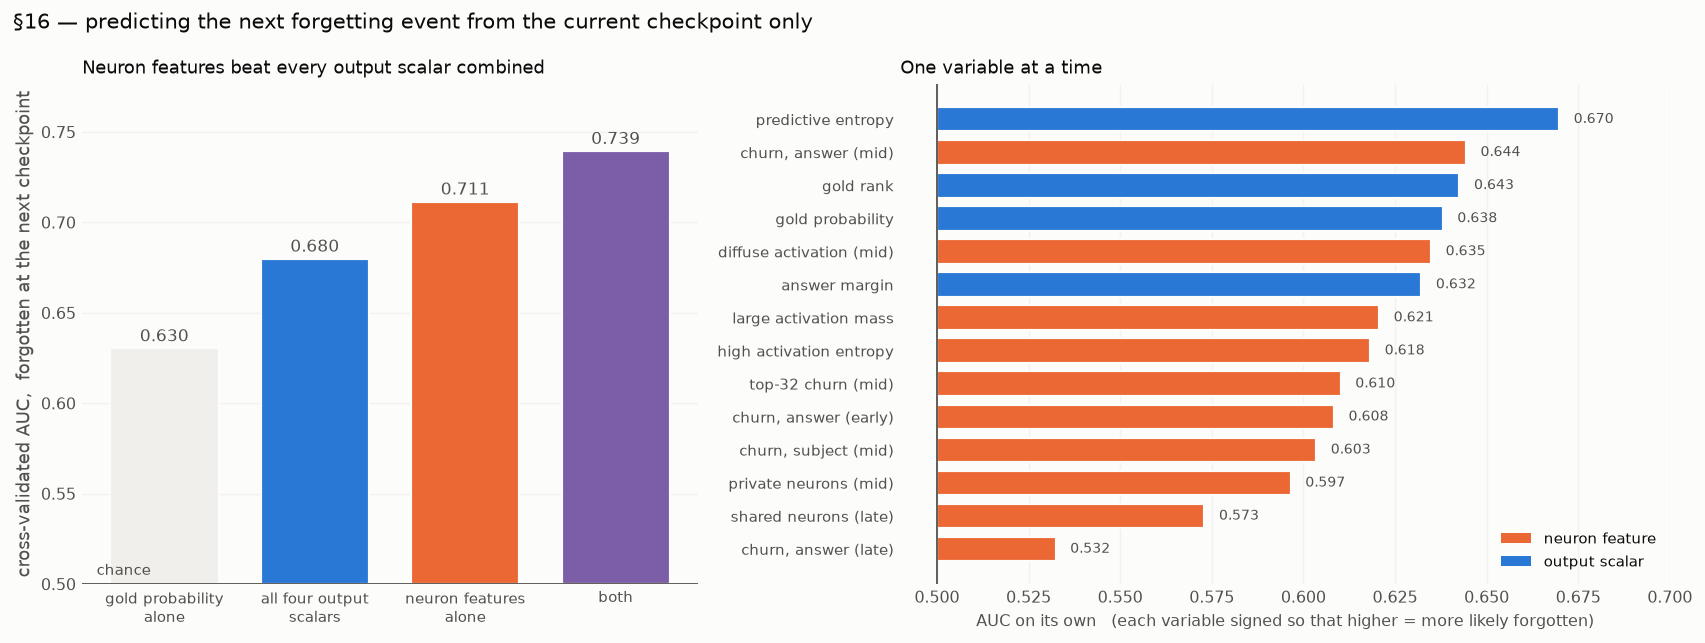

3965 ante-hoc transitions from 701 facts, base rate 23.7%
  gold probability alone     CV AUC 0.630
  all four output scalars    CV AUC 0.680
  neuron features alone      CV AUC 0.711
  both                       CV AUC 0.739


In [25]:
# §16 — do the neurons say anything the output scalars do not?
#        Everything here is strictly ante-hoc: measured at t, or over the interval
#        that ENDS at t.  Nothing may look at checkpoint t+1.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import rankdata

def auc1(score, y):
    m = np.isfinite(score); score, y = score[m], y[m].astype(bool)
    r = rankdata(score); n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def band(D, key, sl, back=0):
    return np.nanmean(D[key][AF, AT - back][:, sl], 1)

OUT_SCALARS = {                       # what §§2-5 already had
    "gold probability":       -P["gold_prob"].to_numpy()[AF, AT],
    "gold rank":               np.log10(np.clip(P["gold_rank"].to_numpy()[AF, AT], 1, None)),
    "answer margin":          -P["answer_margin"].to_numpy()[AF, AT],
    "predictive entropy":      P["pred_entropy"].to_numpy()[AF, AT],
}
NEURON_SCALARS = {                    # new, from the top-128 dump
    "churn, answer (mid)":    -np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1),
    "churn, answer (early)":  -np.nanmean(ZA_COS[AF, AT - 1][:, :8], 1),
    "churn, answer (late)":   -np.nanmean(ZA_COS[AF, AT - 1][:, 14:], 1),
    "churn, subject (mid)":   -np.nanmean(ZS_COS[AF, AT - 1][:, MID], 1),
    "top-32 churn (mid)":     -np.nanmean(ZA_J32[AF, AT - 1][:, MID], 1),
    "diffuse activation (mid)":  band(NA, "PR", MID),
    "high activation entropy":   band(NA, "H", MID),
    "private neurons (mid)":  -band(NA, "GEN", MID),
    "shared neurons (late)":   band(NA, "GEN", slice(12, 16)),
    "large activation mass":   np.log10(np.clip(band(NA, "L1", MID), 1, None)),
}
X_out = np.column_stack(list(OUT_SCALARS.values()))
X_neu = np.column_stack(list(NEURON_SCALARS.values()))

def cv_auc(X, seed=0):
    """5-fold CV with the *fact* as the group: a fact's 12 transitions never straddle
    a split, so the model cannot memorise a fact and score itself."""
    X = np.nan_to_num(X, nan=0.0); oof = np.zeros(len(X))
    for tr, te in GroupKFold(n_splits=5).split(X, AFG, groups=AF):
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X[tr], AFG[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return roc_auc_score(AFG, oof)

BLOCKS = [("gold probability\nalone", X_out[:, :1], NEUTRAL),
          ("all four output\nscalars", X_out, BLUE),
          ("neuron features\nalone", X_neu, ORANGE),
          ("both", np.column_stack([X_out, X_neu]), PURPLE)]
aucs = [cv_auc(X) for _, X, _ in BLOCKS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0),
                               gridspec_kw={"width_ratios": [1, 1.25]})
ax1.bar(range(len(BLOCKS)), [a - .5 for a in aucs], bottom=.5,   # bar length = lift over chance
        color=[c for _, _, c in BLOCKS], edgecolor=SURF, linewidth=1.2, width=.72)
for i, v in enumerate(aucs):
    ax1.text(i, v + .004, f"{v:.3f}", ha="center", fontsize=9.5, color=INK2)
ax1.axhline(0.5, color=INK2, lw=1)
ax1.text(-0.45, 0.503, "chance", ha="left", va="bottom", fontsize=8.5, color=INK2)
ax1.set_xticks(range(len(BLOCKS)), [b[0] for b in BLOCKS], fontsize=8.5)
ax1.set_ylim(0.5, max(aucs) * 1.05)
ax1.set_ylabel("cross-validated AUC,  forgotten at the next checkpoint")
ax1.set_title("Neuron features beat every output scalar combined", loc="left", fontsize=10)

single = [(k, auc1(v, AFG), ORANGE) for k, v in NEURON_SCALARS.items()] + \
         [(k, auc1(v, AFG), BLUE) for k, v in OUT_SCALARS.items()]
single.sort(key=lambda r: r[1])
yp = np.arange(len(single))
ax2.barh(yp, [s[1] - .5 for s in single], left=.5, color=[s[2] for s in single],
         edgecolor=SURF, linewidth=1.2, height=.74)
for i, (k, v, _) in enumerate(single):
    ax2.text(v + (.004 if v > .5 else -.004), i, f"{v:.3f}", va="center",
             ha="left" if v > .5 else "right", fontsize=8, color=INK2)
ax2.axvline(.5, color=INK2, lw=1)
ax2.set_yticks(yp, [s[0] for s in single], fontsize=8.5)
ax2.set_xlim(.49, .70)
ax2.set_xlabel("AUC on its own   (each variable signed so that higher = more likely forgotten)",
               fontsize=9)
ax2.set_title("One variable at a time", loc="left", fontsize=10)
from matplotlib.patches import Patch
ax2.legend(handles=[Patch(facecolor=ORANGE, label="neuron feature"),
                    Patch(facecolor=BLUE, label="output scalar")],
           loc="lower right", fontsize=8.5)
for ax in (ax1, ax2):
    ax.set_axisbelow(True)
    ax.grid(axis="y" if ax is ax1 else "x", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§16 — predicting the next forgetting event from the current checkpoint only",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{AFG.size} ante-hoc transitions from {len(np.unique(AF))} facts, "
      f"base rate {AFG.mean():.1%}")
for (nm, _, _), v in zip(BLOCKS, aucs):
    print(f"  {nm.replace(chr(10), ' '):26s} CV AUC {v:.3f}")

**Result — the neuron features win, and they win against the output scalars taken
together.** Over 3 965 ante-hoc transitions from 701 facts (base rate 23.7%):

| feature block | CV AUC |
|---|---|
| `gold_prob` alone | 0.630 |
| all four output scalars | 0.680 |
| **neuron features alone** | **0.711** |
| both | **0.739** |

Ten summaries of a truncated top-128 dump, with no access to the vocabulary, beat every
output scalar the model exposes — and add **+0.059 AUC** on top of them, which is more
than the three extra output scalars add to `gold_prob` (+0.050). Single-variable, the
best neuron feature (mid-stack backward churn, 0.644) edges out `gold_prob` (0.638) and
`gold_rank` (0.643), though `pred_entropy` remains the strongest individual predictor
at 0.670.

This is the concrete answer to §10's closing complaint. The state that made real
forgetting 2.2× more persistent than the calibrated null is not mysterious: a
substantial part of it is *which mid-stack neurons the fact is currently sitting on and
how much they have been moving*. It also means the fragility story of §2 and §5 is
under-specified rather than wrong — "weakly stored" is measurable at the level of
units, not only as a low probability.

Two caveats. The absolute numbers are modest (0.739 AUC on a 23.7% base rate is useful
ranking, not a reliable alarm), and the gain is partly the gain of *ten* features over
*four* — though the block comparison is cross-validated with the fact as the group, so
it is not overfitting in the ordinary sense.

## 17 — When a fact comes back, does it come back to the same neurons?

**Papers:** Kotha et al. (2024), *Understanding Catastrophic Forgetting in Language
Models via Implicit Inference* (ICLR); Chang et al. (2024), *How Do Large Language
Models Acquire Factual Knowledge During Pretraining?* (NeurIPS); Toneva et al. (2019).

§9 and §10 established that half of all forgetting events reverse within one
checkpoint — this is oscillation far more than erasure. That raises a mechanistic
question the neuron dump can answer and the output scalars cannot: **is relearning a
restoration or a rebuild?**

- *Restoration* — the fact was never really gone; the mid-stack circuit that carried it
  is recovered, so the state at *t+2* should sit closer to the pre-loss state at *t*
  than a still-wrong fact's does. This is the Kotha et al. reading, where forgetting is
  a competitor temporarily winning rather than the memory being destroyed.
- *Rebuild* — the fact is re-acquired on whatever units are available at *t+2*, with no
  special pull toward the old ones.

**A trap to avoid.** The two reference points are not on the same footing: similarity
to *t* spans two intervals and similarity to *t+1* spans one, so the lag-2 number is
mechanically the smaller of the pair for *every* fact. Comparing their levels would
just be measuring the lag. The valid test is the **difference in differences** — whether
the gap between the two references is *smaller* for facts that relearn — which is what
the `pull` score below measures.

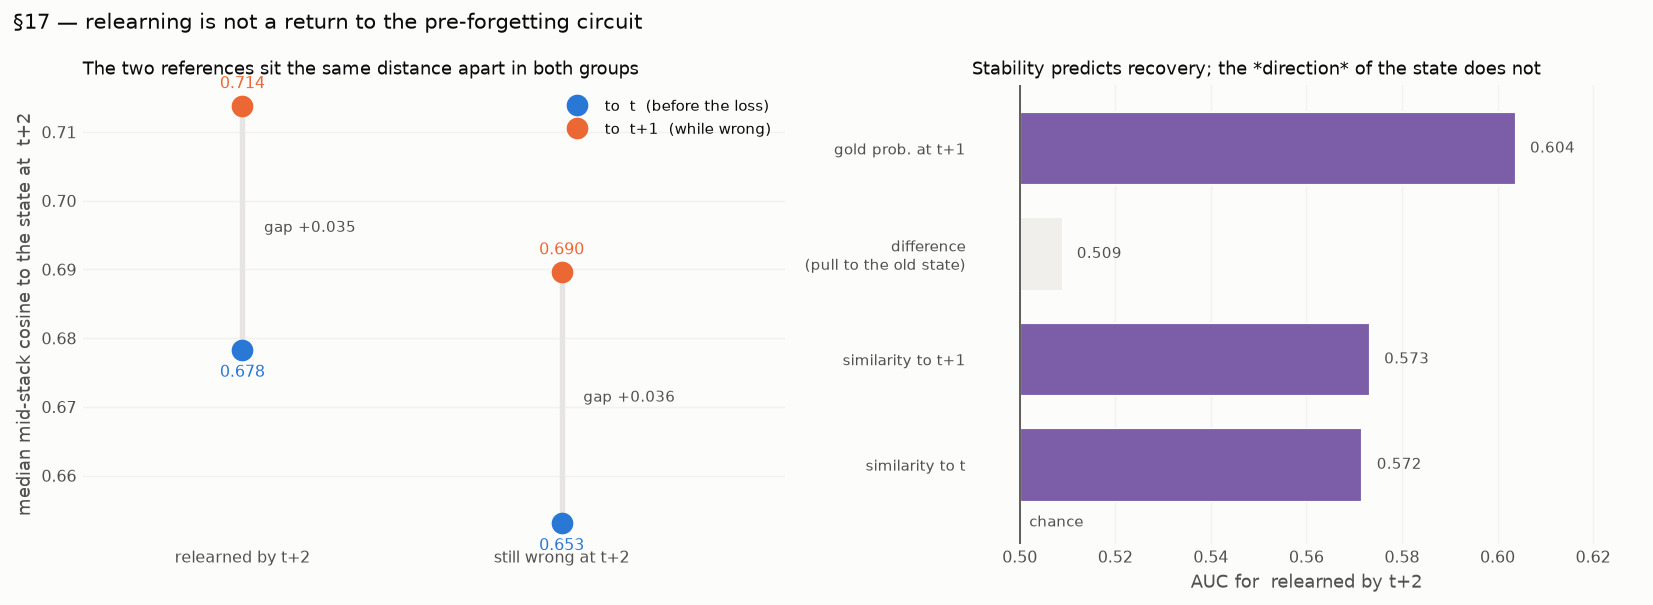

942 forgetting events with a t+2 checkpoint; 50.3% relearned
  similarity to t                  relearned +0.6783  still wrong +0.6531   AUC 0.572
  similarity to t+1                relearned +0.7138  still wrong +0.6896   AUC 0.573
  difference (pull to the old state) relearned -0.0333  still wrong -0.0341   AUC 0.509
  gold prob. at t+1                relearned +0.0868  still wrong +0.0351   AUC 0.604


In [26]:
# §17 — when a forgotten fact comes back, does it come back to the same neurons?
ev_f, ev_t = np.where(correct[:, :-1] & ~correct[:, 1:])
keep = ev_t + 2 < n_steps
ev_f, ev_t = ev_f[keep], ev_t[keep]
relearn = correct[ev_f, ev_t + 2]

# Similarity of the recovered state (t+2) to the state before the loss (t) vs to the
# state during it (t+1).  NA["COS2"][:, t] is the lag-2 pair (t, t+2).
#
# The two references are NOT on the same footing: one spans 100k steps of training and
# the other 50k, so the lag-2 number is mechanically the lower of the pair for every
# fact.  Their *levels* therefore say nothing.  What is comparable is the difference
# between the relearned and still-wrong groups, since the lag confound is identical in
# both -- i.e. the difference-in-differences, which is what `pull` scores below.
sim_pre  = np.nanmean(NA["COS2"][ev_f, ev_t][:, MID], 1)
sim_lost = np.nanmean(NA["COS"][ev_f, ev_t + 1][:, MID], 1)
pull = sim_pre - sim_lost

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.7),
                               gridspec_kw={"width_ratios": [1.05, 1]})
GROUPS = [("relearned by t+2", relearn), ("still wrong at t+2", ~relearn)]
for xi, (gname, m) in enumerate(GROUPS):
    a, b = np.nanmedian(sim_pre[m]), np.nanmedian(sim_lost[m])
    ax1.plot([xi, xi], [a, b], color=GRID, lw=3, zorder=1, solid_capstyle="round")
    ax1.plot(xi, a, "o", color=BLUE, ms=11, zorder=2,
             label="to  t  (before the loss)" if xi == 0 else None)
    ax1.plot(xi, b, "o", color=ORANGE, ms=11, zorder=2,
             label="to  t+1  (while wrong)" if xi == 0 else None)
    ax1.annotate(f"{a:.3f}", (xi, a), color=BLUE, fontsize=9, ha="center",
                 xytext=(0, -15), textcoords="offset points")
    ax1.annotate(f"{b:.3f}", (xi, b), color=ORANGE, fontsize=9, ha="center",
                 xytext=(0, 10), textcoords="offset points")
    ax1.annotate(f"gap {b - a:+.3f}", (xi, (a + b) / 2), color=INK2, fontsize=8.5,
                 xytext=(12, 0), textcoords="offset points", va="center")
ax1.set_xticks(range(len(GROUPS)), [g for g, _ in GROUPS])
ax1.set_xlim(-0.5, 1.7)
ax1.set_ylabel("median mid-stack cosine to the state at  t+2")
ax1.set_title("The two references sit the same distance apart in both groups",
              loc="left", fontsize=10)
ax1.legend(loc="upper right", fontsize=8.5)

SCORES = [("similarity to t", sim_pre), ("similarity to t+1", sim_lost),
          ("difference\n(pull to the old state)", pull),
          ("gold prob. at t+1", NEWP["gold_prob"][ev_f, ev_t + 1])]
a = [auc1((v - np.nanmean(v)) / np.nanstd(v), relearn) for _, v in SCORES]
ax2.barh(np.arange(len(a)), [v - .5 for v in a], left=.5,
         color=[PURPLE if abs(v - .5) > .03 else NEUTRAL for v in a],
         edgecolor=SURF, linewidth=1.2, height=.7)
for i, v in enumerate(a):
    ax2.text(v + .003, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
ax2.axvline(.5, color=INK2, lw=1)
ax2.text(.502, -0.62, "chance", fontsize=8.5, color=INK2, va="bottom")
ax2.set_yticks(np.arange(len(a)), [s[0] for s in SCORES], fontsize=8.5)
ax2.set_ylim(-0.75, len(a) - 0.4)
ax2.set_xlim(.49, .63)
ax2.set_xlabel("AUC for  relearned by t+2")
ax2.set_title("Stability predicts recovery; the *direction* of the state does not",
              loc="left", fontsize=10)
for ax, axis in ((ax1, "y"), (ax2, "x")):
    ax.set_axisbelow(True)
    ax.grid(axis=axis, alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§17 — relearning is not a return to the pre-forgetting circuit",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{len(ev_f)} forgetting events with a t+2 checkpoint; {relearn.mean():.1%} relearned")
for nm, v in SCORES:
    z = (v - np.nanmean(v)) / np.nanstd(v)
    print(f"  {nm.replace(chr(10),' '):32s} relearned {np.nanmedian(v[relearn]):+.4f}  "
          f"still wrong {np.nanmedian(v[~relearn]):+.4f}   AUC {auc1(z, relearn):.3f}")

**Result — relearning is a rebuild, not a restoration. This is a clean null.** Across
942 forgetting events with a *t+2* checkpoint (50.3% relearned), the gap between the
two reference points is **+0.035** for facts that come back and **+0.036** for facts
that stay wrong — identical to three decimal places. The `pull` score's AUC is
**0.509**, chance. There is no measurable tendency for a recovered fact to return to
the circuit it had before it was lost.

What *does* predict recovery is unremarkable by comparison: overall representational
stability (AUC 0.572 and 0.573 for the two raw similarities — a fact whose neurons move
less is likelier to be correct again, which §14 already implies) and how much
probability mass the gold answer retained *while wrong* (`gold_prob` at *t+1*, AUC
0.604 — the fact that never fully left).

This cuts against the strongest form of the Kotha et al. (2024) reading. In their
account forgetting is a competitor winning while the original mapping survives intact,
which predicts a return to the same machinery. At the resolution of a top-128 neuron
set at 50k-step intervals, that return does not happen — the fact reappears, but not
where it was. Two honest limits on that conclusion: 50k steps is a long time for a
circuit to be preserved through, and the dump's k = 128 truncation would miss a small
core of stable neurons hiding under a churning tail. §11d's cross-checkpoint activation
patching is the experiment that would settle it.

## 18 — Do relations own neurons?

**Papers:** Geva et al. (2023), *Dissecting Recall of Factual Associations in
Auto-Regressive Language Models* (EMNLP); Hernandez et al. (2024), *Linearity of
Relation Decoding in Transformer Language Models* (ICLR); Gurnee et al. (2023),
*Finding Neurons in a Haystack* (TMLR); Elhage et al. (2022), *Toy Models of
Superposition*.

§§13–17 treated each fact in isolation: its own neurons, its own churn. But the whole
point of asking about **competition** is that facts are not alone on their units. The
first question is therefore structural — *is the sharing organised?*

Geva et al. (2023) describe recall as a relation-general extraction step applied to a
subject-specific representation, and Hernandez et al. (2024) show that many relations
are decoded by a single linear map, which only makes sense if a relation has a
consistent internal implementation. Prediction: two facts of the **same relation**
should share far more mid-stack neurons than two facts picked at random.

The measurement is a fact × fact matrix of shared top-128 neurons, averaged over the
six mid-stack layers and all 13 checkpoints. Building it pairwise would be 858 000 set
intersections; instead each (checkpoint, layer) becomes a sparse incidence matrix
`B[fact, neuron]` and `B @ B.T` gives every pair's overlap in one product.

In [27]:
# §18 — fact x fact neuron sharing: who sits on whose units?
#        One sparse incidence matrix per (checkpoint, layer): B[f, u] = 1 if neuron u is in
#        fact f's top-128 there.  B @ B.T is then the number of shared neurons for every
#        pair at once -- 1310 x 1310, cheap, and far quicker than pairwise set intersections.
import scipy.sparse as sp
import time as _time

_t0 = _time.time()
ov_within = np.zeros(n_mlp)        # mean shared-neuron count, same-relation pairs
ov_cross = np.zeros(n_mlp)         # ... different-relation pairs
OV = np.zeros((len(ids), len(ids)), np.float32)     # mid-stack mean, the matrix we keep

same_prop = prop[:, None] == prop[None, :]
_off = ~np.eye(len(ids), dtype=bool)
_rows = np.repeat(np.arange(len(ids)), K_NEU)
for t, s in enumerate(steps):
    I = np.asarray(np.load(NEU_DIR / f"internal/neurons_step{s}_answer_idx.npy",
                           mmap_mode="r")[NROW]).astype(np.int32)
    for l in range(n_mlp):
        B = sp.csr_matrix((np.ones(_rows.size, np.float32), (_rows, I[:, l, :].ravel())),
                          shape=(len(ids), N_INTER))
        B.data[:] = 1.0                       # a neuron can repeat in a row only via the
        M = (B @ B.T).toarray()               # csr sum; force binary before the product
        ov_within[l] += M[same_prop & _off].mean()
        ov_cross[l] += M[~same_prop].mean()
        if MID.start <= l < MID.stop:
            OV += M
ov_within /= n_steps; ov_cross /= n_steps
OV /= n_steps * (MID.stop - MID.start)
np.fill_diagonal(OV, np.nan)                  # a fact always shares 128 with itself
print(f"overlap matrices in {_time.time() - _t0:.0f}s "
      f"({n_steps} checkpoints x {n_mlp} layers)")

_iu = np.triu_indices(len(ids), 1)
ov_pair, pair_same_prop = OV[_iu], same_prop[_iu]
print(f"mid-stack shared neurons out of {K_NEU}:  same relation "
      f"{np.nanmean(ov_pair[pair_same_prop]):.1f}   different relation "
      f"{np.nanmean(ov_pair[~pair_same_prop]):.1f}   "
      f"({np.nanmean(ov_pair[pair_same_prop]) / np.nanmean(ov_pair[~pair_same_prop]):.2f}x)")

# --- per-fact crowding, split by whether the crowd is the fact's own relation or not
_S = np.nan_to_num(OV, nan=0.0)
_n_same = (same_prop.sum(1) - 1).astype(float)
crowd_same = (_S * same_prop).sum(1) / np.maximum(_n_same, 1)
crowd_other = (_S * ~same_prop).sum(1) / (len(ids) - 1 - _n_same)

# --- the §12 competition variable, as a pair property: do facts that share a
#     `competitive_word` (the subject token that makes them confusable) share neurons?
_comp = pd.read_parquet("competition_df.parquet").set_index("id").reindex(ids)
cword = _comp["competitive_word"].to_numpy()
n_comp_facts = _comp["num_competitive_facts"].to_numpy(float)
pair_same_word = ((cword[:, None] == cword[None, :]) & ~pd.isna(cword)[:, None])[_iu]
print(f"{pair_same_word.sum()} of {pair_same_word.size} pairs share a competitive word")

overlap matrices in 886s (13 checkpoints x 18 layers)


mid-stack shared neurons out of 128:  same relation 50.8   different relation 18.1   (2.81x)


11225 of 857395 pairs share a competitive word


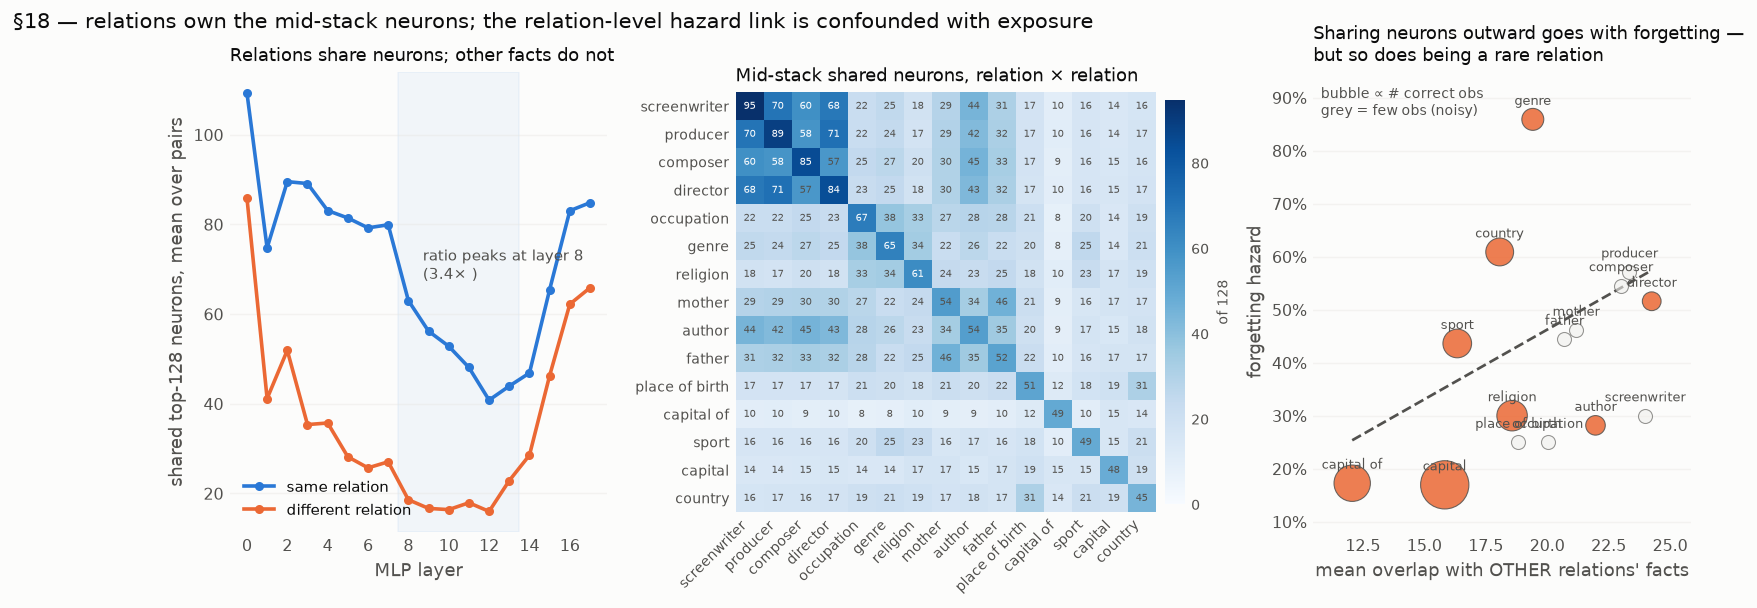

layer  within   cross  ratio
    0   109.4    85.9   1.27
    1    74.8    41.2   1.82
    2    89.5    51.9   1.72
    3    89.1    35.4   2.52
    4    83.1    35.7   2.33
    5    81.4    28.2   2.89
    6    79.2    25.7   3.08
    7    79.9    27.1   2.95
    8    63.0    18.6   3.39
    9    56.2    16.7   3.37
   10    52.8    16.4   3.22
   11    48.1    17.9   2.68
   12    40.8    16.0   2.55
   13    43.9    22.9   1.92
   14    46.9    28.5   1.64
   15    65.5    46.3   1.41
   16    83.1    62.2   1.33
   17    84.8    65.9   1.29

across the 8 relations with >= 30 correct observations:
  rho(self_ov  , hazard) = +0.310    rho(self_ov  , accuracy) = -0.595
  rho(out_ov   , hazard) = +0.524    rho(out_ov   , accuracy) = -0.881
  rho(exposure , hazard) = -0.762    rho(exposure , accuracy) = +0.857
          prop   n  n_obs  hazard   acc  self_ov  out_ov  exposure
    capital of 192    723   0.173 0.328   49.314  12.065   317.000
       capital 385   2396   0.170 0.536   47.

In [28]:
# §18 — do relations own neurons?
props_u = np.unique(prop)
REL = np.zeros((len(props_u), len(props_u)))
for i, a in enumerate(props_u):
    for j, b in enumerate(props_u):
        REL[i, j] = np.nanmean(OV[np.ix_(prop == a, prop == b)])
_ord = np.argsort(-np.diag(REL))
REL, props_o = REL[np.ix_(_ord, _ord)], props_u[_ord]

# per-relation hazard, recomputed here so the section stands alone
rel_rows = []
for p in props_u:
    m = prop == p
    cur, nxt = correct[m, :-1], correct[m, 1:]
    nobs = int(cur.sum())
    rel_rows.append(dict(prop=p, n=int(m.sum()), n_obs=nobs,
                         hazard=(cur & ~nxt).sum() / nobs if nobs else np.nan,
                         acc=correct[m].mean(),
                         self_ov=np.nanmean(OV[np.ix_(m, m)]),
                         out_ov=np.nanmean(OV[np.ix_(m, ~m)]),
                         exposure=np.median(exposure[m])))
rel_stats = pd.DataFrame(rel_rows)
REL_MIN_OBS = 30                        # same reliability bar §6a used

fig = plt.figure(figsize=(14.5, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 1.25, 1.05], wspace=.32)

ax1 = fig.add_subplot(gs[0])
ax1.plot(xlayer, ov_within, color=BLUE, lw=2, marker="o", ms=4, label="same relation")
ax1.plot(xlayer, ov_cross, color=ORANGE, lw=2, marker="o", ms=4, label="different relation")
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax1.set_xticks(range(0, n_mlp, 2))
ax1.set_xlabel("MLP layer")
ax1.set_ylabel(f"shared top-{K_NEU} neurons, mean over pairs")
ax1.set_title("Relations share neurons; other facts do not", loc="left", fontsize=10)
ax1.legend(loc="lower left", fontsize=8.5)
_r = ov_within / ov_cross
ax1.annotate(f"ratio peaks at layer {int(np.argmax(_r))}\n({_r.max():.1f}× )",
             (float(np.argmax(_r)), ov_within[int(np.argmax(_r))]), color=INK2, fontsize=8.5,
             xytext=(8, 12), textcoords="offset points")

ax2 = fig.add_subplot(gs[1])
im = ax2.imshow(REL, cmap="Blues", vmin=0, vmax=np.nanmax(REL))
ax2.set_xticks(range(len(props_o)), props_o, rotation=45, ha="right", fontsize=7.5)
ax2.set_yticks(range(len(props_o)), props_o, fontsize=7.5)
for i in range(len(props_o)):
    for j in range(len(props_o)):
        ax2.text(j, i, f"{REL[i, j]:.0f}", ha="center", va="center", fontsize=5.8,
                 color="white" if REL[i, j] > np.nanmax(REL) * .6 else INK2)
ax2.set_title("Mid-stack shared neurons, relation × relation", loc="left", fontsize=10)
cb = fig.colorbar(im, ax=ax2, fraction=.045, pad=.02)
cb.set_label(f"of {K_NEU}", fontsize=8); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)

ax3 = fig.add_subplot(gs[2])
_ok = rel_stats["n_obs"] >= REL_MIN_OBS
ax3.scatter(rel_stats.loc[~_ok, "out_ov"], rel_stats.loc[~_ok, "hazard"],
            s=60, color=NEUTRAL, edgecolor=INK2, linewidth=.6, alpha=.6, zorder=2)
ax3.scatter(rel_stats.loc[_ok, "out_ov"], rel_stats.loc[_ok, "hazard"],
            s=np.sqrt(rel_stats.loc[_ok, "n_obs"]) * 14 + 30, color=ORANGE,
            edgecolor=INK2, linewidth=.6, alpha=.85, zorder=2)
for _, r in rel_stats.iterrows():
    ax3.annotate(r["prop"], (r["out_ov"], r["hazard"]), fontsize=7, color=INK2,
                 xytext=(0, 8), textcoords="offset points", ha="center")
_b, _a = np.polyfit(rel_stats.loc[_ok, "out_ov"], rel_stats.loc[_ok, "hazard"], 1)
_xs = np.linspace(rel_stats.loc[_ok, "out_ov"].min(), rel_stats.loc[_ok, "out_ov"].max(), 30)
ax3.plot(_xs, _a + _b * _xs, color=INK2, ls="--", lw=1.5, zorder=1)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax3.set_xlabel("mean overlap with OTHER relations' facts")
ax3.set_ylabel("forgetting hazard")
ax3.set_title("Sharing neurons outward goes with forgetting —\nbut so does being a rare relation",
              loc="left", fontsize=10)
ax3.text(.02, .97, "bubble ∝ # correct obs\ngrey = few obs (noisy)", transform=ax3.transAxes,
         fontsize=7.5, color=INK2, va="top")
ax3.margins(x=.13, y=.13)

for ax in (ax1, ax3):
    ax.set_axisbelow(True); ax.grid(axis="y", alpha=.4)
for ax in (ax1, ax2, ax3):
    ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§18 — relations own the mid-stack neurons; the relation-level hazard link is confounded with exposure",
             x=0.01, ha="left", fontsize=11.5)
plt.show()

from scipy.stats import spearmanr
print(f"{'layer':>5s} {'within':>7s} {'cross':>7s} {'ratio':>6s}")
for l in range(n_mlp):
    print(f"{l:5d} {ov_within[l]:7.1f} {ov_cross[l]:7.1f} {ov_within[l]/ov_cross[l]:6.2f}")
_r = rel_stats[_ok]
print(f"\nacross the {len(_r)} relations with >= {REL_MIN_OBS} correct observations:")
for c in ("self_ov", "out_ov", "exposure"):
    print(f"  rho({c:9s}, hazard) = {spearmanr(_r[c], _r['hazard'])[0]:+.3f}    "
          f"rho({c:9s}, accuracy) = {spearmanr(_r[c], _r['acc'])[0]:+.3f}")
print(rel_stats.sort_values("out_ov").to_string(index=False, float_format=lambda v: f"{v:.3f}"))

**Result — relations own the mid-stack, and they own it exactly where §§13–17 said
facts live.** Two facts of the same relation share **63 of 128** top neurons at MLP
layer 8; two facts of different relations share **18.6** — a **3.4× ratio**, and it is
maximal at layers 8–9, the same band that is sparsest, most private and most volatile
(§13) and where the forgetting churn is deepest (§14). At the ends of the stack the
ratio collapses to ~1.3: layers 0–2 and 15–17 are shared by everything, so they cannot
be carrying relation identity.

The relation × relation heatmap shows the sharing is not a flat "same-relation bonus"
either. `screenwriter`, `producer`, `composer` and `director` form a visible block that
overlaps *each other* at 57–71 shared neurons — nearly as much as each overlaps itself —
which is a sensible thing for a model to do with four relations that all map a creative
work to a person. `capital` and `capital of` are the mirror case: high self-overlap
(48–49) and the *lowest* outward overlap in the table (12–16).

**The tempting relation-level story does not survive its confound, and it is worth
being explicit about that.** Relations whose facts bleed most into *other* relations do
have the highest forgetting hazard (ρ = +0.52) and the lowest accuracy (ρ = −0.88
across the 8 relations with ≥ 30 correct observations). But median exposure predicts the
same two outcomes *better* (ρ = −0.76 and +0.86), and outward overlap is itself strongly
anti-correlated with exposure. With only 8 usable relations there is no way to separate
them here. The honest reading is that **`capital` is not stable because it keeps its
neurons to itself — it is stable because it appears 840 times, and a relation seen 840
times also gets its own neurons.** Which of those is upstream is a question §19 takes to
the fact level, where there are 4 154 observations instead of 8.

## 19 — Crowding: does sitting on busy neurons predict forgetting?

**Papers:** Elhage et al. (2022), *Toy Models of Superposition*; Kandpal et al. (2023),
*Large Language Models Struggle to Learn Long-Tail Knowledge* (ICML); Mallen et al.
(2023), *When Not to Trust Language Models* (ACL); and §12 of this notebook.

§12 ended with a specific claim: of every frequency-like variable, **only competition**
— `num_competitive_facts`, the number of other facts sharing this fact's
`competitive_word` — raised the forgetting hazard. That was measured entirely in the
corpus. If it has a mechanical basis, it should be visible in the neurons, and this
section asks two questions about it.

**(1) Is crowding a hazard?** For each fact, average its mid-stack overlap with every
other fact, split into the crowd from its **own relation** and the crowd from **other
relations**. The superposition account (Elhage et al. 2022) says a feature squeezed
onto units that many other features use is the one that gets clobbered — so crowding
by *unrelated* facts should be the dangerous kind, and crowding by same-relation facts
might even be benign (they want the same computation).

**(2) Are §12's "competitive" facts actually neuron-mates?** `competitive_word` is a
corpus-level notion — two facts whose subjects share a token that makes them
confusable. Whether the model *represents* them together is a separate, testable claim:
do pairs sharing a competitive word have higher mid-stack overlap than matched pairs
that do not?

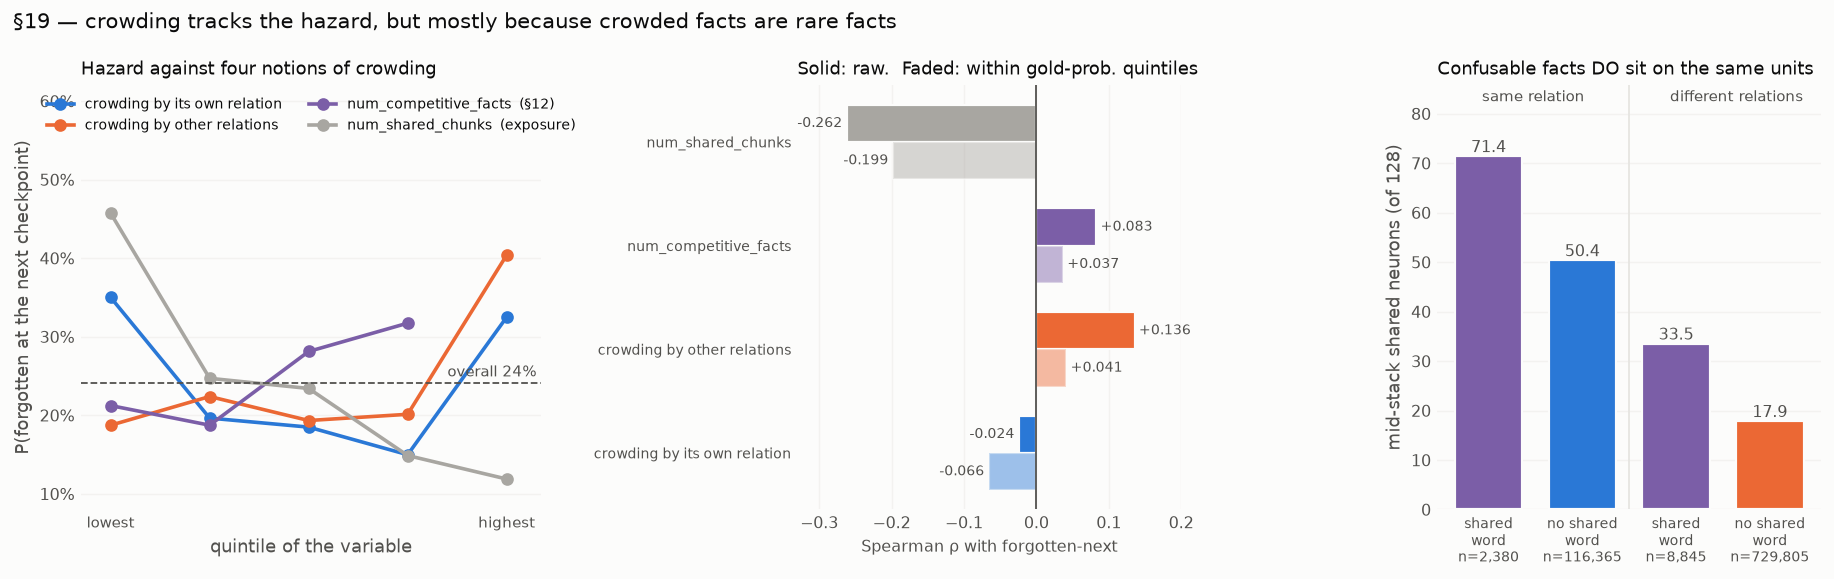

4154 transitions, base hazard 24.1%
  crowding by its own relation   rho=-0.024   within gold-prob quintiles -0.066
  crowding by other relations    rho=+0.136   within gold-prob quintiles +0.041
  num_competitive_facts  (§12)   rho=+0.083   within gold-prob quintiles +0.037
  num_shared_chunks  (exposure)  rho=-0.262   within gold-prob quintiles -0.199
  rho(crowding-by-others, exposure)            = -0.467
  rho(crowding-by-others, num_competitive_facts) = +0.296

mid-stack shared neurons, pairs sharing a competitive word 41.6 vs 22.4 (1.86x); across relations only 33.5 vs 17.9


In [29]:
# §19 — crowding at the fact level, and whether §12's "competition" is a neuron story
from scipy.stats import spearmanr

GREY = "#a8a6a1"      # NEUTRAL is a scatter fill; too faint for a bar or a line here
CROWD = [("crowding by its own relation", crowd_same, BLUE),
         ("crowding by other relations", crowd_other, ORANGE),
         ("num_competitive_facts  (§12)", n_comp_facts, PURPLE),
         ("num_shared_chunks  (exposure)", exposure.astype(float), GREY)]
gq5 = pd.qcut(P["gold_prob"].to_numpy()[XF, XT], 5, labels=False, duplicates="drop")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14.2, 4.5),
                                    gridspec_kw={"width_ratios": [1.2, 1, 1]})
raw, within = [], []
for name, v, col in CROWD:
    vt = v[XF]
    q = pd.qcut(vt, 5, labels=False, duplicates="drop")
    hz = [XFG[q == i].mean() for i in range(q.max() + 1)]
    ax1.plot(range(len(hz)), hz, color=col, lw=2, marker="o", ms=6, label=name)
    raw.append(spearmanr(vt, XFG)[0])
    within.append(np.nanmean([spearmanr(vt[gq5 == g], XFG[gq5 == g])[0]
                              for g in range(gq5.max() + 1) if (gq5 == g).sum() > 50]))
ax1.axhline(XFG.mean(), color=INK2, ls="--", lw=1)
ax1.text(4.3, XFG.mean() + .008, f"overall {XFG.mean():.0%}", ha="right", fontsize=8.5, color=INK2)
ax1.set_xticks(range(5), ["lowest", "", "", "", "highest"], fontsize=8.5)
ax1.set_xlim(-.3, 4.35)
ax1.set_xlabel("quintile of the variable")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax1.set_ylabel("P(forgotten at the next checkpoint)")
ax1.set_ylim(.08, .62)
ax1.set_title("Hazard against four notions of crowding", loc="left", fontsize=10)
ax1.legend(loc="upper center", ncol=2, fontsize=7.5)

yp = np.arange(len(CROWD)); w = .36
ax2.barh(yp + w/2, raw, w, color=[c for _, _, c in CROWD], edgecolor=SURF, linewidth=1.2)
ax2.barh(yp - w/2, within, w, color=[c for _, _, c in CROWD], edgecolor=SURF,
         linewidth=1.2, alpha=.45)
for y, (r, wi) in enumerate(zip(raw, within)):
    ax2.text(r + np.sign(r) * .006, y + w/2, f"{r:+.3f}", va="center", fontsize=8,
             ha="left" if r > 0 else "right", color=INK2)
    ax2.text(wi + np.sign(wi) * .006, y - w/2, f"{wi:+.3f}", va="center", fontsize=8,
             ha="left" if wi > 0 else "right", color=INK2)
ax2.axvline(0, color=INK2, lw=1)
ax2.set_yticks(yp, [c[0].split("  ")[0] for c in CROWD], fontsize=8)
ax2.set_xlim(-.33, .20)
ax2.set_xlabel("Spearman ρ with forgotten-next", fontsize=9)
ax2.set_title("Solid: raw.  Faded: within gold-prob. quintiles", loc="left", fontsize=10)

BARS = [("shared\nword", pair_same_word & pair_same_prop, PURPLE),
        ("no shared\nword", (~pair_same_word) & pair_same_prop, BLUE),
        ("shared\nword", pair_same_word & ~pair_same_prop, PURPLE),
        ("no shared\nword", (~pair_same_word) & ~pair_same_prop, ORANGE)]
h = [np.nanmean(ov_pair[m]) for _, m, _ in BARS]
ax3.bar(range(4), h, color=[c for _, _, c in BARS], edgecolor=SURF, linewidth=1.2, width=.72)
for i, v in enumerate(h):
    ax3.text(i, v + .8, f"{v:.1f}", ha="center", fontsize=9, color=INK2)
ax3.set_xticks(range(4), [f"{lab}\nn={m.sum():,}" for lab, m, _ in BARS], fontsize=7.5)
ax3.set_ylim(0, max(h) * 1.2)
ax3.set_ylabel(f"mid-stack shared neurons (of {K_NEU})")
ax3.set_title("Confusable facts DO sit on the same units", loc="left", fontsize=10)
ax3.axvline(1.5, color=GRID, lw=1)
ax3.text(.25, .99, "same relation", transform=ax3.transAxes, ha="center", va="top",
         fontsize=8.5, color=INK2)
ax3.text(.78, .99, "different relations", transform=ax3.transAxes, ha="center", va="top",
         fontsize=8.5, color=INK2)

for ax, axis in ((ax1, "y"), (ax2, "x"), (ax3, "y")):
    ax.set_axisbelow(True); ax.grid(axis=axis, alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§19 — crowding tracks the hazard, but mostly because crowded facts are rare facts",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{XFG.size} transitions, base hazard {XFG.mean():.1%}")
for (name, v, _), r, wi in zip(CROWD, raw, within):
    print(f"  {name:30s} rho={r:+.3f}   within gold-prob quintiles {wi:+.3f}")
print(f"  rho(crowding-by-others, exposure)            = {spearmanr(crowd_other, exposure)[0]:+.3f}")
print(f"  rho(crowding-by-others, num_competitive_facts) = "
      f"{spearmanr(crowd_other, n_comp_facts)[0]:+.3f}")
print(f"\nmid-stack shared neurons, pairs sharing a competitive word "
      f"{np.nanmean(ov_pair[pair_same_word]):.1f} vs {np.nanmean(ov_pair[~pair_same_word]):.1f} "
      f"({np.nanmean(ov_pair[pair_same_word]) / np.nanmean(ov_pair[~pair_same_word]):.2f}x); "
      f"across relations only {np.nanmean(ov_pair[pair_same_word & ~pair_same_prop]):.1f} vs "
      f"{np.nanmean(ov_pair[~pair_same_word & ~pair_same_prop]):.1f}")

**Result — the corpus-level competition variable really is a neuron-level fact, but
crowding itself is mostly a proxy for rarity.**

Taking (2) first, because it is unambiguous: pairs that share a competitive word share
**41.6** mid-stack neurons against **22.4** for pairs that do not — **1.86×**. This is
not just the same-relation effect: restricted to pairs from *different* relations it is
**33.5 vs 17.9**, the same 1.87× ratio. So §12's `competitive_word` is not merely a
string coincidence in the corpus; facts that share it are represented on substantially
the same mid-stack units. That is a real mechanistic finding, and it is what a
"competition" account needs as a precondition.

On (1), the two crowds behave as the superposition account predicts in **sign** but
weakly in **size**, and both shrink sharply under control:

| variable | ρ with forgotten-next | ρ within gold-probability quintiles |
|---|---|---|
| crowding by its own relation | −0.024 | **−0.066** |
| crowding by other relations | +0.136 | +0.041 |
| `num_competitive_facts` (§12) | +0.083 | +0.037 |
| `num_shared_chunks` (exposure) | **−0.262** | **−0.199** |

Crowding by *unrelated* facts is the harmful direction and crowding by the fact's *own*
relation is, if anything, mildly protective — exactly the asymmetry Elhage et al. would
predict, and a nice internal consistency check. But the effect is small, non-monotonic
(the hazard only jumps in the top quintile, 20% → 40%), and it is **half-explained by
exposure**: ρ(crowding-by-others, exposure) = −0.467, and once gold probability is
controlled the crowding signal falls to +0.041 while exposure keeps −0.199.

So the §18 confound resolves in favour of exposure at the fact level too. **Crowded
facts are mostly just rare facts.** Crowding survives as a weak independent signal, not
as the driver — which leaves the actual competition question, whether neuron-mates
*interfere*, still open. §20 tests it directly.

## 20 — The direct test: competition, or synchrony?

**Papers:** McCloskey & Cohen (1989), *Catastrophic Interference in Connectionist
Networks*; French (1999), *Catastrophic Forgetting in Connectionist Networks* (TiCS);
Ramasesh et al. (2021) (ICLR); Kotha et al. (2024) (ICLR).

This is the section the whole part is for. French (1999) states the classical
prediction as sharply as it can be stated: catastrophic interference is caused by
**representational overlap**, and reducing overlap — semi-distributed representations —
reduces forgetting. Translated to this data: *two facts that sit on the same mid-stack
neurons should take turns*. When one is right the other should be wrong; a fact's
forgetting event should be another fact's learning event.

Two tests, the second much stronger than the first.

**(a) Do neuron-mates' trajectories anti-correlate?** Correlate the two facts'
correctness trajectories after removing each fact's own mean (how often it is right)
and each checkpoint's mean (the global accuracy curve), and plot against their shared-
neuron count. Competition predicts the curve goes **down**, into negative correlation.
Because relations learn as blocks (§6b) and relations share neurons (§18), a second
version also removes each relation's own trajectory.

**(b) What do a fact's neuron-mates do at the exact moment it flips?** For every
forgetting event, take the fact's 20 *most*-overlapping partners from **other
relations** and its 20 *least*-overlapping ones, and measure how often each group is
forgotten and learned at that same transition. Near and far are compared inside the
same event, at the same checkpoint, across the same relation boundary — the only thing
that differs is the overlap (37.5 vs 9.5 shared neurons). Competition predicts the near
group *learns* while the fact is lost. Interference predicts the near group is *also*
lost. These are different cells of the 2 × 2 and cannot both be true.

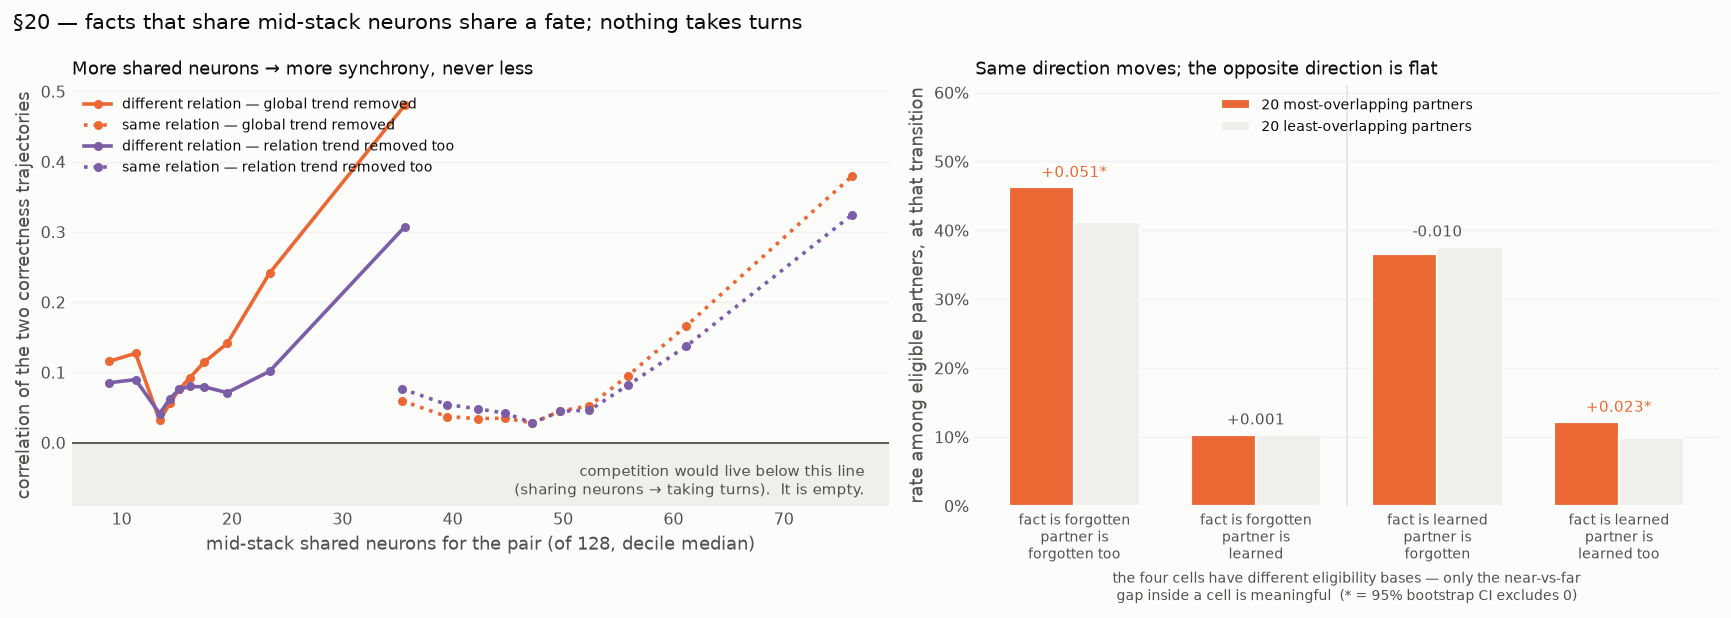

rho(shared neurons, co-fluctuation), global trend removed:
    same relation        +0.1354


    different relation   +0.1487
rho(shared neurons, co-fluctuation), relation trend removed too:
    same relation        +0.0840


    different relation   +0.0969

competitive-word pairs co-fluctuate +0.415 vs +0.136 for the rest (cross-relation only: +0.408 vs +0.144)

nearest vs farthest cross-relation partners (overlap 37.5 vs 9.5 shared neurons):
  fact forgotten -> partner is forgotten too near 0.462  far 0.412   diff +0.051 [+0.017, +0.091]
  fact forgotten -> partner is learned     near 0.103  far 0.102   diff +0.001 [-0.009, +0.011]
  fact learned   -> partner is forgotten   near 0.366  far 0.376   diff -0.010 [-0.039, +0.017]
  fact learned   -> partner is learned too near 0.122  far 0.099   diff +0.023 [+0.013, +0.031]


In [30]:
# §20 — the direct test: do neuron-sharing facts compete, or move together?
def cofluctuation(demean_relation):
    """Pearson correlation of two facts' correctness trajectories after removing the
    per-fact mean (how often it is right) and the per-checkpoint mean (the global
    accuracy curve).  With `demean_relation`, each relation's own trajectory goes too,
    so a relation learning as a block cannot manufacture the effect."""
    X = correct.astype(np.float32).copy()
    if demean_relation:
        for p in np.unique(prop):
            m = prop == p
            X[m] -= X[m].mean(0, keepdims=True)
    X = X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + X.mean()
    sd = X.std(1); a = sd > 1e-6
    Z = np.zeros_like(X); Z[a] = X[a] / sd[a][:, None]
    return ((Z @ Z.T) / n_steps)[_iu], (a[:, None] & a[None, :])[_iu]

cof_glob, pair_ok = cofluctuation(False)
cof_rel, _ = cofluctuation(True)

# nearest / farthest CROSS-relation partners: a within-event control that holds the
# relation, the checkpoint and the event itself fixed, and varies only the overlap.
NBR_M = 20
_Ox = np.where(same_prop | np.isnan(OV), np.nan, OV)
nbr_near = np.argsort(np.nan_to_num(_Ox, nan=-1), 1)[:, ::-1][:, :NBR_M]
nbr_far = np.argsort(np.nan_to_num(_Ox, nan=1e9), 1)[:, :NBR_M]
ev_learn = (~correct[:, :-1]) & correct[:, 1:]
ev_forget = correct[:, :-1] & (~correct[:, 1:])

def neighbour_rate(event, NB, outcome):
    """Rate of `outcome` among a fact's partners, at the very transition where the fact
    itself had `event`.  Only partners eligible for the outcome are counted (a fact can
    be forgotten only if currently correct)."""
    out = []
    for t in range(n_steps - 1):
        elig = correct[:, t] if outcome is ev_forget else ~correct[:, t]
        for f in np.where(event[:, t])[0]:
            g = NB[f][elig[NB[f]]]
            if len(g):
                out.append(outcome[g, t].mean())
    return np.array(out)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.8),
                               gridspec_kw={"width_ratios": [1.1, 1]})
for cof, col, lab in ((cof_glob, ORANGE, "global trend removed"),
                      (cof_rel, PURPLE, "relation trend removed too")):
    for m, ls, tag in ((pair_ok & ~pair_same_prop, "-", "different relation"),
                       (pair_ok & pair_same_prop, ":", "same relation")):
        q = pd.qcut(ov_pair[m], 10, labels=False, duplicates="drop")
        x = [np.median(ov_pair[m][q == i]) for i in range(q.max() + 1)]
        y = [cof[m][q == i].mean() for i in range(q.max() + 1)]
        ax1.plot(x, y, color=col, lw=2, ls=ls, marker="o", ms=4,
                 label=f"{tag} — {lab}")
ax1.axhspan(-.09, 0, color=NEUTRAL, zorder=0)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_ylim(-.09, None)
ax1.annotate("competition would live below this line\n(sharing neurons → taking turns).  It is empty.",
             (0.97, 0.015), xycoords="axes fraction", fontsize=8.5, color=INK2,
             va="bottom", ha="right")
ax1.set_xlabel(f"mid-stack shared neurons for the pair (of {K_NEU}, decile median)")
ax1.set_ylabel("correlation of the two correctness trajectories")
ax1.set_title("More shared neurons → more synchrony, never less", loc="left", fontsize=10)
ax1.legend(loc="upper left", fontsize=7.5)

CASES = [("forgotten", ev_forget, ev_forget, "partner is\nforgotten too"),
         ("forgotten", ev_forget, ev_learn, "partner is\nlearned"),
         ("learned", ev_learn, ev_forget, "partner is\nforgotten"),
         ("learned", ev_learn, ev_learn, "partner is\nlearned too")]
rng = np.random.default_rng(0)
near_v, far_v, cis = [], [], []
for _, ev, out, _lab in CASES:
    a, b = neighbour_rate(ev, nbr_near, out), neighbour_rate(ev, nbr_far, out)
    near_v.append(a.mean()); far_v.append(b.mean())
    boot = [rng.choice(a, a.size).mean() - rng.choice(b, b.size).mean() for _ in range(400)]
    cis.append(np.percentile(boot, [2.5, 97.5]))
xg = np.arange(4); w = .36
ax2.bar(xg - w/2, near_v, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} most-overlapping partners")
ax2.bar(xg + w/2, far_v, w, color=NEUTRAL, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} least-overlapping partners")
for i, (a, b, (lo, hi)) in enumerate(zip(near_v, far_v, cis)):
    sig = "" if lo < 0 < hi else "*"
    ax2.text(i, max(a, b) + .015, f"{a - b:+.3f}{sig}", ha="center", fontsize=8.5,
             color=INK2 if not sig else ORANGE)
ax2.set_xticks(xg, [f"fact is {c[0]}\n{c[3]}" for c in CASES], fontsize=7.5)
ax2.axvline(1.5, color=GRID, lw=1)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(pfmt))
ax2.set_ylabel("rate among eligible partners, at that transition")
ax2.set_title("Same direction moves; the opposite direction is flat", loc="left", fontsize=10)
ax2.set_xlabel("the four cells have different eligibility bases — only the near-vs-far\n"
               "gap inside a cell is meaningful  (* = 95% bootstrap CI excludes 0)", fontsize=8)
ax2.legend(loc="upper center", fontsize=8)
ax2.set_ylim(0, max(near_v + far_v) * 1.32)

for ax in (ax1, ax2):
    ax.set_axisbelow(True); ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§20 — facts that share mid-stack neurons share a fate; nothing takes turns",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

for nm, cof in (("global trend removed", cof_glob), ("relation trend removed too", cof_rel)):
    print(f"rho(shared neurons, co-fluctuation), {nm}:")
    for lab, m in (("same relation", pair_ok & pair_same_prop),
                   ("different relation", pair_ok & ~pair_same_prop)):
        print(f"    {lab:20s} {spearmanr(ov_pair[m], cof[m])[0]:+.4f}")
print(f"\ncompetitive-word pairs co-fluctuate {cof_glob[pair_same_word & pair_ok].mean():+.3f} "
      f"vs {cof_glob[~pair_same_word & pair_ok].mean():+.3f} for the rest "
      f"(cross-relation only: {cof_glob[pair_same_word & ~pair_same_prop & pair_ok].mean():+.3f} "
      f"vs {cof_glob[~pair_same_word & ~pair_same_prop & pair_ok].mean():+.3f})")
print(f"\nnearest vs farthest cross-relation partners "
      f"(overlap {np.nanmean(np.take_along_axis(_Ox, nbr_near, 1)):.1f} vs "
      f"{np.nanmean(np.take_along_axis(_Ox, nbr_far, 1)):.1f} shared neurons):")
for (evn, _, _, out_lab), a, b, (lo, hi) in zip(CASES, near_v, far_v, cis):
    print(f"  fact {evn:9s} -> {out_lab.replace(chr(10), ' '):22s} "
          f"near {a:.3f}  far {b:.3f}   diff {a - b:+.3f} [{lo:+.3f}, {hi:+.3f}]")

**Result — there is no competition anywhere in this data. Shared neurons produce
shared fate, in both directions.**

Test (a) points the wrong way for the competition hypothesis, and monotonically. Among
cross-relation pairs, correctness correlation climbs from **+0.12** in the lowest
overlap decile to **+0.48** in the highest (ρ = +0.149); among same-relation pairs
+0.06 → +0.38 (ρ = +0.135). Removing each relation's own trajectory halves it but does
not touch the sign (+0.097 and +0.084). The region below zero — where every form of
interference would have to live — is **empty at every overlap level**. And the §12
competitive-word pairs, the ones §19 just showed are genuine neuron-mates, are the
*most* synchronised pairs in the dataset: **+0.415** against +0.136 for the rest
(cross-relation only: +0.408 vs +0.144).

Test (b) is the clean one, and it gives a 2 × 2 with two significant cells and two
null cells — all four in the same direction:

| the fact is… | partners forgotten | partners learned |
|---|---|---|
| **forgotten** | 46.2% vs 41.2% far — **+0.051 [+0.017, +0.091]** | 10.3% vs 10.2% — +0.001 [−0.009, +0.011] |
| **learned** | 36.6% vs 37.6% — −0.010 [−0.039, +0.017] | 12.2% vs 9.9% — **+0.023 [+0.013, +0.031]** |

The diagonal moves and the off-diagonal is flat. A fact's closest neuron-mates are
significantly more likely to be forgotten *with* it and learned *with* it; they are no
more likely to be learned when it is lost, or lost when it is learned. Zero-sum
competition would require exactly those two null cells to be the significant ones.

**What this means for the project.** Three things, in decreasing order of confidence.

1. **French's overlap→interference prediction does not transfer to factual recall in a
   pretraining LM**, at least at this resolution. Overlap here marks facts that the
   model processes with the *same machinery*, and shared machinery means a shared
   response to whatever the next 50k steps do to it. The mid-stack neurons behave like
   a shared circuit being retuned, not like a contested resource.
2. **§12's competition result needs re-reading.** `num_competitive_facts` does raise the
   hazard (§12; and §19 confirms those facts are real neuron-mates), but not because
   they fight over units. The likelier story is the one §15 hinted at: a subject whose
   token is shared by many facts gets a *less discriminative* representation, so its
   facts are all weakly stored — and being weakly stored together, they wobble together.
   That is a failure of the key, not a battle over the value.
3. **It reframes §14 and §17.** §14's churn is now visibly not a per-fact accident: when
   a fact's units move, its neuron-mates' outcomes move too, which is why the churn
   predicts. And §17's "relearning is a rebuild" sits comfortably here — if the
   mid-stack is a shared circuit being continuously retuned, there is no private circuit
   for a fact to return to.

**Limits worth carrying.** All of this is *k* = 128 at 50k-step resolution: a small
contested core hidden under a synchronised bulk would not show up, and interference that
resolves inside one checkpoint interval is invisible. The near/far control holds the
relation and the checkpoint fixed but not exposure, so some of the +0.051 is two rare
facts being fragile at once. And the answer position may simply be the wrong place to
look for competition — §11d's activation patching remains the experiment that would
settle whether these shared units are causally shared.

## 21 — How much of this survives at smaller k?

**Papers:** Gurnee et al. (2023), *Finding Neurons in a Haystack: Case Studies with
Sparse Probing* (TMLR); Elhage et al. (2022), *Toy Models of Superposition*; and
`eval_checkpoints.py --top-k`, which chose 128 because the measured participation ratio
is p99.9 ≈ 58, i.e. 2× headroom over the effective neuron count.

Every result in §§13–20 rests on one arbitrary number. **k = 128 is a truncation that
cannot be undone** — and it cuts in two directions at once. Too large and the analysis
is dominated by a tail of barely-active neurons that carry no information, so a real
effect in the *core* gets diluted. Too small and a genuinely distributed representation
gets clipped. §21 in the previous version of this notebook listed this as the second
test worth running; this section runs it.

The dump is stored in **descending |activation| order**, so the top-k for any smaller k
is a prefix slice — every k below 128 is derivable from what is already on disk, and one
pass over the files produces all of them. Rerun at k ∈ {8, 16, 32, 64, 128}:

- **§14/§16** — the mid-stack churn gap between soon-to-be-forgotten and surviving facts,
  and its AUC against `gold_prob`;
- **§18/§19** — the same-relation vs cross-relation overlap ratio, and the
  competitive-word ratio;
- **§20** — the near/far partner test, which is the result that most needs this: a small
  contested core hiding under a synchronised tail is *exactly* the shape of thing a
  k = 128 null would miss.

One caveat that only appears at small k, and it changes how §20's statistic has to be
computed. At k = 8 most pairs share no neuron at all, so ranking partners by overlap
splits them on *composition* as much as on overlap — the "nearest" set turns out to be
made of facts that are forgotten more and learned less no matter what the focal fact
does. That offset is the same whichever way the focal fact goes, so §21b reports the
**difference-in-differences**: how much more often a partner shows an outcome when the
focal fact shows the *same* outcome than when it shows the opposite one. Signed that
way, synchrony is positive for both partner outcomes and competition is negative for
both.

In [31]:
# §21 — everything above used k = 128.  Recompute the load-bearing results at k = 8 … 128.
#        The dump is stored in descending |activation| order, so the top-k for any smaller
#        k is just a prefix slice: one pass over the files gives every k at once.
import scipy.sparse as sp
import time as _time

KS = [8, 16, 32, 64, 128]
MID_L = list(range(MID.start, MID.stop))          # the six mid-stack layers, the only band
                                                  # any of §§14-20's findings live in

_t0 = _time.time()
kcos = {p: {k: np.full((len(ids), n_steps - 1, len(MID_L)), np.nan, np.float32) for k in KS}
        for p in ("answer", "subject_last")}
kOV = {k: np.zeros((len(ids), len(ids)), np.float32) for k in KS}
_rows = {k: np.repeat(np.arange(len(ids)), k) for k in KS}   # one row index per k --
                                                             # slicing a k=128 index is NOT
                                                             # the same thing

for pos in ("answer", "subject_last"):
    prev = None
    for t, s in enumerate(steps):
        I = np.asarray(np.load(NEU_DIR / f"internal/neurons_step{s}_{pos}_idx.npy",
                               mmap_mode="r")[NROW][:, MID_L, :]).astype(np.int32)
        V = np.asarray(np.load(NEU_DIR / f"internal/neurons_step{s}_{pos}_val.npy",
                               mmap_mode="r")[NROW][:, MID_L, :]).astype(np.float32)
        for k in KS:
            if prev is not None:
                _, c = _pair(I, V, prev[0], prev[1], k)
                kcos[pos][k][:, t - 1] = c
            if pos == "answer":                   # the overlap matrix is an answer-position
                for j, _l in enumerate(MID_L):    # object throughout §§18-20
                    B = sp.csr_matrix((np.ones(len(ids) * k, np.float32),
                                       (_rows[k], I[:, j, :k].ravel())),
                                      shape=(len(ids), N_INTER))
                    B.data[:] = 1.0
                    kOV[k] += (B @ B.T).toarray()
        prev = (I, V)
for k in KS:
    kOV[k] /= n_steps * len(MID_L)
    np.fill_diagonal(kOV[k], np.nan)
print(f"k-sensitivity pass in {_time.time() - _t0:.0f}s  (k = {KS})")

# mid-stack churn, z-scored per (interval, layer) exactly as §14 does, then averaged
kchurn = {p: {k: np.nanmean(within_z(kcos[p][k]), 2) for k in KS} for p in kcos}
_kov_pair = {k: kOV[k][_iu] for k in KS}
for k in KS:
    _w = np.nanmean(_kov_pair[k][pair_same_prop]); _c = np.nanmean(_kov_pair[k][~pair_same_prop])
    print(f"  k={k:3d}: mean mid-stack cosine {np.nanmedian(kcos['answer'][k]):.3f}   "
          f"shared neurons, same relation {_w:5.2f} / different {_c:5.2f}  ({_w/_c:.2f}x)   "
          f"competitive-word pairs {np.nanmean(_kov_pair[k][pair_same_word]) / np.nanmean(_kov_pair[k][~pair_same_word]):.2f}x")

k-sensitivity pass in 49s  (k = [8, 16, 32, 64, 128])
  k=  8: mean mid-stack cosine 0.668   shared neurons, same relation  2.60 / different  1.27  (2.04x)   competitive-word pairs 1.70x
  k= 16: mean mid-stack cosine 0.661   shared neurons, same relation  5.08 / different  1.81  (2.81x)   competitive-word pairs 1.98x
  k= 32: mean mid-stack cosine 0.663   shared neurons, same relation 10.56 / different  3.18  (3.32x)   competitive-word pairs 2.12x
  k= 64: mean mid-stack cosine 0.672   shared neurons, same relation 22.80 / different  7.13  (3.20x)   competitive-word pairs 2.03x
  k=128: mean mid-stack cosine 0.682   shared neurons, same relation 50.82 / different 18.08  (2.81x)   competitive-word pairs 1.86x


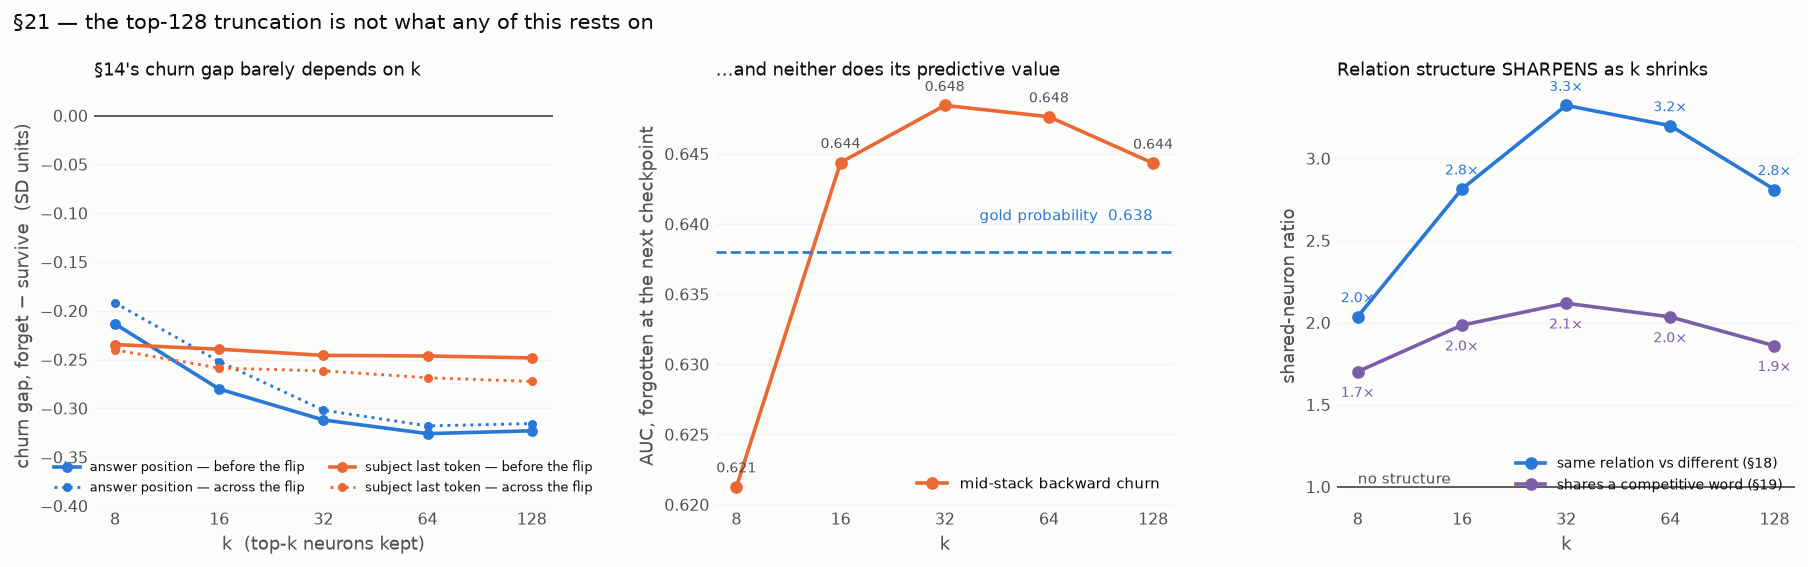

   k  gap bwd (ans)  gap bwd (subj)  AUC bwd  within-gp rho  same/diff rel  comp-word
   8         -0.213          -0.235    0.621          0.131          2.04x      1.70x
  16         -0.280          -0.239    0.644          0.145          2.81x      1.98x
  32         -0.312          -0.246    0.648          0.146          3.32x      2.12x
  64         -0.326          -0.246    0.648          0.144          3.20x      2.03x
 128         -0.323          -0.248    0.644          0.141          2.81x      1.86x
     (gold probability alone: AUC 0.638, within-gold-prob rho +0.065)


In [32]:
# §21a — does the forgetting signal (§§14, 16) live in the core or in the tail?
from scipy.stats import spearmanr

gap_conc = {p: [np.nanmean(kchurn[p][k][XF, XT][XFG]) - np.nanmean(kchurn[p][k][XF, XT][~XFG])
                for k in KS] for p in kchurn}
gap_back = {p: [np.nanmean(kchurn[p][k][AF, AT - 1][AFG]) - np.nanmean(kchurn[p][k][AF, AT - 1][~AFG])
                for k in KS] for p in kchurn}
auc_back = [auc1(-kchurn["answer"][k][AF, AT - 1], AFG) for k in KS]
_gpa = P["gold_prob"].to_numpy()[AF, AT]
auc_gp = auc1(-_gpa, AFG)
_gq = pd.qcut(_gpa, 5, labels=False, duplicates="drop")
wrho_back = [np.nanmean([spearmanr(-kchurn["answer"][k][AF, AT - 1][_gq == g], AFG[_gq == g])[0]
                         for g in range(_gq.max() + 1) if (_gq == g).sum() > 50]) for k in KS]

_x = np.arange(len(KS))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.4))

for p, col, lab in (("answer", BLUE, "answer position"), ("subject_last", ORANGE, "subject last token")):
    ax1.plot(_x, gap_back[p], color=col, lw=2, marker="o", ms=5, label=f"{lab} — before the flip")
    ax1.plot(_x, gap_conc[p], color=col, lw=1.6, ls=":", marker="o", ms=4,
             label=f"{lab} — across the flip")
ax1.axhline(0, color=INK2, lw=1)
ax1.set_xticks(_x, [str(k) for k in KS])
ax1.set_xlabel("k  (top-k neurons kept)")
ax1.set_ylabel("churn gap, forget − survive  (SD units)")
ax1.set_ylim(-.40, .03)
ax1.set_title("§14's churn gap barely depends on k", loc="left", fontsize=10)
ax1.legend(loc="lower center", ncol=2, fontsize=7)

ax2.plot(_x, auc_back, color=ORANGE, lw=2, marker="o", ms=6, label="mid-stack backward churn")
ax2.axhline(auc_gp, color=BLUE, ls="--", lw=1.5)
ax2.text(len(KS) - 1, auc_gp + .002, f"gold probability  {auc_gp:.3f}", ha="right",
         fontsize=8.5, color=BLUE, va="bottom")
for i, v in enumerate(auc_back):
    ax2.annotate(f"{v:.3f}", (i, v), fontsize=8, color=INK2, ha="center",
                 xytext=(0, 8), textcoords="offset points")
ax2.set_xticks(_x, [str(k) for k in KS])
ax2.set_xlabel("k")
ax2.set_ylabel("AUC, forgotten at the next checkpoint")
ax2.set_title("…and neither does its predictive value", loc="left", fontsize=10)
ax2.legend(loc="lower right", fontsize=8.5)

_w = [np.nanmean(_kov_pair[k][pair_same_prop]) / np.nanmean(_kov_pair[k][~pair_same_prop]) for k in KS]
_c = [np.nanmean(_kov_pair[k][pair_same_word]) / np.nanmean(_kov_pair[k][~pair_same_word]) for k in KS]
ax3.plot(_x, _w, color=BLUE, lw=2, marker="o", ms=6, label="same relation vs different (§18)")
ax3.plot(_x, _c, color=PURPLE, lw=2, marker="o", ms=6, label="shares a competitive word (§19)")
ax3.axhline(1, color=INK2, lw=1)
ax3.text(0, 1.02, "no structure", fontsize=8.5, color=INK2)
for i, (a, b) in enumerate(zip(_w, _c)):
    ax3.annotate(f"{a:.1f}×", (i, a), fontsize=8, color=BLUE, ha="center",
                 xytext=(0, 8), textcoords="offset points")
    ax3.annotate(f"{b:.1f}×", (i, b), fontsize=8, color=PURPLE, ha="center",
                 xytext=(0, -14), textcoords="offset points")
ax3.set_xticks(_x, [str(k) for k in KS])
ax3.set_xlabel("k")
ax3.set_ylabel("shared-neuron ratio")
ax3.set_title("Relation structure SHARPENS as k shrinks", loc="left", fontsize=10)
ax3.legend(loc="lower right", fontsize=8)

for ax in (ax1, ax2, ax3):
    ax.set_axisbelow(True); ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§21 — the top-128 truncation is not what any of this rests on",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{'k':>4s} {'gap bwd (ans)':>14s} {'gap bwd (subj)':>15s} {'AUC bwd':>8s} "
      f"{'within-gp rho':>14s} {'same/diff rel':>14s} {'comp-word':>10s}")
for i, k in enumerate(KS):
    print(f"{k:4d} {gap_back['answer'][i]:14.3f} {gap_back['subject_last'][i]:15.3f} "
          f"{auc_back[i]:8.3f} {wrho_back[i]:14.3f} {_w[i]:13.2f}x {_c[i]:9.2f}x")
print(f"     (gold probability alone: AUC {auc_gp:.3f}, within-gold-prob rho "
      f"{np.nanmean([spearmanr(-_gpa[_gq == g], AFG[_gq == g])[0] for g in range(_gq.max()+1) if (_gq==g).sum()>50]):+.3f})")

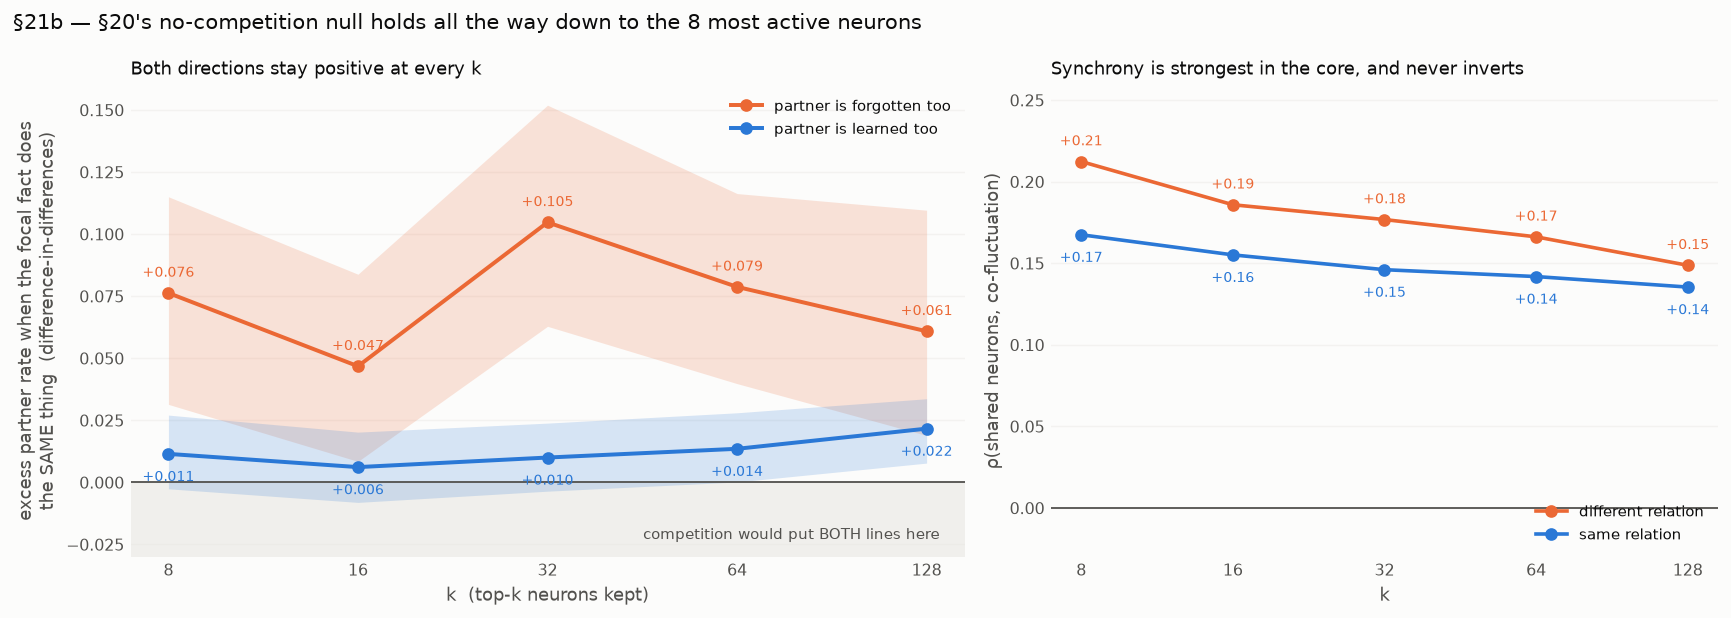

raw near − far partner rate (the quantity §20 reported), by k:
                                           k=8      k=16      k=32      k=64     k=128
  fact forgotten / partner forgotten    +0.113    +0.136    +0.094    +0.053    +0.051
    fact forgotten / partner learned    -0.115    -0.054    -0.037    -0.033    +0.001
    fact learned / partner forgotten    +0.037    +0.089    -0.011    -0.025    -0.010
      fact learned / partner learned    -0.104    -0.048    -0.027    -0.019    +0.023

difference-in-differences: excess partner rate when the focal fact does the SAME
thing (composition offset removed), 95% CI over events:
                   partner forgotten    +0.076*    +0.047*    +0.105*    +0.079*    +0.061*
                     partner learned    +0.011     +0.006     +0.010     +0.014*    +0.022*
  (* = 95% bootstrap CI excludes 0;  competition requires negative values)


In [33]:
# §21b — the test that most needs this: could a small contested core be hiding under
#         a synchronised tail?  Rerun §20's near/far comparison at every k.
#
# One complication only shows up at small k.  Ranking partners by an overlap that is
# mostly 0 (at k = 8 the median pair shares no neuron at all) picks a "nearest" set that
# differs from the "farthest" set in *composition*, not just in overlap -- at k = 8 the
# near partners are simply facts that are learned less and forgotten more, whatever the
# focal fact does.  That offset is constant across the focal fact's own outcome, so the
# clean statistic is a difference-in-differences: how much more often a partner shows an
# outcome when the focal fact shows the SAME outcome than when it shows the opposite one.
# Signed that way, synchrony is positive for both partner outcomes and competition is
# negative for both -- the two hypotheses cannot both be right, and neither is a level.
_rng = np.random.default_rng(0)
raw = np.zeros((2, 2, len(KS)))            # [focal outcome, partner outcome, k]
did = np.zeros((2, len(KS))); did_lo = np.zeros_like(did); did_hi = np.zeros_like(did)
k_cof = {"same relation": [], "different relation": []}
FOCAL = [("forgotten", ev_forget), ("learned", ev_learn)]
PARTNER = [("forgotten", ev_forget), ("learned", ev_learn)]

for j, k in enumerate(KS):
    Ok = np.where(same_prop | np.isnan(kOV[k]), np.nan, kOV[k])
    near = np.argsort(np.nan_to_num(Ok, nan=-1), 1)[:, ::-1][:, :NBR_M]
    far = np.argsort(np.nan_to_num(Ok, nan=1e9), 1)[:, :NBR_M]
    cell = {}
    for fi, (_, ev) in enumerate(FOCAL):
        for pi, (_, out) in enumerate(PARTNER):
            a, b = neighbour_rate(ev, near, out), neighbour_rate(ev, far, out)
            cell[(fi, pi)] = (a, b)
            raw[fi, pi, j] = a.mean() - b.mean()
    for pi in (0, 1):
        sgn = 1 if pi == 0 else -1          # "same outcome as the focal fact" is row 0
        did[pi, j] = sgn * (raw[0, pi, j] - raw[1, pi, j])
        bs = []
        for _ in range(300):
            g = [(_rng.choice(x, x.size).mean() - _rng.choice(y, y.size).mean())
                 for x, y in (cell[(0, pi)], cell[(1, pi)])]
            bs.append(sgn * (g[0] - g[1]))
        did_lo[pi, j], did_hi[pi, j] = np.percentile(bs, [2.5, 97.5])
    ov_k = kOV[k][_iu]
    for lab, m in (("same relation", pair_ok & pair_same_prop),
                   ("different relation", pair_ok & ~pair_same_prop)):
        k_cof[lab].append(spearmanr(ov_k[m], cof_glob[m])[0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.8),
                               gridspec_kw={"width_ratios": [1.25, 1]})
_x = np.arange(len(KS))
for pi, (col, lab) in enumerate(((ORANGE, "partner is forgotten too"),
                                 (BLUE, "partner is learned too"))):
    ax1.fill_between(_x, did_lo[pi], did_hi[pi], color=col, alpha=.18, linewidth=0)
    ax1.plot(_x, did[pi], color=col, lw=2.2, marker="o", ms=6, label=lab)
    for i, v in enumerate(did[pi]):
        ax1.annotate(f"{v:+.3f}", (i, v), fontsize=7.5, color=col, ha="center",
                     xytext=(0, 9 if pi == 0 else -15), textcoords="offset points")
ax1.axhline(0, color=INK2, lw=1)
ax1.set_ylim(min(did_lo.min(), -.02) * 1.5, None)
ax1.axhspan(ax1.get_ylim()[0], 0, color=NEUTRAL, zorder=0)
ax1.annotate("competition would put BOTH lines here", (0.97, .03),
             xycoords="axes fraction", fontsize=8.5, color=INK2, ha="right", va="bottom")
ax1.set_xticks(_x, [str(k) for k in KS])
ax1.set_xlabel("k  (top-k neurons kept)")
ax1.set_ylabel("excess partner rate when the focal fact does\nthe SAME thing  (difference-in-differences)")
ax1.set_title("Both directions stay positive at every k", loc="left", fontsize=10)
ax1.legend(loc="upper right", fontsize=8.5)

for lab, col in (("different relation", ORANGE), ("same relation", BLUE)):
    ax2.plot(_x, k_cof[lab], color=col, lw=2, marker="o", ms=6, label=lab)
    for i, v in enumerate(k_cof[lab]):
        ax2.annotate(f"{v:+.2f}", (i, v), fontsize=7.5, color=col, ha="center",
                     xytext=(0, 9 if lab.startswith("different") else -15),
                     textcoords="offset points")
ax2.axhline(0, color=INK2, lw=1)
ax2.set_ylim(-.03, max(max(v) for v in k_cof.values()) * 1.22)
ax2.set_xticks(_x, [str(k) for k in KS])
ax2.set_xlabel("k")
ax2.set_ylabel("ρ(shared neurons, co-fluctuation)")
ax2.set_title("Synchrony is strongest in the core, and never inverts", loc="left", fontsize=10)
ax2.legend(loc="lower right", fontsize=8.5)

for ax in (ax1, ax2):
    ax.set_axisbelow(True); ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("§21b — §20's no-competition null holds all the way down to the 8 most active neurons",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("raw near − far partner rate (the quantity §20 reported), by k:")
print(f"{'':>36s} " + " ".join(f"{'k=' + str(k):>9s}" for k in KS))
for fi, (fl, _) in enumerate(FOCAL):
    for pi, (pl, _) in enumerate(PARTNER):
        print(f"{'fact ' + fl + ' / partner ' + pl:>36s} "
              + " ".join(f"{raw[fi, pi, j]:+9.3f}" for j in range(len(KS))))
print("\ndifference-in-differences: excess partner rate when the focal fact does the SAME")
print("thing (composition offset removed), 95% CI over events:")
for pi, (pl, _) in enumerate(PARTNER):
    print(f"{'partner ' + pl:>36s} " + " ".join(
        f"{did[pi, j]:+9.3f}{'*' if not (did_lo[pi, j] < 0 < did_hi[pi, j]) else ' '}"
        for j in range(len(KS))))
print("  (* = 95% bootstrap CI excludes 0;  competition requires negative values)")

**Result — nothing in §§13–20 is an artefact of k = 128, and the structure is if
anything sharper in the core.**

| | k = 8 | k = 16 | k = 32 | k = 64 | k = 128 |
|---|---|---|---|---|---|
| §14 churn gap, answer (SD) | −0.213 | −0.280 | −0.312 | −0.326 | −0.323 |
| §14 churn gap, subject (SD) | −0.235 | −0.239 | −0.246 | −0.246 | −0.248 |
| §16 AUC of backward churn | 0.621 | 0.644 | **0.648** | **0.648** | 0.644 |
| … ρ within gold-prob. quintiles | +0.131 | +0.145 | **+0.146** | +0.144 | +0.141 |
| §18 same- vs cross-relation overlap | 2.0× | 2.8× | **3.3×** | 3.2× | 2.8× |
| §19 competitive-word overlap | 1.7× | 2.0× | **2.1×** | 2.0× | 1.9× |

Three things follow.

**The forgetting signal is not in the tail.** The churn gap and its AUC are flat from
k = 16 up and peak at **k = 32–64**, not at 128 — every setting from 16 up beats
`gold_prob` (0.638) on its own, and every setting including k = 8 beats it *within*
gold-probability strata (+0.13 to +0.15 against `gold_prob`'s own +0.065). Only k = 8 is
genuinely worse (AUC 0.621), which is the expected shape: the mid-stack participation
ratio is 33–77 effective neurons (§13), so 8 clips a representation that really is
distributed over dozens of units. The subject position is even flatter — its gap is
within 0.013 SD across the whole range.

**Relation structure is a core phenomenon.** §18's same-vs-cross ratio *rises* from 2.0×
at k = 8 to **3.3× at k = 32** before falling back to 2.8× at 128, and §19's
competitive-word ratio does the same (1.7× → 2.1× → 1.9×). So the tail between rank 32
and rank 128 is comparatively *generic* — it dilutes relation identity rather than
carrying it. **k = 128 understates §18 and §19; k = 32 would have been the stronger
choice** for those two sections.

**And §20's null is not a truncation artefact.** The raw near−far gaps do move with k —
at k = 8 they range from +0.113 to −0.115 — but that is the composition effect described
above, and it is present whichever way the focal fact goes. The difference-in-differences
is stable and positive at **every** k:

| difference-in-differences | k = 8 | k = 16 | k = 32 | k = 64 | k = 128 |
|---|---|---|---|---|---|
| partner is forgotten too | +0.076* | +0.047* | +0.105* | +0.079* | +0.061* |
| partner is learned too | +0.011 | +0.006 | +0.010 | +0.014* | +0.022* |

*(\* = 95% bootstrap CI over events excludes 0.)* Competition requires **negative**
values here, and there are none — not at k = 8, where the analysis sees only each fact's
eight most active neurons. The co-fluctuation correlation tells the same story from the
other end: it is **strongest at k = 8** (+0.21 cross-relation, +0.17 same-relation) and
decays monotonically to +0.15 / +0.14 at k = 128.

So the honest summary is stronger than §20's own caveat allowed: **there is no contested
core.** The eight neurons a fact drives hardest are the ones it shares its fate on most
tightly. The one genuine limit that remains is temporal, not spatial — interference that
resolves inside a single 50k-step interval is invisible at any k, and only a denser
checkpoint grid or §11d's activation patching can reach it.

## 22 — What Part III added

Nine sections, and the through-line is that **the mid-stack is where a fact lives, how
it is lost, and who it is lost with**, shown from the activations rather than through
the output projection.

*How a fact is stored and lost (§§13–17).*

1. **A map (§13).** Layers 8–13 hold each fact's sparsest and most private units and
   are the least stable region of the network. §8 reached the same band through the
   logit lens; §14 found the deepest backward-churn gap at MLP layer 11, which is
   exactly §8's boundary-12 peak.
2. **Instability precedes loss (§14).** A fact about to be forgotten was already
   churning during the *previous* interval (ρ = +0.213, and +0.131 within
   gold-probability terciles, where `gold_prob` itself manages +0.056). The subject
   position destabilises one processing stage earlier than the answer position — the
   Geva et al. (2023) pipeline failing in order.
3. **Storage shape tracks correctness (§15).** Correct recall means fewer effective
   neurons above layer 8 (52 vs 60) on units that are *shared* early and *private*
   late. The knowledge-entropy-decay claim does not replicate here in the form its name
   suggests.
4. **They carry information the output does not (§16).** Neuron features alone reach
   CV AUC 0.711 against 0.680 for all four output scalars, and 0.739 combined — the
   positive counterpart to §10's proof-by-elimination.
5. **Recovery is a rebuild (§17).** A relearned fact shows no pull toward its
   pre-forgetting circuit (AUC 0.509, chance).

*Who a fact shares its neurons with (§§18–20).*

6. **Relations own the mid-stack (§18).** Same-relation facts share 3.4× more top-128
   neurons than cross-relation facts at layer 8, peaking in the same band as everything
   else in this part. The relation-level link from outward sharing to hazard (ρ = +0.52)
   is real but confounded with exposure (ρ = −0.76), and 8 relations cannot separate them.
7. **§12's competition variable is a neuron-level fact (§19).** Pairs sharing a
   `competitive_word` share 1.86× more mid-stack neurons, and the same ratio holds
   across relation boundaries. But crowding itself is a weak predictor once confidence
   is controlled (+0.041) and is half-explained by exposure — crowded facts are mostly
   rare facts. Crowding by the fact's *own* relation is mildly protective, which is the
   sign superposition predicts.
8. **And yet nothing competes (§20).** Facts that share mid-stack neurons are *more*
   synchronised, monotonically (correlation +0.12 → +0.48 across overlap deciles), and
   at the moment of a flip their nearest cross-relation partners are more likely to be
   forgotten with them (+0.051) and learned with them (+0.023) while the two
   opposite-direction cells are flat. The classical overlap→interference prediction
   (French 1999) does not hold here.

*Is any of it an artefact of the truncation (§21)?*

9. **No, and k = 128 was the conservative choice.** Rerunning at k = 8…128: the churn
   gap and its AUC peak at **k = 32–64** and are flat from 16 up; the relation and
   competitive-word overlap ratios are *stronger* in the core (3.3× and 2.1× at k = 32)
   than at 128; and §20's no-competition result holds at every k, including k = 8, once
   the small-k composition offset is removed by a difference-in-differences. Only k = 8
   degrades the forgetting signal, exactly as a 33–77 effective-neuron representation
   (§13) predicts it should.

**Where this leaves the thesis.** Forgetting in LMEnt is not erasure and not a contest.
It is a **shared mid-stack circuit being continuously retuned**, with each fact's
survival depending on how sharply and how privately it happens to be written into that
circuit at the moment — which is why weak storage predicts loss (§§2, 5), why churn
predicts it better (§14, §16), why relearning does not restore anything (§17), and why
neuron-mates rise and fall together (§20, §21).

**What would sharpen this, in order of value per unit of work.**

- **§11a, still first.** None of this says *why* the churn happens at that checkpoint.
  `src/schedule.py::build_chunk_to_steps()` maps each fact's supporting chunks to exact
  optimizer steps; regressing backward churn on steps-since-last-exposure and on
  interfering appearances would turn "it was already moving" into "it was moving because
  nothing reinforced it since step *s*". §20 raises the stakes: if neuron-mates share a
  fate, the natural unit of analysis is the *group's* exposure, not the fact's.
- **A denser checkpoint grid.** §21 closed the spatial loophole in §20's null but not
  the temporal one: interference that resolves inside a single 50k-step interval is
  invisible at any k. Re-running `eval_checkpoints.py` on a 10k grid over one interval
  where many facts flip would be the cheapest way to look.
- **Exposure-matched partners in §20.** The near/far control fixes the relation and the
  checkpoint but not the exposure; matching partners on exposure decile would remove the
  last plausible confound in the +0.051.
- **§11d, activation patching.** Everything here is correlational. §14 names a target
  (MLP layers 8–11 at the answer position, 3–8 at the subject position) and §20 names a
  second experiment: patch a fact's mid-stack activations and check whether its
  neuron-mates' answers move with it. That is the causal version of this entire section.